# AURA: Complete Colab Project and Data Explorer
### Team: Puspita and Farhat

**Research decision (October 30, 2026):** retain the **Cost-aware gate** as AURA's main research policy. Confidence and the plain signed gate remain essential comparators. New evidence, cost-tilted and blending methods remain exploratory; retention is not a claim of uniform superiority. Saved results and executable defaults are unchanged.

This notebook runs **four classification models and all implemented AURA routing variants**:

Directions to run this notebook:

**Colab setup:** choose **Runtime > Change runtime type > T4 GPU** (or another GPU),
then run the cells in order. A GPU is strongly recommended for five-epoch fine-tuning.
For a presentation, train beforehand with Google Drive storage enabled; reuse the
checkpoints to run inference, charts, and the demonstration live. Initial training
is not an eight-minute presentation task.

AURA is evaluated on **both DistilBERT and Ettin-150M**, with a separate temperature
and correctness gates for each encoder. Historical DistilBERT results remain unchanged.
This new encoder comparison is exploratory; we do not select a classifier from
official-test results and then claim fresh independent confirmation.

Upload the accompanying `aura_project_spec.json` when prompted in section 3; it
contains the original split and workflow specification. No repository clone,
development tools, or unit-test suite is required. All results are computed by this
run; the notebook does not substitute the historical slide numbers for new results.

The full notebook includes the implemented research workflows, not the abandoned agentic/conformal proposals from early plans. All models and gates are fitted from their declared partitions. Model files and original data are downloaded at runtime; no Mac-specific paths or repository checkout are required.

**Data access:** section 4B lets you browse all rows, search messages and see every label. Prepared CSVs are saved in the run data folder. **Demo preparation:** train before presenting and use checkpoint reuse for live inference. Bootstrap comparisons use 10,000 resamples and can be prepared ahead of the presentation.

## 1. Install runtime dependencies

Colab already provides PyTorch. We retain its CUDA-enabled installation and install
the packages used below. Run this cell before importing the packages. If Colab
requests a session restart after installation, restart and continue from this cell.

In [2]:
!pip -q install "transformers==4.57.1" "huggingface-hub==0.36.0" "gradio==6.12.0" "gradio-client==2.4.1" "scikit-learn>=1.7,<1.10" "scipy>=1.14,<2" "pandas>=2.2,<4" "numpy>=1.26,<3" "matplotlib>=3.8,<4" "joblib>=1.4,<2" "tqdm>=4.66,<5" "ipywidgets>=8,<9"

In [3]:
import gc
import hashlib
import json
import math
import random
import shutil
import time
from datetime import datetime, timezone
from decimal import Decimal, ROUND_FLOOR
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
import torch
import transformers
from IPython.display import display
from scipy.optimize import minimize_scalar
from scipy.special import logsumexp, softmax
from sklearn.decomposition import TruncatedSVD
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, log_loss
from sklearn.pipeline import Pipeline
from torch.optim import AdamW
from torch.utils.data import DataLoader, TensorDataset
from tqdm.auto import tqdm
from transformers import (
    AutoConfig, AutoModelForSequenceClassification, AutoTokenizer,
    get_linear_schedule_with_warmup,
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("CPU runtime: select a Colab GPU before fine-tuning for practical training speed.")

VERSIONS = {"torch": torch.__version__, "transformers": transformers.__version__,
            "sklearn": sklearn.__version__, "numpy": np.__version__,
            "pandas": pd.__version__, "scipy": scipy.__version__}
display(pd.Series(VERSIONS, name="runtime_version").to_frame())
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False,
                     "axes.spines.right": False})

Device: cuda
GPU: Tesla T4


,runtime_version
torch,2.11.0+cu130
transformers,4.57.1
sklearn,1.9.1
numpy,2.1.3
pandas,2.2.3
scipy,1.16.3


## 2. Configure training and checkpoint storage

Keep **five epochs** for the intended experiment. A shorter run is only a rehearsal
and will not reproduce the five-epoch model. Set `USE_GOOGLE_DRIVE = True` before
training if you want checkpoints to survive a Colab disconnect. Colab's `/content`
storage is temporary. `REUSE_CHECKPOINTS` loads compatible saved models on later runs.

Checkpoints are tied to the data, training split, settings, and key library versions.
Use only checkpoints you created or trust: Python joblib files can execute code.

Ettin-150M uses batch size 8 and four accumulation steps, while DistilBERT uses
16 and two: both have nominal effective batch size 32. They share five epochs,
maximum length 128, and learning rate 4e-5. This is a controlled training-budget
comparison, not a claim that this learning rate is optimal for both models.
The transformers train and predict sequentially, moving inactive models to CPU.

In [4]:
USE_GOOGLE_DRIVE = True
REUSE_CHECKPOINTS = True
RUN_OFFICIAL_TEST = True

TRAINING_CONFIG = {
    "model_name": "distilbert/distilbert-base-uncased",
    "epochs": 5, "batch_size": 16, "gradient_accumulation_steps": 2,
    "maximum_length": 128, "learning_rate": 4e-5,
    "weight_decay": 0.01, "warmup_ratio": 0.1,
    "gradient_clip_norm": 1.0, "seed": SEED,
}
ETTIN_CONFIG = {
    **TRAINING_CONFIG,
    "model_name": "jhu-clsp/ettin-encoder-150m",
    "batch_size": 8, "gradient_accumulation_steps": 4,
    "attn_implementation": "eager", "reference_compile": False,
}

if USE_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    STORAGE_ROOT = Path("/content/drive/MyDrive/AURA_Colab_Demo")
else:
    STORAGE_ROOT = Path("/content/AURA_Colab_Demo")

RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
RESULT_DIR = STORAGE_ROOT / "runs" / RUN_ID
RESULT_DIR.mkdir(parents=True, exist_ok=False)
print("This run's tables and figures:", RESULT_DIR)

Mounted at /content/drive
This run's tables and figures: /content/drive/MyDrive/AURA_Colab_Demo/runs/20261026T233822598428Z


## 3. Load the project specification

Upload **`aura_project_spec.json`** from your computer when this cell opens the
Colab file picker. If you already uploaded it through Colab's Files sidebar,
the cell loads it directly. Keep the original filename. Outside Colab, place
the JSON file in the notebook's working directory.

The file contains the original **77-intent workflow map**, cost scenarios, and
saved development-split row IDs. Labels use the explicit project mapping, including exact
capitalization, rather than inferred from a dataset's numeric encoding.

The workflow map is source-informed internal research work. The numerical cost
ratios and maximum-floor rule are scenario assumptions, without external banking
validation. This notebook preserves the first implementation.

In [5]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [6]:
SPEC_PATH = Path("aura_project_spec.json")
if not SPEC_PATH.is_file():
    try:
        from google.colab import files
    except ImportError as exc:
        raise FileNotFoundError(
            "Place aura_project_spec.json in the notebook's working directory."
        ) from exc
    print("Please upload aura_project_spec.json.")
    files.upload()
    if not SPEC_PATH.is_file():
        raise FileNotFoundError("Upload the file named aura_project_spec.json and rerun this cell.")

with SPEC_PATH.open(encoding="utf-8") as file:
    PROJECT_SPEC = json.load(file)

WORKFLOWS = sorted(PROJECT_SPEC["workflow_specification"]["workflows"], key=lambda w: w["label"])
INTENTS = [w["intent"] for w in WORKFLOWS]
LABEL_TO_ID = {name: i for i, name in enumerate(INTENTS)}
NUM_CLASSES = len(INTENTS)
print(f"Loaded {NUM_CLASSES} intents and the original development split from {SPEC_PATH.name}.")

Please upload aura_project_spec.json.


Saving aura_project_spec.json to aura_project_spec.json
Loaded 77 intents and the original development split from aura_project_spec.json.


## 4. Download BANKING77 and prepare the data

The original files contain `text` and `category`. We convert category names to our
canonical labels and preserve row order. The **10,003-message training pool** supplies
all training, calibration, and development-validation data. The **3,080-message
official test partition** is evaluated later and never used to fit models or temperature.

We preserve the original text and examples. TF-IDF handles its own lowercasing;
DistilBERT uses its tokenizer. We do not remove stopwords, stem messages, or delete
duplicates because those changes would alter the original experiment.

Source: [PolyAI's BANKING77 repository](https://github.com/PolyAI-LDN/task-specific-datasets/tree/master/banking_data).

In [7]:
DATA_URL = "https://raw.githubusercontent.com/PolyAI-LDN/task-specific-datasets/master/banking_data"

def prepare_frame(raw):
    frame = raw.rename(columns={"category": "label_text"}).copy()
    if not {"text", "label_text"}.issubset(frame.columns):
        raise ValueError("Expected text and category/label_text columns.")
    if frame[["text", "label_text"]].isna().any().any():
        raise ValueError("The downloaded data contains missing text or labels.")
    unknown = set(frame["label_text"]) - set(LABEL_TO_ID)
    if unknown:
        raise ValueError(f"Unknown intent names: {unknown}")
    frame["label"] = frame["label_text"].map(LABEL_TO_ID).astype("int64")
    frame["row_id"] = np.arange(len(frame), dtype=np.int64)
    return frame[["row_id", "text", "label", "label_text"]]

train_pool = prepare_frame(pd.read_csv(f"{DATA_URL}/train.csv"))

# generates a unique SHA-256 hash (or "fingerprint") representing the text data and labels in a pandas DataFrame.
def training_fingerprint(frame):
    records = frame[["text", "label_text"]].astype(str).values.tolist()
    return hashlib.sha256(json.dumps(records, ensure_ascii=False,
                                     separators=(",", ":")).encode()).hexdigest()

DATA_FINGERPRINT = training_fingerprint(train_pool)
if DATA_FINGERPRINT != PROJECT_SPEC["expected_training_fingerprint"]:
    raise ValueError("Training content/order differs from the original AURA data; stop before using its saved row split.")
split_ids = PROJECT_SPEC["split_ids"]
train_df = train_pool.iloc[split_ids["model_training"]].copy()
cal_df = train_pool.iloc[split_ids["calibration"]].copy()
val_df = train_pool.iloc[split_ids["policy_validation"]].copy()

display(pd.DataFrame({"partition": ["model_training", "calibration", "policy_validation"],
                      "messages": [len(train_df), len(cal_df), len(val_df)],
                      "intents": [f.label.nunique() for f in [train_df, cal_df, val_df]]}))
display(train_df.head(5))

signature_payload = {"data": DATA_FINGERPRINT, "split": split_ids,
                     "training": TRAINING_CONFIG, "versions": VERSIONS}
SIGNATURE = hashlib.sha256(json.dumps(signature_payload, sort_keys=True).encode()).hexdigest()
CHECKPOINT_DIR = STORAGE_ROOT / "checkpoints" / SIGNATURE[:16]
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
(CHECKPOINT_DIR / "run_configuration.json").write_text(
    json.dumps(signature_payload, indent=2), encoding="utf-8")
print("Compatible checkpoints:", CHECKPOINT_DIR)

,partition,messages,intents
0,model_training,7002,77
1,calibration,1500,77
2,policy_validation,1501,77


,row_id,text,label,label_text
0,0,I am still waiting on my card?,11,card_arrival
1,1,What can I do if my card still hasn't arrived ...,11,card_arrival
5,5,When did you send me my new card?,11,card_arrival
6,6,Do you have info about the card on delivery?,11,card_arrival
7,7,What do I do if I still have not received my n...,11,card_arrival


Compatible checkpoints: /content/drive/MyDrive/AURA_Colab_Demo/checkpoints/651a2d9e08afced1


### 4B. See and search the actual data

Use the browser to inspect **every row** through pages, filter by intent or search
the message text. It includes the full training pool and each development partition.
The official test data becomes available here after its evaluation section runs.
Every table preserves the original `row_id` and complete text. A label number is
just an index into the intent-name mapping, not a severity score.

The second cell shows dataset shape, missing values, duplicate membership, message
length, all 77 labels, and normalized-text overlap. No rows are removed from the
original comparison. Prepared data is also saved as CSV in this run's `data/` folder.

In [8]:
import ipywidgets as widgets

DATA_TABLES = {"Training pool (all 10,003)": train_pool,
               "Model training": train_df, "Calibration": cal_df,
               "Policy validation": val_df}
DATA_DIR = RESULT_DIR / "data"
DATA_DIR.mkdir(exist_ok=True)
for name, frame in [("training_pool", train_pool), ("model_training", train_df),
                    ("calibration", cal_df), ("policy_validation", val_df)]:
    frame.to_csv(DATA_DIR / f"{name}.csv", index=False)

def get_data_page(partition, intent="All intents", query="", page=1, page_size=20):
    frame = DATA_TABLES[partition]
    if intent != "All intents":
        frame = frame[frame.label_text == intent]
    if query.strip():
        frame = frame[frame.text.str.contains(query.strip(), case=False, regex=False)]
    pages = max(1, math.ceil(len(frame) / page_size))
    current = min(max(1, int(page)), pages)
    start = (current - 1) * page_size
    return frame.iloc[start:start + page_size], len(frame), current, pages

partition_selector = widgets.Dropdown(options=list(DATA_TABLES), description="Partition:",
                                       layout=widgets.Layout(width="450px"))
intent_selector = widgets.Dropdown(options=["All intents", *INTENTS], description="Intent:",
                                    layout=widgets.Layout(width="550px"))
search_box = widgets.Text(description="Search:", placeholder="Message text", continuous_update=False)
page_selector = widgets.BoundedIntText(value=1, min=1, max=len(train_pool), description="Page:")
page_size_selector = widgets.Dropdown(options=[10, 20, 50, 100], value=20, description="Rows:")

def show_data_page(partition, intent, query, page, page_size):
    visible, total, current, pages = get_data_page(partition, intent, query, page, page_size)
    print(f"{total:,} matching rows | page {current:,} of {pages:,}")
    with pd.option_context("display.max_colwidth", None, "display.max_rows", page_size):
        display(visible)

data_browser = widgets.interactive_output(show_data_page, {
    "partition": partition_selector, "intent": intent_selector, "query": search_box,
    "page": page_selector, "page_size": page_size_selector})
display(widgets.VBox([partition_selector, intent_selector, search_box,
                      widgets.HBox([page_selector, page_size_selector]), data_browser]))

,partition,rows,intents,missing_values,normalized_duplicate_members,median_words
0,"Training pool (all 10,003)",10003,77,0,8,10.0
1,Model training,7002,77,0,4,10.0
2,Calibration,1500,77,0,0,10.0
3,Policy validation,1501,77,0,0,10.0


label,intent,training_pool_messages
0,activate_my_card,159
1,age_limit,110
2,apple_pay_or_google_pay,126
3,atm_support,87
4,automatic_top_up,127
5,balance_not_updated_after_bank_transfer,171
6,balance_not_updated_after_cheque_or_cash_deposit,181
7,beneficiary_not_allowed,156
8,cancel_transfer,157
9,card_about_to_expire,129


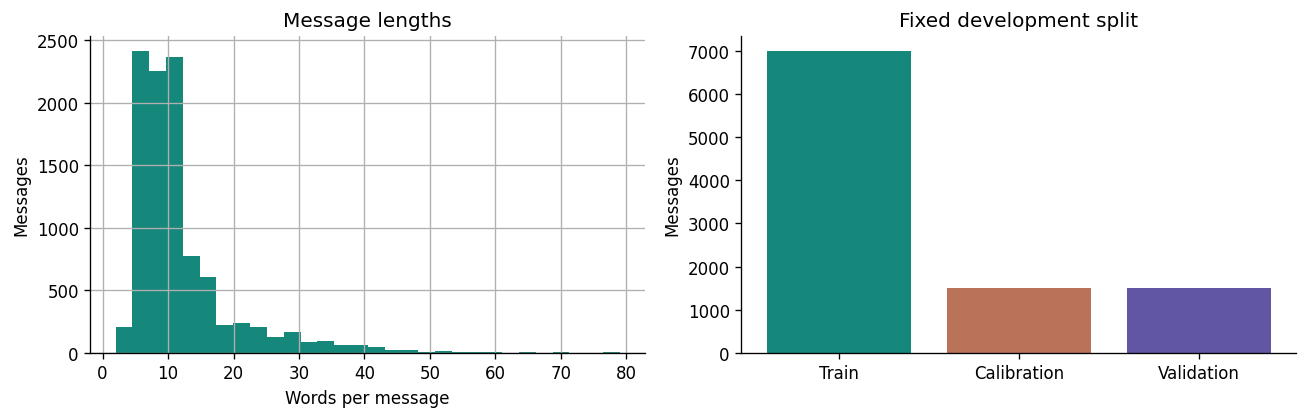

,partition,normalized_matches_to_model_training
0,calibration,1
1,policy_validation,1


In [9]:
def normalized_text(series):
    return series.str.lower().str.split().str.join(" ")

data_overview = []
for name, frame in DATA_TABLES.items():
    normalized = normalized_text(frame.text)
    data_overview.append({"partition": name, "rows": len(frame),
        "intents": frame.label.nunique(), "missing_values": int(frame.isna().sum().sum()),
        "normalized_duplicate_members": int(normalized.duplicated(keep=False).sum()),
        "median_words": float(frame.text.str.split().str.len().median())})
display(pd.DataFrame(data_overview))
label_inventory = pd.DataFrame({"label": range(NUM_CLASSES), "intent": INTENTS})
counts = train_pool.groupby("label").size()
label_inventory["training_pool_messages"] = label_inventory.label.map(counts)
display(label_inventory.style.hide(axis="index"))
label_inventory.to_csv(DATA_DIR / "label_inventory.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
train_pool.text.str.split().str.len().hist(bins=30, ax=axes[0], color="#16877b")
axes[0].set(xlabel="Words per message", ylabel="Messages", title="Message lengths")
axes[1].bar(["Train", "Calibration", "Validation"],
            [len(train_df), len(cal_df), len(val_df)], color=["#16877b", "#ba7359", "#6156a4"])
axes[1].set(ylabel="Messages", title="Fixed development split")
fig.tight_layout()
fig.savefig(RESULT_DIR / "data_overview.png", dpi=180)
plt.show()

training_texts = set(normalized_text(train_df.text))
overlap_audit = pd.DataFrame([
    {"partition": name, "normalized_matches_to_model_training":
        int(normalized_text(frame.text).isin(training_texts).sum())}
    for name, frame in [("calibration", cal_df), ("policy_validation", val_df)]])
display(overlap_audit)
overlap_audit.to_csv(RESULT_DIR / "development_overlap.csv", index=False)

## 5. Train the two classical classifiers

**Logistic Regression:** TF-IDF word unigrams and bigrams, followed by a regularized
multiclass classifier. The vectorizer is fitted on model-training text only.

**Random Forest:** the same TF-IDF settings, 256-dimensional Truncated SVD,
then 400 trees. SVD is also fitted on model-training text only.

These use the project's existing hyperparameters. We compare full pipelines,
including their representations, rather than claiming a classifier-only ablation.
The saved Random Forest can occupy substantial disk space.

In [10]:
def make_tfidf():
    return TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=2,
                           max_features=50_000, sublinear_tf=True)

def build_classical_models():
    return {
        "Logistic Regression": Pipeline([
            ("tfidf", make_tfidf()),
            ("classifier", LogisticRegression(C=1.0, class_weight="balanced",
                max_iter=1000, random_state=SEED, solver="lbfgs")),
        ]),
        "Random Forest": Pipeline([
            ("tfidf", make_tfidf()),
            ("svd", TruncatedSVD(n_components=256, n_iter=7, random_state=SEED)),
            ("classifier", RandomForestClassifier(n_estimators=400,
                criterion="log_loss", min_samples_leaf=2, max_features="sqrt",
                class_weight="balanced_subsample", n_jobs=-1, random_state=SEED)),
        ]),
    }

classical_models = build_classical_models()
training_records = []
for name, model in classical_models.items():
    path = CHECKPOINT_DIR / f"{name.lower().replace(' ', '_')}.joblib"
    start = time.perf_counter()
    reused = REUSE_CHECKPOINTS and path.exists()
    if reused:
        classical_models[name] = joblib.load(path)
    else:
        print(f"Training {name}...", flush=True)
        model.fit(train_df.text.tolist(), train_df.label.to_numpy())
        joblib.dump(model, path)
    elapsed = time.perf_counter() - start
    training_records.append({"model": name, "checkpoint_reused": reused,
                             "fit_or_load_seconds": elapsed})
    print(f"{name}: {'loaded' if reused else 'trained'} in {elapsed:.1f} seconds")

Training Logistic Regression...
Logistic Regression: trained in 5.4 seconds
Training Random Forest...
Random Forest: trained in 321.3 seconds


## 6. Fine-tune DistilBERT for 77 intents

We attach a 77-class head and update **the encoder and head together** for five epochs
using AdamW, learning rate $4\times10^{-5}$, maximum sequence length 128, and gradient
accumulation over two batches. The final epoch is retained; no validation-based
checkpoint search is performed. The classification-head initialization warning is
expected: that new head learns BANKING77 labels during fine-tuning.

The epoch progress bar is useful for preparation. On a subsequent run, a completed
compatible checkpoint is loaded immediately. Interrupted training starts over;
this notebook does not claim optimizer-state resume. Small GPU/library differences
can change results despite the same seed.

Model: [Sanh et al., DistilBERT](https://arxiv.org/abs/1910.01108).

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

... (3 outputs left out)

DistilBERT: epoch 3/5:   0%|          | 0/438 [00:00<?, ?it/s]

DistilBERT: epoch 4/5:   0%|          | 0/438 [00:00<?, ?it/s]

DistilBERT: epoch 5/5:   0%|          | 0/438 [00:00<?, ?it/s]

,model,checkpoint_reused,fit_or_load_seconds
0,Logistic Regression,False,5.396288
1,Random Forest,False,321.278033
2,DistilBERT,False,407.057318


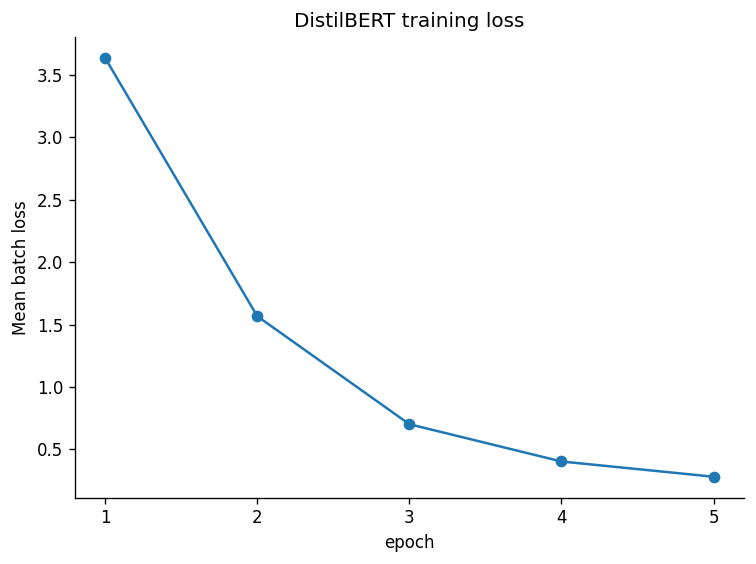

In [11]:
def encode_dataset(frame, tokenizer, maximum_length=128):
    encoded = tokenizer(frame.text.tolist(), padding="max_length", truncation=True,
                        max_length=maximum_length, return_tensors="pt")
    labels = torch.tensor(frame.label.to_numpy(), dtype=torch.long)
    return TensorDataset(encoded["input_ids"], encoded["attention_mask"], labels)

def train_or_load_transformer(name, config, model_dir, checkpoint_signature):
    start = time.perf_counter()
    completion_path = model_dir / "completed.json"
    reused = REUSE_CHECKPOINTS and completion_path.exists()
    model_options = ({"attn_implementation": config["attn_implementation"]}
                     if "attn_implementation" in config else {})
    source = model_dir if reused else config["model_name"]
    architecture_config = AutoConfig.from_pretrained(source)
    if "reference_compile" in config:
        architecture_config.reference_compile = config["reference_compile"]
    if reused:
        saved = json.loads(completion_path.read_text())
        if saved["signature"] != checkpoint_signature or saved["configuration"] != config:
            raise ValueError(f"{name} checkpoint does not match its requested settings.")
        fitted_tokenizer = AutoTokenizer.from_pretrained(model_dir)
        fitted_model = AutoModelForSequenceClassification.from_pretrained(
            model_dir, config=architecture_config, **model_options)
        history = saved["history"]
        print(f"Loaded completed {name} checkpoint.")
    else:
        random.seed(config["seed"])
        np.random.seed(config["seed"])
        torch.manual_seed(config["seed"])
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(config["seed"])
        fitted_tokenizer = AutoTokenizer.from_pretrained(config["model_name"])
        architecture_config.num_labels = NUM_CLASSES
        architecture_config.id2label = dict(enumerate(INTENTS))
        architecture_config.label2id = LABEL_TO_ID
        fitted_model = AutoModelForSequenceClassification.from_pretrained(
            config["model_name"], config=architecture_config, **model_options,
        ).to(DEVICE)
        dataset = encode_dataset(train_df, fitted_tokenizer, config["maximum_length"])
        loader = DataLoader(dataset, batch_size=config["batch_size"], shuffle=True,
                            generator=torch.Generator().manual_seed(config["seed"]))
        accumulation = config["gradient_accumulation_steps"]
        total_steps = math.ceil(len(loader) / accumulation) * config["epochs"]
        optimizer = AdamW(fitted_model.parameters(), lr=config["learning_rate"],
                          weight_decay=config["weight_decay"])
        scheduler = get_linear_schedule_with_warmup(
            optimizer, int(total_steps * config["warmup_ratio"]), total_steps)
        history = []
        for epoch in range(config["epochs"]):
            fitted_model.train()
            optimizer.zero_grad(set_to_none=True)
            total_loss, seen = 0.0, 0
            progress = tqdm(loader, desc=f"{name}: epoch {epoch + 1}/{config['epochs']}")
            for batch_index, (ids, mask, labels) in enumerate(progress):
                outputs = fitted_model(input_ids=ids.to(DEVICE), attention_mask=mask.to(DEVICE),
                                       labels=labels.to(DEVICE))
                loss = outputs.loss
                total_loss += float(loss.detach().cpu())
                seen += 1
                (loss / accumulation).backward()
                if (batch_index + 1) % accumulation == 0 or batch_index + 1 == len(loader):
                    torch.nn.utils.clip_grad_norm_(fitted_model.parameters(), config["gradient_clip_norm"])
                    optimizer.step()
                    scheduler.step()
                    optimizer.zero_grad(set_to_none=True)
                progress.set_postfix(loss=f"{total_loss / seen:.4f}")
            history.append({"epoch": epoch + 1, "mean_batch_loss": total_loss / seen})
        model_dir.mkdir(parents=True, exist_ok=True)
        if completion_path.exists():
            completion_path.unlink()
        fitted_model.save_pretrained(model_dir)
        fitted_tokenizer.save_pretrained(model_dir)
        completion_path.write_text(json.dumps({"signature": checkpoint_signature,
            "history": history, "configuration": config}, indent=2))
        del optimizer, scheduler, loader, dataset, outputs, loss
    fitted_model.eval().to("cpu")
    for parameter in fitted_model.parameters():
        parameter.requires_grad_(False)
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    record = {"model": name, "checkpoint_reused": reused,
              "fit_or_load_seconds": time.perf_counter() - start}
    return fitted_model, fitted_tokenizer, history, record

MODEL_DIR = CHECKPOINT_DIR / "distilbert"
model, tokenizer, training_history, distilbert_record = train_or_load_transformer(
    "DistilBERT", TRAINING_CONFIG, MODEL_DIR, SIGNATURE)
training_records.append(distilbert_record)
display(pd.DataFrame(training_records))
pd.DataFrame(training_history).plot(x="epoch", y="mean_batch_loss", marker="o",
                                  legend=False, title="DistilBERT training loss")
plt.ylabel("Mean batch loss")
plt.xticks(range(1, TRAINING_CONFIG["epochs"] + 1))
plt.tight_layout()
plt.show()

### 6B. Fine-tune Ettin-150M on the same training messages

**Ettin-150M** (`jhu-clsp/ettin-encoder-150m`) is a recent English bidirectional
encoder using the ModernBERT architecture. We replace its masked-language-model
head with a 77-class sequence-classification head and fine-tune the encoder and
head together. The new-head initialization warning is expected.

The experiment uses the same data, five epochs, sequence length, learning rate,
and nominal effective batch size as DistilBERT. This controls the training recipe;
it does not imply identical compute or an optimized recipe for Ettin.
Eager attention and disabled reference compilation avoid requiring FlashAttention
or Triton compilation. Inactive models stay on CPU to reduce GPU memory use.

Ettin has its own checkpoint signature, so changing its settings does not force
retraining existing DistilBERT or classical checkpoints. **Ettin is compared as a
classifier; original AURA calibration and routing continue to use DistilBERT.**

Sources: [official model card](https://huggingface.co/jhu-clsp/ettin-encoder-150m),
[Seq vs Seq: An Open Suite of Paired Encoders and Decoders (2025)](https://arxiv.org/abs/2507.11412).

config.json: 0.00B [00:00, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/694 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/599M [00:00<?, ?B/s]

Some weights of ModernBertForSequenceClassification were not initialized from the model checkpoint at jhu-clsp/ettin-encoder-150m and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


... (3 outputs left out)

Ettin-150M: epoch 3/5:   0%|          | 0/876 [00:00<?, ?it/s]

Ettin-150M: epoch 4/5:   0%|          | 0/876 [00:00<?, ?it/s]

Ettin-150M: epoch 5/5:   0%|          | 0/876 [00:00<?, ?it/s]

,model,checkpoint_reused,fit_or_load_seconds
0,Logistic Regression,False,5.396288
1,Random Forest,False,321.278033
2,DistilBERT,False,407.057318
3,Ettin-150M,False,1244.750307


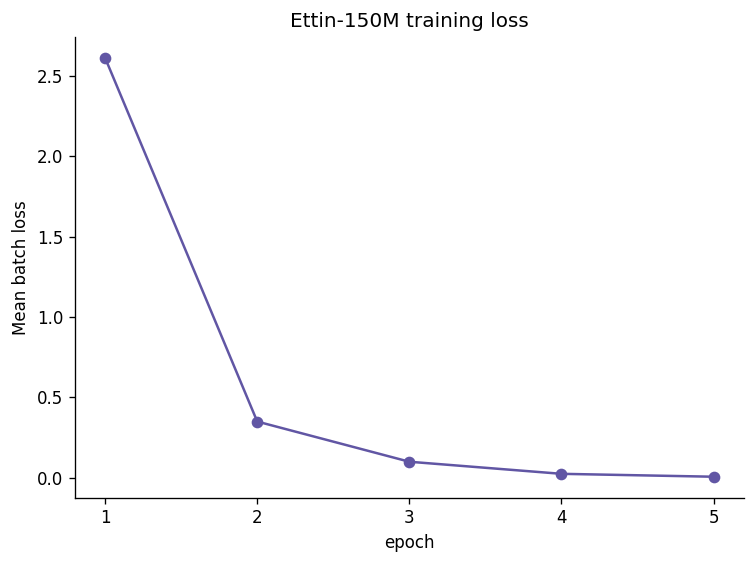

In [12]:
ETTIN_SIGNATURE = hashlib.sha256(json.dumps({"base_signature": SIGNATURE,
    "configuration": ETTIN_CONFIG}, sort_keys=True).encode()).hexdigest()
ETTIN_MODEL_DIR = CHECKPOINT_DIR / "ettin" / ETTIN_SIGNATURE[:16]
ettin_model, ettin_tokenizer, ettin_history, ettin_record = train_or_load_transformer(
    "Ettin-150M", ETTIN_CONFIG, ETTIN_MODEL_DIR, ETTIN_SIGNATURE)
training_records.append(ettin_record)
display(pd.DataFrame(training_records))
pd.DataFrame(ettin_history).plot(x="epoch", y="mean_batch_loss", marker="o",
                               legend=False, title="Ettin-150M training loss", color="#6156a4")
plt.ylabel("Mean batch loss")
plt.xticks(range(1, ETTIN_CONFIG["epochs"] + 1))
plt.tight_layout()
plt.show()

## 7. Compare classification results on development validation

All four models predict exactly the same 1,501 messages. Accuracy and macro-F1
measure label quality; log loss and Brier score assess probability quality.
ECE compares confidence with observed accuracy in 15 equal-width bins.
The chart shows this run's results. Saved historical presentation numbers need
not match a new GPU training run exactly.

Validation inference:   0%|          | 0/94 [00:00<?, ?it/s]

Ettin validation inference:   0%|          | 0/188 [00:00<?, ?it/s]

,model,accuracy,macro_f1,log_loss,ece,brier
0,Logistic Regression,0.8488,0.8496,1.4867,0.5190,0.5363
1,Random Forest,0.7542,0.7466,1.8708,0.5188,0.6637
2,DistilBERT,0.8954,0.8833,0.4319,0.0765,0.1573
3,Ettin-150M,0.9214,0.9196,0.3054,0.0251,0.1186


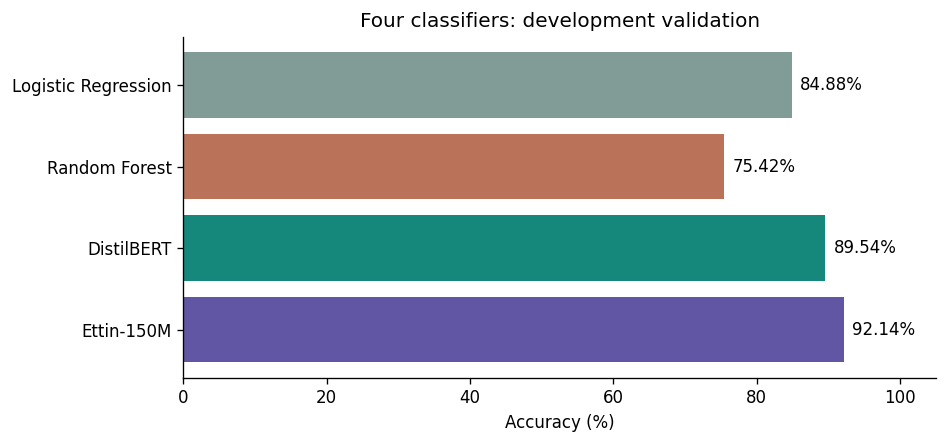

In [13]:
@torch.inference_mode()
def predict_logits(messages, description="DistilBERT inference", show_progress=True,
                   trained_model=None, trained_tokenizer=None, config=None):
    messages = list(messages)
    if not messages:
        raise ValueError("Provide at least one message.")
    active_model = model if trained_model is None else trained_model
    active_tokenizer = tokenizer if trained_tokenizer is None else trained_tokenizer
    active_config = TRAINING_CONFIG if config is None else config
    active_model.eval().to(DEVICE)
    chunks = []
    try:
        starts = range(0, len(messages), active_config["batch_size"])
        for start in tqdm(starts, desc=description, disable=not show_progress):
            encoded = active_tokenizer(messages[start:start + active_config["batch_size"]],
                padding="max_length", truncation=True, max_length=active_config["maximum_length"],
                return_tensors="pt")
            encoded = {key: value.to(DEVICE) for key, value in encoded.items()}
            chunks.append(active_model(**encoded).logits.detach().cpu().numpy())
    finally:
        active_model.to("cpu")
        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()
    return np.concatenate(chunks).astype(np.float64)

def aligned_probabilities(pipeline, messages):
    probabilities = pipeline.predict_proba(list(messages))
    classes = pipeline.named_steps["classifier"].classes_.astype(int)
    aligned = np.zeros((len(probabilities), NUM_CLASSES), dtype=np.float64)
    aligned[:, classes] = probabilities
    return aligned

def calibration_gaps(y, probabilities, bins=15):
    confidence = probabilities.max(axis=1)
    correct = probabilities.argmax(axis=1) == np.asarray(y)
    bin_ids = np.minimum((confidence * bins).astype(int), bins - 1)
    records = []
    for index in range(bins):
        selected = bin_ids == index
        if selected.any():
            records.append({"bin": index, "count": int(selected.sum()),
                "confidence": float(confidence[selected].mean()),
                "accuracy": float(correct[selected].mean())})
    table = pd.DataFrame(records)
    ece = ((table["count"] / len(y)) * (table.accuracy - table.confidence).abs()).sum()
    return float(ece), table

def classification_metrics(name, y, probabilities):
    y = np.asarray(y, dtype=int)
    predicted = probabilities.argmax(axis=1)
    one_hot = np.eye(NUM_CLASSES)[y]
    return {"model": name, "accuracy": accuracy_score(y, predicted),
        "macro_f1": f1_score(y, predicted, labels=np.arange(NUM_CLASSES),
                             average="macro", zero_division=0),
        "log_loss": log_loss(y, probabilities, labels=np.arange(NUM_CLASSES)),
        "ece": calibration_gaps(y, probabilities)[0],
        "brier": float(np.mean(np.sum((probabilities - one_hot) ** 2, axis=1)))}

val_logits = predict_logits(val_df.text, "Validation inference")
val_probabilities = {name: aligned_probabilities(pipeline, val_df.text)
                     for name, pipeline in classical_models.items()}
val_probabilities["DistilBERT"] = softmax(val_logits, axis=1)
ettin_val_logits = predict_logits(val_df.text, "Ettin validation inference",
    trained_model=ettin_model, trained_tokenizer=ettin_tokenizer, config=ETTIN_CONFIG)
val_probabilities["Ettin-150M"] = softmax(ettin_val_logits, axis=1)
validation_metrics = pd.DataFrame([
    classification_metrics(name, val_df.label, p) for name, p in val_probabilities.items()])
display(validation_metrics.style.format({c: "{:.4f}" for c in validation_metrics.columns if c != "model"}))
validation_metrics.to_csv(RESULT_DIR / "classification_validation.csv", index=False)

def plot_classifier_accuracy(metrics, title, filename):
    fig, ax = plt.subplots(figsize=(8, 3.8))
    colors = {"Logistic Regression": "#819b96", "Random Forest": "#ba7359",
              "DistilBERT": "#16877b", "Ettin-150M": "#6156a4"}
    bars = ax.barh(metrics.model, metrics.accuracy * 100,
                   color=[colors.get(name, "#536866") for name in metrics.model])
    ax.bar_label(bars, labels=[f"{v:.2%}" for v in metrics.accuracy], padding=5)
    ax.set_xlim(0, 105)
    ax.set_xlabel("Accuracy (%)")
    ax.set_title(title)
    ax.invert_yaxis()
    fig.tight_layout()
    fig.savefig(RESULT_DIR / filename, dpi=180)
    plt.show()

plot_classifier_accuracy(validation_metrics, "Four classifiers: development validation",
                         "classifier_validation.png")

### 7B. Inspect predictions and classification errors

The table below contains every validation message, its actual intent and each
model's predicted intent and confidence. Select a model to inspect its mistakes,
top confused pairs, and per-intent precision/recall/F1. These use development data.
The lexical witness fitted later is an auxiliary routing signal, not a fifth
classifier in this four-model comparison.

In [14]:
from sklearn.metrics import precision_recall_fscore_support

validation_predictions = val_df[["row_id", "text", "label", "label_text"]].copy()
per_intent_reports = {}
for name, probabilities in val_probabilities.items():
    predicted = probabilities.argmax(axis=1)
    validation_predictions[f"{name}: predicted"] = [INTENTS[i] for i in predicted]
    validation_predictions[f"{name}: confidence"] = probabilities.max(axis=1)
    precision, recall, f1, support = precision_recall_fscore_support(
        val_df.label, predicted, labels=np.arange(NUM_CLASSES), zero_division=0)
    per_intent_reports[name] = pd.DataFrame({"intent": INTENTS, "precision": precision,
        "recall": recall, "f1": f1, "support": support})
    per_intent_reports[name].to_csv(
        RESULT_DIR / f"per_intent_{name.lower().replace(' ', '_')}.csv", index=False)
validation_predictions.to_csv(RESULT_DIR / "validation_predictions.csv", index=False)

def show_classification_errors(model_name):
    predicted = val_probabilities[model_name].argmax(axis=1)
    errors = validation_predictions.loc[predicted != val_df.label.to_numpy(),
        ["row_id", "text", "label_text", f"{model_name}: predicted", f"{model_name}: confidence"]]
    print(f"{model_name}: {len(errors)} errors / {len(val_df)} messages")
    with pd.option_context("display.max_colwidth", None):
        display(errors.head(20))
    display(errors.groupby(["label_text", f"{model_name}: predicted"]).size()
            .rename("count").sort_values(ascending=False).head(15).to_frame())
    display(per_intent_reports[model_name].sort_values("f1").head(15))

widgets.interact(show_classification_errors,
    model_name=widgets.Dropdown(options=list(val_probabilities), value="DistilBERT"))

interactive(children=(Dropdown(description='model_name', index=2, options=('Logistic Regression', 'Random Fore…

<function __main__.show_classification_errors(model_name)>

### 7C. See the actual model inputs and learned word associations

Inspect the TF-IDF features and both tokenizers for a message. You can also choose
an intent to see the Logistic Regression coefficients most associated with it.
Coefficients are learned associations, not causal explanations of banking risk.

In [15]:
INPUT_MESSAGE = "My card has not arrived yet."
vectorizer = classical_models["Logistic Regression"].named_steps["tfidf"]
word_vector = vectorizer.transform([INPUT_MESSAGE])
feature_names = vectorizer.get_feature_names_out()
display(pd.DataFrame({"feature": feature_names[word_vector.indices], "tfidf": word_vector.data})
        .sort_values("tfidf", ascending=False).head(20))
for name, encoder_tokenizer in [("DistilBERT", tokenizer), ("Ettin-150M", ettin_tokenizer)]:
    encoded = encoder_tokenizer(INPUT_MESSAGE, truncation=True, max_length=128)
    print(name)
    display(pd.DataFrame({"token": encoder_tokenizer.convert_ids_to_tokens(encoded["input_ids"]),
                          "token_id": encoded["input_ids"], "attention_mask": encoded["attention_mask"]}))
svd = classical_models["Random Forest"].named_steps["svd"]
print(f"Random Forest SVD: {svd.n_components} dimensions; retained variance {svd.explained_variance_ratio_.sum():.2%}")

def inspect_intent_words(intent):
    classifier = classical_models["Logistic Regression"].named_steps["classifier"]
    position = int(np.flatnonzero(classifier.classes_ == LABEL_TO_ID[intent])[0])
    weights = classifier.coef_[position]
    strongest = np.argsort(weights)[-15:][::-1]
    display(pd.DataFrame({"feature": feature_names[strongest], "coefficient": weights[strongest]}))
widgets.interact(inspect_intent_words,
    intent=widgets.Dropdown(options=INTENTS, value="card_arrival", layout=widgets.Layout(width="500px")))

,feature,tfidf
9,not arrived,0.467162
1,arrived yet,0.410329
3,card has,0.384470
0,arrived,0.355805
5,has not,0.331842
10,yet,0.268811
4,has,0.243457
8,not,0.196131
7,my card,0.175743
2,card,0.136119


DistilBERT


,token,token_id,attention_mask
0,[CLS],101,1
1,my,2026,1
2,card,4003,1
3,has,2038,1
4,not,2025,1
5,arrived,3369,1
6,yet,2664,1
7,.,1012,1
8,[SEP],102,1


Ettin-150M


,token,token_id,attention_mask
0,[CLS],50281,1
1,My,3220,1
2,Ġcard,3120,1
3,Ġhas,556,1
4,Ġnot,417,1
5,Ġarrived,7244,1
6,Ġyet,2568,1
7,.,15,1
8,[SEP],50282,1


Random Forest SVD: 256 dimensions; retained variance 43.35%


interactive(children=(Dropdown(description='intent', index=11, layout=Layout(width='500px'), options=('activat…

<function __main__.inspect_intent_words(intent)>

## 8. Fit temperature scaling on calibration data

DistilBERT produces logits $z$. We learn **one positive temperature** on the 1,500
calibration examples, with all classifier weights frozen:

$$p_T(k\mid x)=\frac{e^{z_k/T}}{\sum_j e^{z_j/T}},\qquad
T^*=\arg\min_{T>0}-\frac{1}{N_{cal}}\sum_n\log p_T(y_n\mid x_n).$$

The optimizer searches over $\log T$ to keep $T$ positive, using the project's
fixed numerical bounds $0.05\le T\le20$. $T<1$ sharpens probabilities; $T>1$ softens
them. The argmax label is preserved. The fitted temperature can differ from the
historical 0.776452 because the classifier is retrained here.

We evaluate calibration improvements on **validation**, not just the fitting set.
Method: [Guo et al., ICML 2017](https://proceedings.mlr.press/v70/guo17a.html).

Calibration inference:   0%|          | 0/94 [00:00<?, ?it/s]

Fitted temperature: 0.773637


,model,accuracy,macro_f1,log_loss,ece,brier
0,Raw DistilBERT,0.895403,0.883267,0.431863,0.076544,0.157339
1,Calibrated DistilBERT,0.895403,0.883267,0.382040,0.025775,0.153431


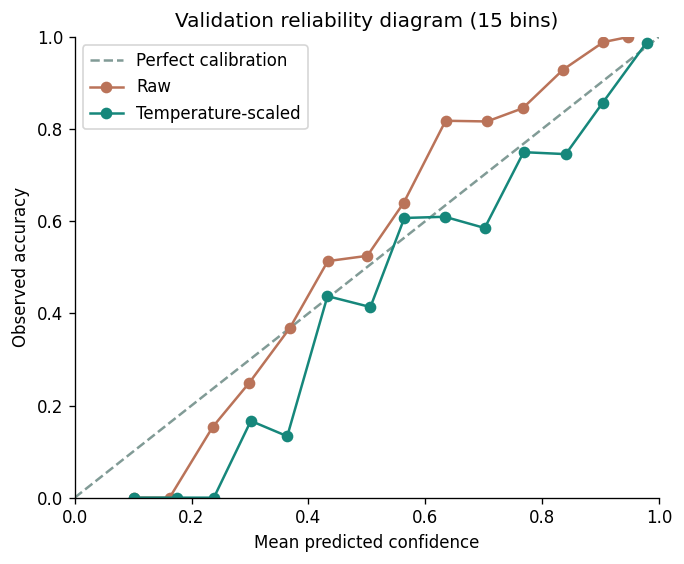

In [16]:
cal_logits = predict_logits(cal_df.text, "Calibration inference")
cal_labels = cal_df.label.to_numpy()

def temperature_objective(log_temperature):
    scaled = cal_logits / np.exp(log_temperature)
    return float(np.mean(logsumexp(scaled, axis=1) - scaled[np.arange(len(cal_labels)), cal_labels]))

fit = minimize_scalar(temperature_objective, bounds=(np.log(0.05), np.log(20.0)),
                      method="bounded", options={"xatol": 1e-8})
if not fit.success or not np.isfinite(fit.fun):
    raise RuntimeError("Temperature optimization did not converge.")
TEMPERATURE = float(np.exp(fit.x))
calibrated_val = softmax(val_logits / TEMPERATURE, axis=1)
calibration_comparison = pd.DataFrame([
    classification_metrics("Raw DistilBERT", val_df.label, val_probabilities["DistilBERT"]),
    classification_metrics("Calibrated DistilBERT", val_df.label, calibrated_val),
])
print(f"Fitted temperature: {TEMPERATURE:.6f}")
display(calibration_comparison)
calibration_comparison.to_csv(RESULT_DIR / "calibration_validation.csv", index=False)
(CHECKPOINT_DIR / "temperature.json").write_text(json.dumps({
    "temperature": TEMPERATURE, "fit_partition": "calibration", "rows": len(cal_df),
    "signature": SIGNATURE}, indent=2))

fig, ax = plt.subplots(figsize=(5.8, 4.8))
ax.plot([0, 1], [0, 1], "--", color="#819b96", label="Perfect calibration")
for name, p, color in [("Raw", val_probabilities["DistilBERT"], "#ba7359"),
                       ("Temperature-scaled", calibrated_val, "#16877b")]:
    _, bins = calibration_gaps(val_df.label, p)
    ax.plot(bins.confidence, bins.accuracy, "o-", color=color, label=name)
ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="Mean predicted confidence",
       ylabel="Observed accuracy", title="Validation reliability diagram (15 bins)")
ax.legend()
fig.tight_layout()
fig.savefig(RESULT_DIR / "calibration_reliability.png", dpi=180)
plt.show()

### 8B. Calibration context for the other retained encoders

The repository also implements temperature scaling for Logistic Regression. Here
we fit its scalar temperature and, for the new Ettin comparison, a separate Ettin
temperature. Each uses only the same calibration rows. The validation table is
separate from the raw four-model classifier comparison. Random Forest remains
uncalibrated; no unimplemented tree calibration is claimed.

Each encoder keeps its own fitted temperature. Section 11B applies all AURA
routing variants to Ettin as well as DistilBERT, without replacing the historical
DistilBERT experiment. Logistic Regression calibration remains supplementary.

In [17]:
def fit_scalar_temperature(logits, labels):
    scores = np.asarray(logits, dtype=np.float64)
    truth = np.asarray(labels, dtype=int)
    def objective(log_temperature):
        scaled = scores / np.exp(log_temperature)
        return float(np.mean(logsumexp(scaled, axis=1) - scaled[np.arange(len(truth)), truth]))
    optimum = minimize_scalar(objective, bounds=(np.log(0.05), np.log(20.0)),
                              method="bounded", options={"xatol": 1e-8})
    if not optimum.success or not np.isfinite(optimum.fun):
        raise RuntimeError("Temperature optimization failed.")
    return float(np.exp(optimum.x))

lr_cal_logits = classical_models["Logistic Regression"].decision_function(cal_df.text.tolist())
lr_val_logits = classical_models["Logistic Regression"].decision_function(val_df.text.tolist())
ettin_cal_logits = predict_logits(cal_df.text, "Ettin calibration inference",
    trained_model=ettin_model, trained_tokenizer=ettin_tokenizer, config=ETTIN_CONFIG)
EXTRA_TEMPERATURES = {
    "Logistic Regression": fit_scalar_temperature(lr_cal_logits, cal_df.label),
    "Ettin-150M": fit_scalar_temperature(ettin_cal_logits, cal_df.label),
}
extra_calibrated_val = {
    "Logistic Regression": softmax(lr_val_logits / EXTRA_TEMPERATURES["Logistic Regression"], axis=1),
    "Ettin-150M": softmax(ettin_val_logits / EXTRA_TEMPERATURES["Ettin-150M"], axis=1),
}
extra_calibration_metrics = []
for name, probabilities in extra_calibrated_val.items():
    for stage, p in [("raw", val_probabilities[name]), ("calibrated", probabilities)]:
        row = classification_metrics(name, val_df.label, p)
        row.update(stage=stage, temperature=EXTRA_TEMPERATURES[name])
        extra_calibration_metrics.append(row)
display(pd.DataFrame(extra_calibration_metrics))
pd.DataFrame(extra_calibration_metrics).to_csv(RESULT_DIR / "additional_calibration_validation.csv", index=False)

Ettin calibration inference:   0%|          | 0/188 [00:00<?, ?it/s]

,model,accuracy,macro_f1,log_loss,ece,brier,stage,temperature
0,Logistic Regression,0.848767,0.849640,1.486746,0.518964,0.536339,raw,0.338304
1,Logistic Regression,0.848767,0.849640,0.575490,0.034767,0.233484,calibrated,0.338304
2,Ettin-150M,0.921386,0.919555,0.305410,0.025056,0.118645,raw,1.191976
3,Ettin-150M,0.921386,0.919555,0.301946,0.019717,0.117871,calibrated,1.191976


## 9. Construct the first AURA cost matrix and evaluate routing

Each intent has a required action and a set of consequence flags. For a possible
true intent $i$ and assigned route $j$, compare their actions and compute omitted
flags as $F_i\setminus F_j$. Correct routing costs zero; an incorrect route receives
the **largest applicable scenario floor**.

| Condition | Flat | Moderate | High protection |
|---|---:|---:|---:|
| Any incorrect label | 1 | 1 | 1 |
| Required-action mismatch | 1 | 2 | 3 |
| Omitted correction/compliance | 1 | 3 | 5 |
| Omitted protection/unauthorized handling | 1 | 5 | 10 |

These numbers are assumed relative research costs. References in the loaded
workflow map inform qualitative actions, not these exact numeric ratios. Shared
flags are only a proxy for preserving actions; real workflow behavior is unverified.

$$\hat y=\arg\max_k p_T(k\mid x),\qquad
R_s(x)=\sum_{i=1}^{77}p_T(i\mid x)C^{(s)}_{i,\hat y}.$$

AURA keeps the argmax route. At target coverage $c$, it accepts the
$K=\lfloor cN\rfloor$ lowest-risk messages, breaking ties by row ID. Confidence
routing accepts the same count by highest calibrated probability.

The result cost is computed **after selection**, using known labels:
$$L_s=\sum_{n\in AUTO}C^{(s)}_{y_n,\hat y_n}.$$
It excludes human-review costs. The comparison is offline budget ranking, not an
independently validated deployment threshold. Multi-coverage evaluation context:
[Traub et al., NeurIPS 2024](https://arxiv.org/abs/2407.01032). AUGRC is not computed here.

,policy,evaluation_scenario,target_coverage,actual_coverage,accepted,deferred,accepted_errors,accepted_accuracy,accepted_cost,cost_per_input
1,Confidence,moderate,0.5,0.499667,750,751,1,0.998667,2.0,0.001332
4,First AURA,moderate,0.5,0.499667,750,751,2,0.997333,3.0,0.001999
7,Confidence,moderate,0.7,0.699534,1050,451,10,0.990476,17.0,0.011326
10,First AURA,moderate,0.7,0.699534,1050,451,14,0.986667,19.0,0.012658
13,Confidence,moderate,0.8,0.799467,1200,301,31,0.974167,58.0,0.038641
16,First AURA,moderate,0.8,0.799467,1200,301,33,0.972500,52.0,0.034644
19,Confidence,moderate,0.9,0.899400,1350,151,72,0.946667,140.0,0.093271
22,First AURA,moderate,0.9,0.899400,1350,151,78,0.942222,130.0,0.086609
25,Confidence,moderate,1.0,1.000000,1501,0,157,0.895403,294.0,0.195869
28,First AURA,moderate,1.0,1.000000,1501,0,157,0.895403,294.0,0.195869


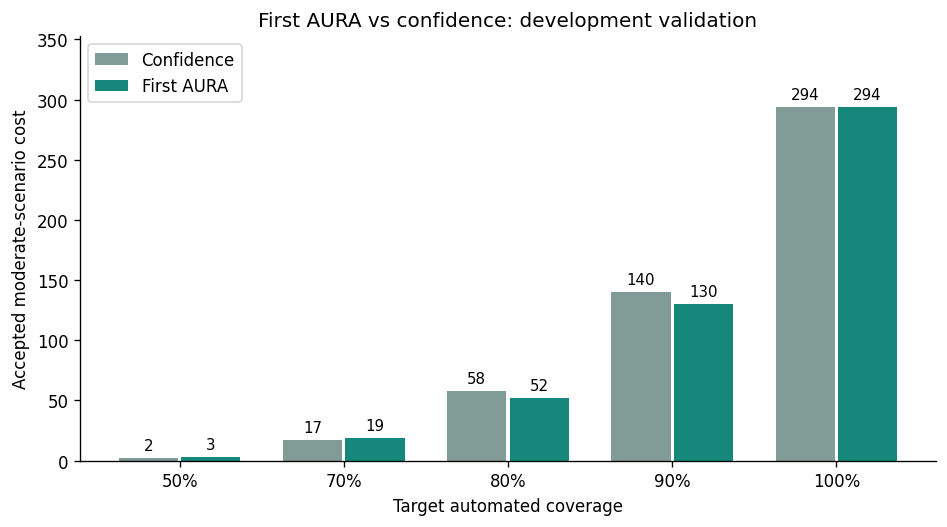

,scenario,minimum,maximum
0,flat,0.0,1.0
1,moderate,0.0,5.0
2,high_protection,0.0,10.0


In [18]:
SCENARIOS = PROJECT_SPEC["scenario_specification"]["scenarios"]

def build_cost_matrix(scenario_name):
    settings = SCENARIOS[scenario_name]
    matrix = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=np.float64)
    for true in WORKFLOWS:
        for route in WORKFLOWS:
            i, j = true["label"], route["label"]
            if i == j:
                continue
            floors = [settings["base_incorrect_cost"]]
            if true["required_action"] != route["required_action"]:
                floors.append(settings["action_mismatch_cost"])
            omitted = set(true["consequence_flags"]) - set(route["consequence_flags"])
            floors.extend(settings["omitted_consequence_costs"][flag] for flag in omitted)
            matrix[i, j] = max(floors)
    return matrix

COST_MATRICES = {name: build_cost_matrix(name) for name in SCENARIOS}
C_MODERATE = COST_MATRICES["moderate"]

def expected_risk(probabilities, costs):
    predicted = probabilities.argmax(axis=1)
    contributions = probabilities * costs[:, predicted].T
    return contributions.sum(axis=1)

def select_at_coverage(scores, row_ids, coverage):
    if not np.isfinite(coverage) or not 0 <= coverage <= 1:
        raise ValueError("Coverage must be between 0 and 1.")
    count = int((Decimal(str(coverage)) * len(scores)).to_integral_value(rounding=ROUND_FLOOR))
    accepted = np.zeros(len(scores), dtype=bool)
    accepted[np.lexsort((np.asarray(row_ids), np.asarray(scores)))[:count]] = True
    return accepted

def evaluate_routing(frame, probabilities):
    predicted = probabilities.argmax(axis=1)
    truth = frame.label.to_numpy()
    scores = {"Confidence": -probabilities.max(axis=1),
              "First AURA": expected_risk(probabilities, C_MODERATE)}
    records, decisions = [], []
    for coverage in [0.5, 0.7, 0.8, 0.9, 1.0]:
        for policy, risk in scores.items():
            accepted = select_at_coverage(risk, frame.row_id.to_numpy(), coverage)
            count = int(accepted.sum())
            errors = int(((predicted != truth) & accepted).sum())
            for scenario, costs in COST_MATRICES.items():
                total = float(costs[truth[accepted], predicted[accepted]].sum())
                records.append({"policy": policy, "evaluation_scenario": scenario,
                    "target_coverage": coverage, "actual_coverage": count / len(frame),
                    "accepted": count, "deferred": len(frame) - count,
                    "accepted_errors": errors, "accepted_accuracy": 1 - errors / count,
                    "accepted_cost": total, "cost_per_input": total / len(frame)})
            decisions.append(pd.DataFrame({"row_id": frame.row_id.to_numpy(),
                "policy": policy, "target_coverage": coverage, "accepted": accepted,
                "predicted_label": predicted, "true_label": truth}))
    return pd.DataFrame(records), pd.concat(decisions, ignore_index=True)

def plot_routing(comparison, title, filename):
    data = comparison[comparison.evaluation_scenario == "moderate"]
    costs = data.pivot(index="target_coverage", columns="policy", values="accepted_cost")
    fig, ax = plt.subplots(figsize=(8, 4.5))
    positions = np.arange(len(costs))
    for offset, policy, color in [(-0.19, "Confidence", "#819b96"), (0.19, "First AURA", "#16877b")]:
        bars = ax.bar(positions + offset, costs[policy], width=0.36, label=policy, color=color)
        ax.bar_label(bars, fmt="%.0f", padding=3, fontsize=9)
    ax.set_xticks(positions, [f"{c:.0%}" for c in costs.index])
    ax.set(xlabel="Target automated coverage", ylabel="Accepted moderate-scenario cost",
           title=title)
    ax.set_ylim(0, max(float(costs.max().max()) * 1.2, 1))
    ax.legend()
    fig.tight_layout()
    fig.savefig(RESULT_DIR / filename, dpi=180)
    plt.show()

val_routing, val_decisions = evaluate_routing(val_df, calibrated_val)
display(val_routing[val_routing.evaluation_scenario == "moderate"])
plot_routing(val_routing, "First AURA vs confidence: development validation", "routing_validation.png")
val_routing.to_csv(RESULT_DIR / "routing_validation.csv", index=False)
val_decisions.to_csv(RESULT_DIR / "decisions_validation.csv", index=False)
display(pd.DataFrame({"scenario": list(COST_MATRICES),
    "minimum": [m.min() for m in COST_MATRICES.values()],
    "maximum": [m.max() for m in COST_MATRICES.values()]}))

### 9B. See how an individual matrix entry is constructed

Inspect all 77 workflow definitions below and choose a possible true intent and
predicted route. The explanation displays the action mismatch, omitted flags,
applicable floors, and final cost in each scenario. The heatmap uses canonical
numeric IDs; the data browser shows their intent names.

,label,intent,operational_family,required_action,consequence_flags,rationale
0,0,activate_my_card,card_servicing,manage_payment_instrument,[],Card activation requires instrument servicing ...
1,1,age_limit,routine_information,provide_information,[],Explains product eligibility requirements with...
2,2,apple_pay_or_google_pay,funding_top_up,support_funding,[],Explains or troubleshoots account funding thro...
3,3,atm_support,routine_information,provide_information,[],Provides information about supported cash with...
4,4,automatic_top_up,funding_top_up,configure_funding,[],Configures an optional account-funding feature.
...,...,...,...,...,...,...
72,72,virtual_card_not_working,card_servicing,restore_access_or_instrument,[],Troubleshoots or restores a virtual payment in...
73,73,visa_or_mastercard,routine_information,provide_information,[],Provides payment-network product information.
74,74,why_verify_identity,identity_compliance,provide_information,[],Explains the purpose of customer identity due ...
75,75,wrong_amount_of_cash_received,transaction_correction,trace_or_correct_transaction,[transaction_correction],Investigates and corrects a discrepancy in cas...


interactive(children=(Dropdown(description='true_intent', index=22, options=('activate_my_card', 'age_limit', …

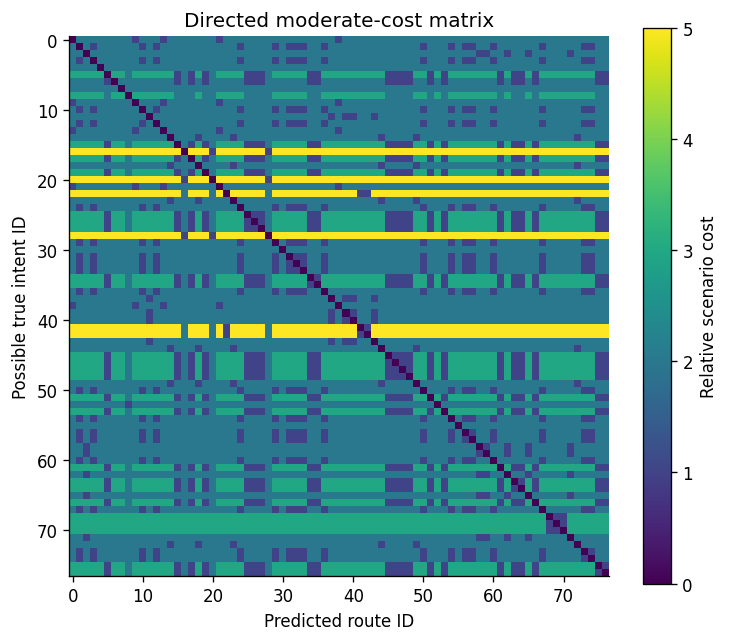

In [19]:
workflow_table = pd.DataFrame([{key: workflow.get(key) for key in
    ["label", "intent", "operational_family", "required_action", "consequence_flags", "rationale"]}
    for workflow in WORKFLOWS])
display(workflow_table)
workflow_table.to_csv(RESULT_DIR / "workflow_inventory.csv", index=False)
for name, matrix in COST_MATRICES.items():
    pd.DataFrame(matrix, index=INTENTS, columns=INTENTS).to_csv(RESULT_DIR / f"cost_matrix_{name}.csv")

def explain_cost_entry(true_intent, assigned_route):
    i, j = LABEL_TO_ID[true_intent], LABEL_TO_ID[assigned_route]
    true, route = WORKFLOWS[i], WORKFLOWS[j]
    omitted = sorted(set(true["consequence_flags"]) - set(route["consequence_flags"]))
    print("Required action:", true["required_action"])
    print("Assigned route's action:", route["required_action"])
    print("Omitted flags:", omitted or "None")
    rows = []
    for scenario, settings in SCENARIOS.items():
        floors = [] if i == j else [settings["base_incorrect_cost"]]
        if i != j and true["required_action"] != route["required_action"]:
            floors.append(settings["action_mismatch_cost"])
        if i != j:
            floors.extend(settings["omitted_consequence_costs"][flag] for flag in omitted)
        rows.append({"scenario": scenario, "applicable_floors": floors,
                     "cost": COST_MATRICES[scenario][i, j]})
    display(pd.DataFrame(rows))

widgets.interact(explain_cost_entry,
    true_intent=widgets.Dropdown(options=INTENTS, value="compromised_card"),
    assigned_route=widgets.Dropdown(options=INTENTS, value="age_limit"))
fig, ax = plt.subplots(figsize=(6.4, 5.4))
image = ax.imshow(C_MODERATE, origin="upper", cmap="viridis", vmin=0, vmax=C_MODERATE.max())
ax.set(xlabel="Predicted route ID", ylabel="Possible true intent ID", title="Directed moderate-cost matrix")
fig.colorbar(image, ax=ax, label="Relative scenario cost")
fig.tight_layout()
fig.savefig(RESULT_DIR / "cost_matrix_moderate.png", dpi=180)
plt.show()

## 10. All implemented DistilBERT routing variants

The four classifiers above answer *which intent?* These policies answer *which
DistilBERT predictions should be accepted?* All preserve DistilBERT's argmax label.

| Policy | Lower-is-preferred score / rule |
|---|---|
| Confidence | Negative maximum calibrated probability |
| Flat cost | Original expected risk with unit error costs; same ranking as confidence |
| Original AURA | Expected moderate-scenario cost |
| High-protection AURA | Expected high-protection-scenario cost |
| Majority safeguard | Original AURA ranking, only if confidence > 0.5; no backfill |
| Logit margin | Negative difference between highest and second-highest raw logit |
| Semantic gate | Learned error probability using semantic margin only |
| Signed lexical gate | Learned error probability using margin and signed lexical support |
| Cost-aware lexical gate | Learned error estimate times conditional scenario severity |

A word/character TF-IDF + Linear SVM witness is fitted only on model-training
messages. Its signed support for DistilBERT's proposed intent is the SVM score for
that intent minus its strongest competing score. A StandardScaler + Logistic
Regression correctness gate is fitted on calibration rows, then frozen.

$$m(x)=z_{(1)}-z_{(2)},\quad s_{lex}(x)=u_{\hat y}-\max_{k\ne\hat y}u_k,$$
$$q(x)=1-P_{gate}(correct\mid m,s_{lex}),\quad
r_{gate}(x)=q(x)\frac{R_{moderate}(x)}{\sum_{i\ne\hat y}p_T(i\mid x)}.$$

The gate reuses temperature-calibration rows and has no independent risk
certification partition. Its error estimate is not independently calibrated.
The cost extension is a ranking proxy that retains the base model's relative
probabilities among alternative intents. It is not a verified banking-loss model.

Research context: [signed lexical gate preprint, 2026](https://arxiv.org/abs/2610.00262)
and [margin-based selective classification, TMLR 2024](https://arxiv.org/abs/2405.05160).
The independent risk-calibration procedure in the lexical paper is not implemented.

In [20]:
from sklearn.pipeline import FeatureUnion
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.linear_model import Ridge

def build_lexical_witness():
    return Pipeline([
        ("features", FeatureUnion([
            ("word", TfidfVectorizer(ngram_range=(1, 2), min_df=2,
                                     max_features=30_000, sublinear_tf=True)),
            ("character", TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5),
                         min_df=2, max_features=50_000, sublinear_tf=True)),
        ])),
        ("classifier", LinearSVC(C=1.0, random_state=SEED, max_iter=10_000)),
    ])

def lexical_features(semantic_logits, witness_scores, witness_classes):
    semantic = np.asarray(semantic_logits, dtype=np.float64)
    lexical = np.asarray(witness_scores, dtype=np.float64)
    positions = {int(label): column for column, label in enumerate(witness_classes)}
    if set(positions) != set(range(NUM_CLASSES)):
        raise ValueError("Witness classes must match all canonical intents.")
    lexical = lexical[:, [positions[i] for i in range(NUM_CLASSES)]]
    predicted = semantic.argmax(axis=1)
    top = np.partition(semantic, -2, axis=1)[:, -2:]
    margin = top[:, 1] - top[:, 0]
    routed = lexical[np.arange(len(lexical)), predicted]
    competitors = lexical.copy()
    competitors[np.arange(len(lexical)), predicted] = -np.inf
    support = routed - competitors.max(axis=1)
    return np.column_stack([margin, support])

def fit_correctness_gate(features, correct):
    if set(np.asarray(correct)) != {0, 1}:
        raise ValueError("Correctness-gate fitting requires both correct and incorrect cases.")
    return Pipeline([("scale", StandardScaler()),
        ("classifier", LogisticRegression(C=1.0, max_iter=1000, random_state=SEED))]).fit(features, correct)

def fingerprint_checkpoint(directory):
    digest = hashlib.sha256()
    for path in sorted(directory.iterdir()):
        if path.is_file() and path.suffix in {".safetensors", ".bin", ".json", ".txt"}:
            digest.update(path.name.encode())
            with path.open("rb") as stream:
                for block in iter(lambda: stream.read(1024 * 1024), b""):
                    digest.update(block)
    return digest.hexdigest()

DISTILBERT_CHECKPOINT_HASH = fingerprint_checkpoint(MODEL_DIR)
LEXICAL_SIGNATURE = hashlib.sha256((SIGNATURE + DISTILBERT_CHECKPOINT_HASH + "lexical-gate-v1").encode()).hexdigest()
LEXICAL_PATH = CHECKPOINT_DIR / f"lexical_{LEXICAL_SIGNATURE[:16]}.joblib"
calibrated_cal = softmax(cal_logits / TEMPERATURE, axis=1)
if REUSE_CHECKPOINTS and LEXICAL_PATH.exists():
    lexical_artifact = joblib.load(LEXICAL_PATH)
    if lexical_artifact["signature"] != LEXICAL_SIGNATURE:
        raise ValueError("Lexical checkpoint provenance mismatch.")
    witness = lexical_artifact["witness"]
    semantic_gate = lexical_artifact["semantic_gate"]
    signed_gate = lexical_artifact["signed_gate"]
    print("Loaded lexical witness and correctness gates.")
else:
    print("Training auxiliary lexical witness on model-training rows...", flush=True)
    witness = build_lexical_witness().fit(train_df.text.tolist(), train_df.label.to_numpy())
    fit_features = lexical_features(cal_logits, witness.decision_function(cal_df.text.tolist()),
                                    witness.named_steps["classifier"].classes_)
    correct = (cal_logits.argmax(axis=1) == cal_df.label.to_numpy()).astype(int)
    semantic_gate = fit_correctness_gate(fit_features[:, :1], correct)
    signed_gate = fit_correctness_gate(fit_features, correct)
    joblib.dump({"signature": LEXICAL_SIGNATURE, "witness": witness,
                "semantic_gate": semantic_gate, "signed_gate": signed_gate}, LEXICAL_PATH)

fit_features = lexical_features(cal_logits, witness.decision_function(cal_df.text.tolist()),
                                witness.named_steps["classifier"].classes_)
val_features = lexical_features(val_logits, witness.decision_function(val_df.text.tolist()),
                                witness.named_steps["classifier"].classes_)
display(pd.DataFrame({"feature": ["semantic_margin", "signed_lexical_support"],
    "signed_gate_coefficient_on_standardized_input": signed_gate.named_steps["classifier"].coef_[0]}))

Training auxiliary lexical witness on model-training rows...


,feature,signed_gate_coefficient_on_standardized_input
0,semantic_margin,1.150752
1,signed_lexical_support,1.550508


,policy,evaluation_scenario,target_coverage,requested_count,accepted_count,actual_coverage,deferred_count,accepted_errors,accepted_accuracy,accepted_total_cost,accepted_cost_per_input,cost_per_accepted
67,confidence,moderate,0.8,1200,1200,0.799467,301,31,0.974167,58.0,0.038641,0.048333
70,flat,moderate,0.8,1200,1200,0.799467,301,31,0.974167,58.0,0.038641,0.048333
73,original_aura,moderate,0.8,1200,1200,0.799467,301,33,0.972500,52.0,0.034644,0.043333
76,high_protection,moderate,0.8,1200,1200,0.799467,301,32,0.973333,47.0,0.031312,0.039167
79,guarded_moderate,moderate,0.8,1200,1200,0.799467,301,33,0.972500,52.0,0.034644,0.043333
82,logit_margin,moderate,0.8,1200,1200,0.799467,301,32,0.973333,55.0,0.036642,0.045833
85,semantic_gate,moderate,0.8,1200,1200,0.799467,301,32,0.973333,55.0,0.036642,0.045833
88,signed_gate,moderate,0.8,1200,1200,0.799467,301,21,0.982500,40.0,0.026649,0.033333
91,signed_cost_gate,moderate,0.8,1200,1200,0.799467,301,20,0.983333,32.0,0.021319,0.026667
94,confidence_guard_matched_count,moderate,0.8,1200,1200,0.799467,301,31,0.974167,58.0,0.038641,0.048333


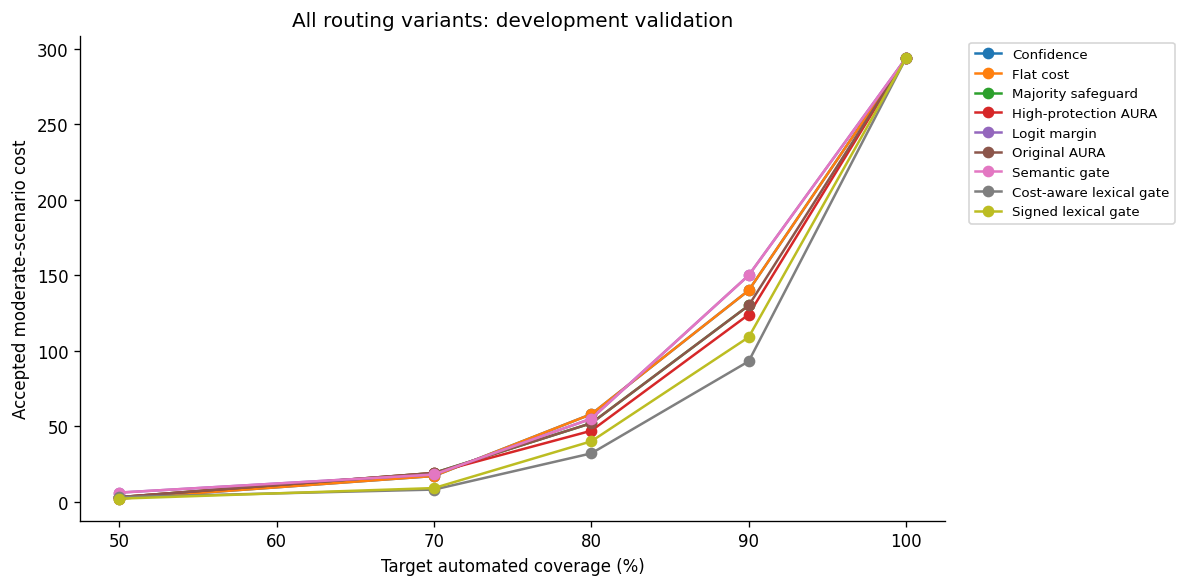

In [21]:
POLICY_LABELS = {"confidence": "Confidence", "flat": "Flat cost", "original_aura": "Original AURA",
    "high_protection": "High-protection AURA", "guarded_moderate": "Majority safeguard",
    "logit_margin": "Logit margin", "semantic_gate": "Semantic gate",
    "signed_gate": "Signed lexical gate", "signed_cost_gate": "Cost-aware gate"}

def routing_variant_scores(probabilities, features, gates=None):
    risk = expected_risk(probabilities, C_MODERATE)
    selected_semantic = semantic_gate if gates is None else gates["semantic_gate"]
    selected_signed = signed_gate if gates is None else gates["signed_gate"]
    q_semantic = selected_semantic.predict_proba(features[:, :1])[:, 0]
    q_signed = selected_signed.predict_proba(features)[:, 0]
    alternatives = probabilities.copy()
    alternatives[np.arange(len(probabilities)), probabilities.argmax(axis=1)] = 0
    mass = alternatives.sum(axis=1)
    if np.any(mass <= 0):
        raise ValueError("Cost-aware gating requires positive alternative-intent mass.")
    return {"confidence": -probabilities.max(axis=1),
        "flat": expected_risk(probabilities, COST_MATRICES["flat"]),
        "original_aura": risk,
        "high_protection": expected_risk(probabilities, COST_MATRICES["high_protection"]),
        "guarded_moderate": risk,
        "logit_margin": -features[:, 0], "semantic_gate": q_semantic,
        "signed_gate": q_signed, "signed_cost_gate": q_signed * risk / mass}

def select_count(scores, row_ids, count, eligible=None):
    order = np.lexsort((np.asarray(row_ids), np.asarray(scores)))
    if eligible is not None:
        order = order[np.asarray(eligible, dtype=bool)[order]]
    mask = np.zeros(len(scores), dtype=bool)
    mask[order[:count]] = True
    return mask

def evaluate_score_policies(frame, probabilities, scores, include_guard=False):
    predicted = probabilities.argmax(axis=1)
    truth = frame.label.to_numpy()
    ids = frame.row_id.to_numpy()
    reports, decisions = [], []
    for coverage in [0.5, 0.7, 0.8, 0.9, 1.0]:
        budget = int((Decimal(str(coverage)) * len(frame)).to_integral_value(rounding=ROUND_FLOOR))
        selections = {name: select_count(score, ids, budget,
            probabilities.max(axis=1) > 0.5 if include_guard and name == "guarded_moderate" else None)
            for name, score in scores.items()}
        if include_guard:
            guarded_count = int(selections["guarded_moderate"].sum())
            for reference in ["confidence", "original_aura"]:
                selections[f"{reference}_guard_matched_count"] = select_count(scores[reference], ids, guarded_count)
        for policy, mask in selections.items():
            accepted = int(mask.sum())
            errors = int(((predicted != truth) & mask).sum())
            decisions.append(pd.DataFrame({"row_id": ids, "policy": policy,
                "target_coverage": coverage, "accepted": mask}))
            for scenario, matrix in COST_MATRICES.items():
                total = float(matrix[truth[mask], predicted[mask]].sum())
                reports.append({"policy": policy, "evaluation_scenario": scenario,
                    "target_coverage": coverage, "requested_count": budget, "accepted_count": accepted,
                    "actual_coverage": accepted / len(frame), "deferred_count": len(frame) - accepted,
                    "accepted_errors": errors, "accepted_accuracy": 1 - errors / accepted if accepted else np.nan,
                    "accepted_total_cost": total, "accepted_cost_per_input": total / len(frame),
                    "cost_per_accepted": total / accepted if accepted else np.nan})
    return pd.DataFrame(reports), pd.concat(decisions, ignore_index=True)

def plot_policy_comparison(report, title, filename):
    primary = report[(report.evaluation_scenario == "moderate") &
                     ~report.policy.str.contains("matched_count")]
    table = primary.pivot(index="target_coverage", columns="policy", values="accepted_total_cost")
    fig, ax = plt.subplots(figsize=(10, 5))
    for policy in table:
        values = table[policy].copy()
        if policy == "guarded_moderate":
            guard = primary[primary.policy == policy].set_index("target_coverage")
            values.loc[guard.accepted_count < guard.requested_count] = np.nan
        ax.plot(table.index * 100, values, marker="o", label=POLICY_LABELS.get(policy, policy))
    ax.set(xlabel="Target automated coverage (%)", ylabel="Accepted moderate-scenario cost", title=title)
    ax.legend(fontsize=8, bbox_to_anchor=(1.02, 1), loc="upper left")
    fig.tight_layout()
    fig.savefig(RESULT_DIR / filename, dpi=180)
    plt.show()

all_val_scores = routing_variant_scores(calibrated_val, val_features)
all_val_report, all_val_decisions = evaluate_score_policies(
    val_df, calibrated_val, all_val_scores, include_guard=True)
display(all_val_report[(all_val_report.evaluation_scenario == "moderate") &
                       (all_val_report.target_coverage == 0.8)])
plot_policy_comparison(all_val_report, "All routing variants: development validation", "all_routing_validation.png")
all_val_report.to_csv(RESULT_DIR / "all_routing_validation.csv", index=False)
all_val_decisions.to_csv(RESULT_DIR / "all_decisions_validation.csv", index=False)
pd.DataFrame({"row_id": val_df.row_id.to_numpy(), **all_val_scores}).to_csv(
    RESULT_DIR / "all_scores_validation.csv", index=False)

### 10B. Paired uncertainty at matched coverage

The project's bootstrap resamples messages jointly, reranks each policy within
each resample, and compares accepted cost **per input**. We use 10,000 percentile
resamples and seed 42. Negative candidate-minus-reference differences favor the
candidate; an interval containing zero does not establish improvement.

The main cost-awareness contrast is the **cost-aware lexical gate versus the plain
signed gate at 80% coverage**, moderate scenario. We also retain the earlier
cost-aware-gate versus original-AURA contrast. These intervals condition on the
fitted models and assumed costs; they do not cover training uncertainty, uncertain
workflow definitions, human outcomes, or repeated development selection.

In [22]:
BOOTSTRAP_RESAMPLES = 10_000

def paired_reranking_interval(reference, candidate, realized_cost, row_ids, coverage=0.8,
                             resamples=BOOTSTRAP_RESAMPLES, seed=SEED):
    reference, candidate, costs = map(np.asarray, (reference, candidate, realized_cost))
    ids = np.asarray(row_ids)
    n = len(costs)
    budget = int((Decimal(str(coverage)) * n).to_integral_value(rounding=ROUND_FLOOR))
    def difference(indices):
        ref_order = np.lexsort((ids[indices], reference[indices]))[:budget]
        new_order = np.lexsort((ids[indices], candidate[indices]))[:budget]
        return float((costs[indices[new_order]].sum() - costs[indices[ref_order]].sum()) / n)
    point = difference(np.arange(n))
    rng = np.random.default_rng(seed)
    draws = np.empty(resamples)
    for index in tqdm(range(resamples), desc="Paired routing bootstrap", leave=False):
        draws[index] = difference(rng.integers(0, n, size=n))
    lower, upper = np.quantile(draws, [0.025, 0.975])
    return {"coverage": coverage, "difference_per_1000": point * 1000,
            "lower_per_1000": float(lower * 1000), "upper_per_1000": float(upper * 1000),
            "resamples": resamples}

validation_intervals = []
realized_validation = C_MODERATE[val_df.label.to_numpy(), calibrated_val.argmax(axis=1)]
for reference in ["signed_gate", "original_aura"]:
    interval = paired_reranking_interval(all_val_scores[reference], all_val_scores["signed_cost_gate"],
        realized_validation, val_df.row_id.to_numpy())
    interval.update(candidate="signed_cost_gate", reference=reference, stage="development")
    validation_intervals.append(interval)
display(pd.DataFrame(validation_intervals))
pd.DataFrame(validation_intervals).to_csv(RESULT_DIR / "routing_intervals_validation.csv", index=False)

Paired routing bootstrap:   0%|          | 0/10000 [00:00<?, ?it/s]

Paired routing bootstrap:   0%|          | 0/10000 [00:00<?, ?it/s]

,coverage,difference_per_1000,lower_per_1000,upper_per_1000,resamples,candidate,reference,stage
0,0.8,-5.32978,-10.659560,3.331113,10000,signed_cost_gate,signed_gate,development
1,0.8,-13.32445,-21.985343,-3.331113,10000,signed_cost_gate,original_aura,development


## 11. Development-only direct-cost learning pilot

This reproduces the **exploratory** pilot, not the final-test experiment. Remove
normalized-text overlap with model training from calibration and validation for
this section only. Retain correct examples with target zero. Fit two otherwise
identical StandardScaler + Ridge models (`alpha=1`): one predicts error, the other
predicts observed moderate cost divided by the matrix maximum. Compare them on the
same filtered validation rows, alongside a refitted signed correctness gate,
confidence, and original AURA. Never train these selectors on test data.

The ridge outputs are unbounded ranking scores; do not clip or interpret them as
probabilities. The targets depend on our assumed cost matrix. Count the support for
each error tier before interpreting improvements; costly examples can be scarce.

,fitting_examples
moderate_cost,
0.0,1337
1.0,65
2.0,62
3.0,30
5.0,5


Pilot fitting rows: 1499; evaluation rows: 1500


,policy,evaluation_scenario,target_coverage,requested_count,accepted_count,actual_coverage,deferred_count,accepted_errors,accepted_accuracy,accepted_total_cost,accepted_cost_per_input,cost_per_accepted
31,error_ridge,moderate,0.8,1200,1200,0.8,300,21,0.982500,40.0,0.026667,0.033333
34,cost_ridge,moderate,0.8,1200,1200,0.8,300,21,0.982500,40.0,0.026667,0.033333
37,refit_signed_gate,moderate,0.8,1200,1200,0.8,300,21,0.982500,40.0,0.026667,0.033333
40,confidence,moderate,0.8,1200,1200,0.8,300,31,0.974167,58.0,0.038667,0.048333
43,original_aura,moderate,0.8,1200,1200,0.8,300,34,0.971667,53.0,0.035333,0.044167


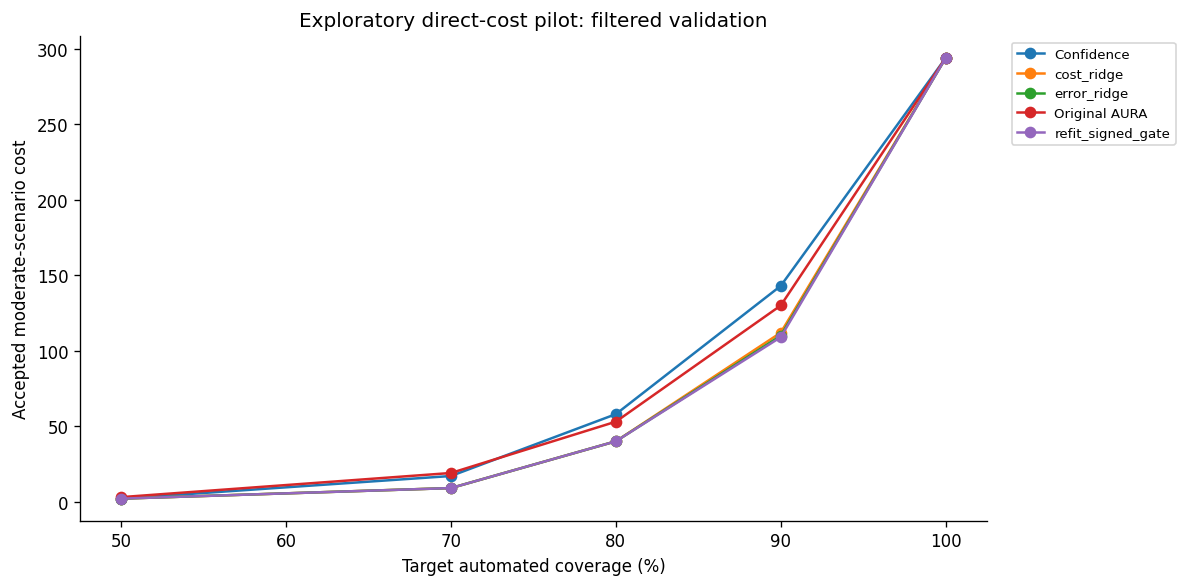

Paired routing bootstrap:   0%|          | 0/10000 [00:00<?, ?it/s]

Paired routing bootstrap:   0%|          | 0/10000 [00:00<?, ?it/s]

,coverage,difference_per_1000,lower_per_1000,upper_per_1000,resamples,candidate,reference,stage
0,0.8,0.0,-2.0,0.0,10000,cost_ridge,error_ridge,exploratory_development
1,0.8,0.0,-2.0,4.0,10000,cost_ridge,refit_signed_gate,exploratory_development


,selector,outside_0_1
0,error_ridge,460
1,cost_ridge,476


In [23]:
cal_normalized = normalized_text(cal_df.text)
val_normalized = normalized_text(val_df.text)
cal_keep = ~cal_normalized.isin(training_texts).to_numpy()
val_keep = ~val_normalized.isin(training_texts).to_numpy()
pilot_available = not (cal_normalized.duplicated(keep=False).any()
    or val_normalized.duplicated(keep=False).any()
    or len(set(cal_normalized) & set(val_normalized)) > 0)
pilot_report = None
pilot_intervals = []
if not pilot_available:
    print("Pilot skipped: a grouped development split is needed for duplicated/shared development text.")
else:
    fitting = cal_df.iloc[np.flatnonzero(cal_keep)].copy()
    evaluation = val_df.iloc[np.flatnonzero(val_keep)].copy()
    x_fit, x_eval = fit_features[cal_keep], val_features[val_keep]
    fit_predictions = calibrated_cal.argmax(axis=1)[cal_keep]
    fit_errors = (fit_predictions != fitting.label.to_numpy()).astype(int)
    fit_costs = C_MODERATE[fitting.label.to_numpy(), fit_predictions]
    support = pd.Series(fit_costs).value_counts().sort_index().rename_axis("moderate_cost").to_frame("fitting_examples")
    display(support)
    support.to_csv(RESULT_DIR / "pilot_cost_support.csv")
    print(f"Pilot fitting rows: {len(fitting)}; evaluation rows: {len(evaluation)}")
    maximum = float(C_MODERATE.max())
    pilot_selectors = {}
    for name, target in [("error_ridge", fit_errors), ("cost_ridge", fit_costs / maximum)]:
        pilot_selectors[name] = Pipeline([("scale", StandardScaler()), ("regressor", Ridge(alpha=1.0))]).fit(x_fit, target)
    pilot_gate = fit_correctness_gate(x_fit, 1 - fit_errors)
    pilot_scores = {name: selector.predict(x_eval) for name, selector in pilot_selectors.items()}
    pilot_scores.update({"refit_signed_gate": pilot_gate.predict_proba(x_eval)[:, 0],
        "confidence": all_val_scores["confidence"][val_keep],
        "original_aura": all_val_scores["original_aura"][val_keep]})
    pilot_probabilities = calibrated_val[val_keep]
    pilot_report, pilot_decisions = evaluate_score_policies(evaluation, pilot_probabilities, pilot_scores)
    display(pilot_report[(pilot_report.evaluation_scenario == "moderate") & (pilot_report.target_coverage == 0.8)])
    plot_policy_comparison(pilot_report, "Exploratory direct-cost pilot: filtered validation", "pilot_comparison.png")
    realized = C_MODERATE[evaluation.label.to_numpy(), pilot_probabilities.argmax(axis=1)]
    for reference in ["error_ridge", "refit_signed_gate"]:
        interval = paired_reranking_interval(pilot_scores[reference], pilot_scores["cost_ridge"],
            realized, evaluation.row_id.to_numpy())
        interval.update(candidate="cost_ridge", reference=reference, stage="exploratory_development")
        pilot_intervals.append(interval)
    display(pd.DataFrame(pilot_intervals))
    display(pd.DataFrame({"selector": list(pilot_selectors), "outside_0_1":
        [int(((pilot_scores[name] < 0) | (pilot_scores[name] > 1)).sum()) for name in pilot_selectors]}))
    pilot_report.to_csv(RESULT_DIR / "pilot_comparison.csv", index=False)
    pilot_decisions.to_csv(RESULT_DIR / "pilot_decisions.csv", index=False)
    pd.DataFrame(pilot_intervals).to_csv(RESULT_DIR / "pilot_intervals.csv", index=False)
    joblib.dump({"selectors": pilot_selectors, "refit_gate": pilot_gate,
        "fitting_row_ids": fitting.row_id.tolist(), "evaluation_row_ids": evaluation.row_id.tolist()},
        CHECKPOINT_DIR / "exploratory_cost_selectors.joblib")

### 11B. AURA on both DistilBERT and Ettin

```text
                         Same customer message
                         /                   \
                  DistilBERT                 Ettin-150M
                  77 logits                  77 logits
                     |                          |
             Own fitted temperature    Own fitted temperature
                     |                          |
             Own correctness gates     Own correctness gates
                     |                          |
             Same AURA costs, policies, and coverage budgets
                     |                          |
                 AUTO / DEFER              AUTO / DEFER
```

For encoder $m$, $p_m=softmax(z_m/T_m)$ and
$R_m(x)=\sum_i p_m(i\mid x)C_{i,\hat y_m}$. Fit temperatures and gates on
calibration rows only. **DistilBERT gates must not be reused for Ettin**: their
errors, margins, and agreement with the lexical witness differ. The independent
training-only witness, cost matrices, partitions and all 77 labels can stay shared.

Run all nine policies and guard-matched controls for each encoder. Compare AURA
against **that encoder's own confidence baseline** to isolate routing benefit.
Ettin+AURA versus DistilBERT+confidence changes both classifier and routing.
This new exploratory comparison does not amend the frozen DistilBERT final result.
Numeric costs remain research assumptions, not monetary losses.

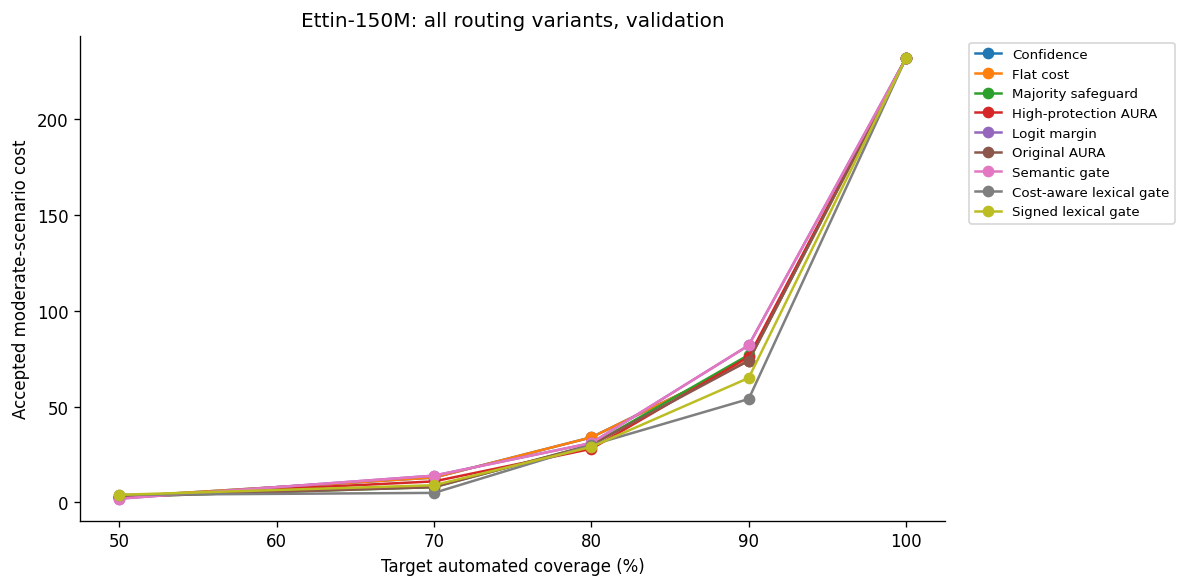

,policy,evaluation_scenario,target_coverage,requested_count,accepted_count,actual_coverage,deferred_count,accepted_errors,accepted_accuracy,accepted_total_cost,accepted_cost_per_input,cost_per_accepted,encoder,partition
67,confidence,moderate,0.8,1200,1200,0.799467,301,31,0.974167,58.0,0.038641,0.048333,DistilBERT,policy_validation
70,flat,moderate,0.8,1200,1200,0.799467,301,31,0.974167,58.0,0.038641,0.048333,DistilBERT,policy_validation
73,original_aura,moderate,0.8,1200,1200,0.799467,301,33,0.972500,52.0,0.034644,0.043333,DistilBERT,policy_validation
76,high_protection,moderate,0.8,1200,1200,0.799467,301,32,0.973333,47.0,0.031312,0.039167,DistilBERT,policy_validation
79,guarded_moderate,moderate,0.8,1200,1200,0.799467,301,33,0.972500,52.0,0.034644,0.043333,DistilBERT,policy_validation
82,logit_margin,moderate,0.8,1200,1200,0.799467,301,32,0.973333,55.0,0.036642,0.045833,DistilBERT,policy_validation
85,semantic_gate,moderate,0.8,1200,1200,0.799467,301,32,0.973333,55.0,0.036642,0.045833,DistilBERT,policy_validation
88,signed_gate,moderate,0.8,1200,1200,0.799467,301,21,0.982500,40.0,0.026649,0.033333,DistilBERT,policy_validation
91,signed_cost_gate,moderate,0.8,1200,1200,0.799467,301,20,0.983333,32.0,0.021319,0.026667,DistilBERT,policy_validation
94,confidence_guard_matched_count,moderate,0.8,1200,1200,0.799467,301,31,0.974167,58.0,0.038641,0.048333,DistilBERT,policy_validation


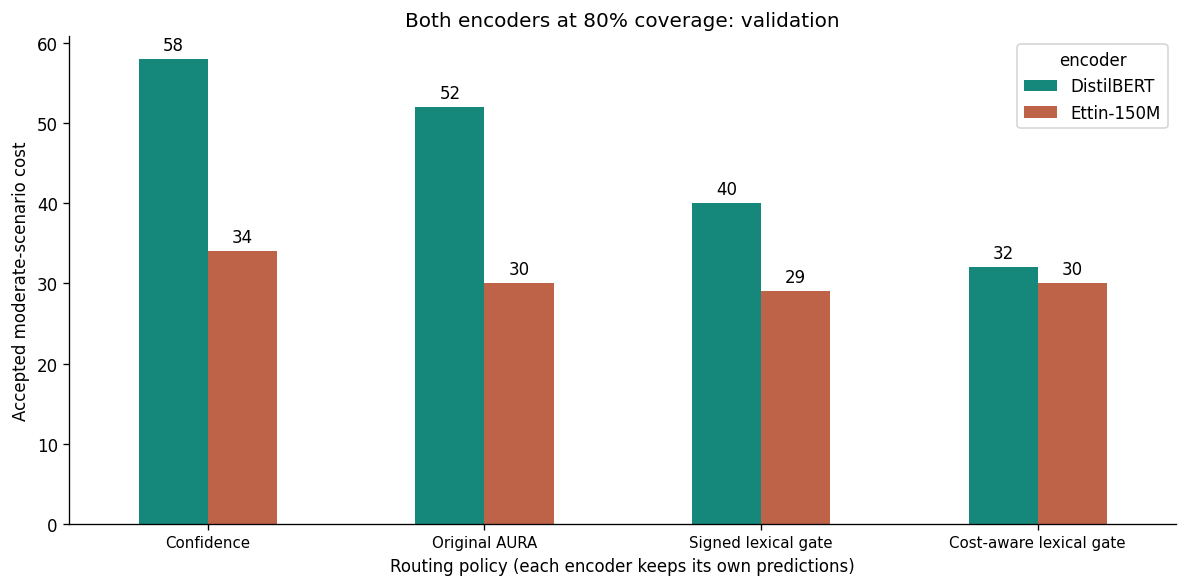

Paired routing bootstrap:   0%|          | 0/10000 [00:00<?, ?it/s]

Paired routing bootstrap:   0%|          | 0/10000 [00:00<?, ?it/s]

Paired routing bootstrap:   0%|          | 0/10000 [00:00<?, ?it/s]

,coverage,difference_per_1000,lower_per_1000,upper_per_1000,resamples,candidate,reference,stage,encoder
0,0.8,-5.329780,-10.659560,3.331113,10000,signed_cost_gate,signed_gate,development,DistilBERT
1,0.8,-13.324450,-21.985343,-3.331113,10000,signed_cost_gate,original_aura,development,DistilBERT
2,0.8,0.666223,-3.997335,5.329780,10000,signed_cost_gate,signed_gate,exploratory_development,Ettin-150M
3,0.8,0.000000,-7.328448,6.662225,10000,signed_cost_gate,original_aura,exploratory_development,Ettin-150M
4,0.8,-2.664890,-11.992005,1.998668,10000,original_aura,confidence,exploratory_development,Ettin-150M


In [24]:
ENCODER_ROUTING = {
    "DistilBERT": {
        "slug": "distilbert", "model": model, "tokenizer": tokenizer,
        "config": TRAINING_CONFIG, "checkpoint_sha256": DISTILBERT_CHECKPOINT_HASH,
        "temperature": TEMPERATURE,
        "gates": {"semantic_gate": semantic_gate, "signed_gate": signed_gate},
        "cal_logits": cal_logits, "val_logits": val_logits,
        "cal_probabilities": calibrated_cal, "val_probabilities": calibrated_val,
        "fit_features": fit_features, "val_features": val_features,
        "val_scores": all_val_scores, "val_report": all_val_report,
        "val_decisions": all_val_decisions,
    }
}
ETTIN_CHECKPOINT_HASH = fingerprint_checkpoint(ETTIN_MODEL_DIR)
ETTIN_ROUTING_SIGNATURE = hashlib.sha256(json.dumps({
    "encoder_signature": ETTIN_SIGNATURE, "checkpoint": ETTIN_CHECKPOINT_HASH,
    "calibration_ids": cal_df.row_id.tolist(), "gate_recipe": "lexical-gate-v1",
    "temperature": EXTRA_TEMPERATURES["Ettin-150M"],
}, sort_keys=True).encode()).hexdigest()
ETTIN_ROUTING_PATH = CHECKPOINT_DIR / f"ettin_routing_{ETTIN_ROUTING_SIGNATURE[:16]}.joblib"
ettin_fit_features = lexical_features(ettin_cal_logits,
    witness.decision_function(cal_df.text.tolist()), witness.classes_)
ettin_features = lexical_features(ettin_val_logits,
    witness.decision_function(val_df.text.tolist()), witness.classes_)
if REUSE_CHECKPOINTS and ETTIN_ROUTING_PATH.is_file():
    ettin_gate_artifact = joblib.load(ETTIN_ROUTING_PATH)
    if ettin_gate_artifact["signature"] != ETTIN_ROUTING_SIGNATURE:
        raise ValueError("Ettin routing checkpoint provenance mismatch.")
    ettin_gates = ettin_gate_artifact["gates"]
else:
    ettin_correct = (ettin_cal_logits.argmax(axis=1) == cal_df.label.to_numpy()).astype(int)
    ettin_gates = {
        "semantic_gate": fit_correctness_gate(ettin_fit_features[:, :1], ettin_correct),
        "signed_gate": fit_correctness_gate(ettin_fit_features, ettin_correct),
    }
    joblib.dump({"signature": ETTIN_ROUTING_SIGNATURE, "gates": ettin_gates}, ETTIN_ROUTING_PATH)
ettin_p = extra_calibrated_val["Ettin-150M"]
ettin_scores = routing_variant_scores(ettin_p, ettin_features, gates=ettin_gates)
ettin_report, ettin_decisions = evaluate_score_policies(val_df, ettin_p, ettin_scores, include_guard=True)
ENCODER_ROUTING["Ettin-150M"] = {
    "slug": "ettin", "model": ettin_model, "tokenizer": ettin_tokenizer,
    "config": ETTIN_CONFIG, "checkpoint_sha256": ETTIN_CHECKPOINT_HASH,
    "temperature": EXTRA_TEMPERATURES["Ettin-150M"], "gates": ettin_gates,
    "cal_logits": ettin_cal_logits, "val_logits": ettin_val_logits,
    "cal_probabilities": softmax(ettin_cal_logits / EXTRA_TEMPERATURES["Ettin-150M"], axis=1),
    "val_probabilities": ettin_p, "fit_features": ettin_fit_features,
    "val_features": ettin_features, "val_scores": ettin_scores,
    "val_report": ettin_report, "val_decisions": ettin_decisions,
}

def export_encoder_logits(name, state, partition, frame, logits):
    directory = RESULT_DIR / "encoder_logits" / state["slug"]
    directory.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(directory / f"{partition}.npz",
        schema_version=1, encoder=name, checkpoint_sha256=state["checkpoint_sha256"],
        partition=partition, classes=np.arange(NUM_CLASSES), intent_names=np.asarray(INTENTS),
        row_indices=frame.row_id.to_numpy(), logits=logits,
        training_fingerprint=DATA_FINGERPRINT, partition_fingerprint=training_fingerprint(frame))

def save_encoder_routing(name, state, partition, frame, probabilities, scores, report, decisions):
    directory = RESULT_DIR / "routing" / state["slug"]
    directory.mkdir(parents=True, exist_ok=True)
    report = report.assign(encoder=name, partition=partition)
    report.to_csv(directory / f"comparison_{partition}.csv", index=False)
    decisions.assign(encoder=name).to_csv(directory / f"decisions_{partition}.csv", index=False)
    pd.DataFrame({"row_id": frame.row_id.to_numpy(), **scores}).to_csv(directory / f"scores_{partition}.csv", index=False)
    np.savez_compressed(directory / f"probabilities_{partition}.npz",
        row_indices=frame.row_id.to_numpy(), classes=np.arange(NUM_CLASSES), probabilities=probabilities)
    (directory / "routing_configuration.json").write_text(json.dumps({
        "encoder": name, "checkpoint_sha256": state["checkpoint_sha256"],
        "temperature": state["temperature"], "gate_fit_partition": "calibration",
        "gate_fit_rows": len(cal_df), "cost_unit": "relative_research_cost",
        "evaluation_stage": "exploratory_encoder_comparison", "policies": list(POLICY_LABELS),
    }, indent=2))
    return report

def plot_encoder_comparison(report, partition):
    policies = ["confidence", "original_aura", "signed_gate", "signed_cost_gate"]
    selected = report[(report.evaluation_scenario == "moderate") & (report.target_coverage == 0.8)]
    table = selected.pivot(index="policy", columns="encoder", values="accepted_total_cost").reindex(policies)
    ax = table.plot.bar(figsize=(10, 5), color=["#16877b", "#bf6348"], rot=0)
    ax.set_xticklabels([POLICY_LABELS[p] for p in policies], fontsize=9)
    ax.set(xlabel="Routing policy (each encoder keeps its own predictions)",
        ylabel="Accepted moderate-scenario cost", title=f"Both encoders at 80% coverage: {partition}")
    for container in ax.containers:
        ax.bar_label(container, fmt="%.0f", padding=3)
    ax.figure.tight_layout()
    ax.figure.savefig(RESULT_DIR / f"encoder_routing_{partition}.png", dpi=180)
    plt.show()

encoder_validation_reports = []
for name, state in ENCODER_ROUTING.items():
    export_encoder_logits(name, state, "calibration", cal_df, state["cal_logits"])
    export_encoder_logits(name, state, "policy_validation", val_df, state["val_logits"])
    encoder_validation_reports.append(save_encoder_routing(name, state, "policy_validation",
        val_df, state["val_probabilities"], state["val_scores"], state["val_report"], state["val_decisions"]))
    if name == "Ettin-150M":
        plot_policy_comparison(state["val_report"], f"{name}: all routing variants, validation",
            "ettin_all_routing_validation.png")
        first_report, _ = evaluate_routing(val_df, state["val_probabilities"])
        first_report.to_csv(RESULT_DIR / "routing" / state["slug"] / "first_aura_validation.csv", index=False)
encoder_validation_report = pd.concat(encoder_validation_reports, ignore_index=True)
encoder_validation_report.to_csv(RESULT_DIR / "encoder_routing_validation.csv", index=False)
display(encoder_validation_report[(encoder_validation_report.evaluation_scenario == "moderate") &
    (encoder_validation_report.target_coverage == 0.8)])
plot_encoder_comparison(encoder_validation_report, "validation")

encoder_validation_intervals = [dict(row, encoder="DistilBERT") for row in validation_intervals]
ettin_realized = C_MODERATE[val_df.label.to_numpy(), ettin_p.argmax(axis=1)]
for candidate, reference in [("signed_cost_gate", "signed_gate"),
                             ("signed_cost_gate", "original_aura"), ("original_aura", "confidence")]:
    interval = paired_reranking_interval(ettin_scores[reference], ettin_scores[candidate],
        ettin_realized, val_df.row_id.to_numpy())
    interval.update(encoder="Ettin-150M", candidate=candidate, reference=reference, stage="exploratory_development")
    encoder_validation_intervals.append(interval)
display(pd.DataFrame(encoder_validation_intervals))
pd.DataFrame(encoder_validation_intervals).to_csv(RESULT_DIR / "encoder_intervals_validation.csv", index=False)

### 11C. Direct-cost pilot on Ettin (development only)

Keep the same filtered calibration/validation rows, Ridge settings and five pilot
selectors. Targets now use **Ettin's own errors and costs**. Fit new selectors,
not copies of DistilBERT's. They remain exploratory, unbounded ranking scores and
are not used in the live demo or on test data.

,policy,evaluation_scenario,target_coverage,requested_count,accepted_count,actual_coverage,deferred_count,accepted_errors,accepted_accuracy,accepted_total_cost,accepted_cost_per_input,cost_per_accepted
31,error_ridge,moderate,0.8,1200,1200,0.8,300,16,0.986667,28.0,0.018667,0.023333
34,cost_ridge,moderate,0.8,1200,1200,0.8,300,16,0.986667,28.0,0.018667,0.023333
37,refit_signed_gate,moderate,0.8,1200,1200,0.8,300,16,0.986667,29.0,0.019333,0.024167
40,confidence,moderate,0.8,1200,1200,0.8,300,17,0.985833,34.0,0.022667,0.028333
43,original_aura,moderate,0.8,1200,1200,0.8,300,17,0.985833,30.0,0.020000,0.025000


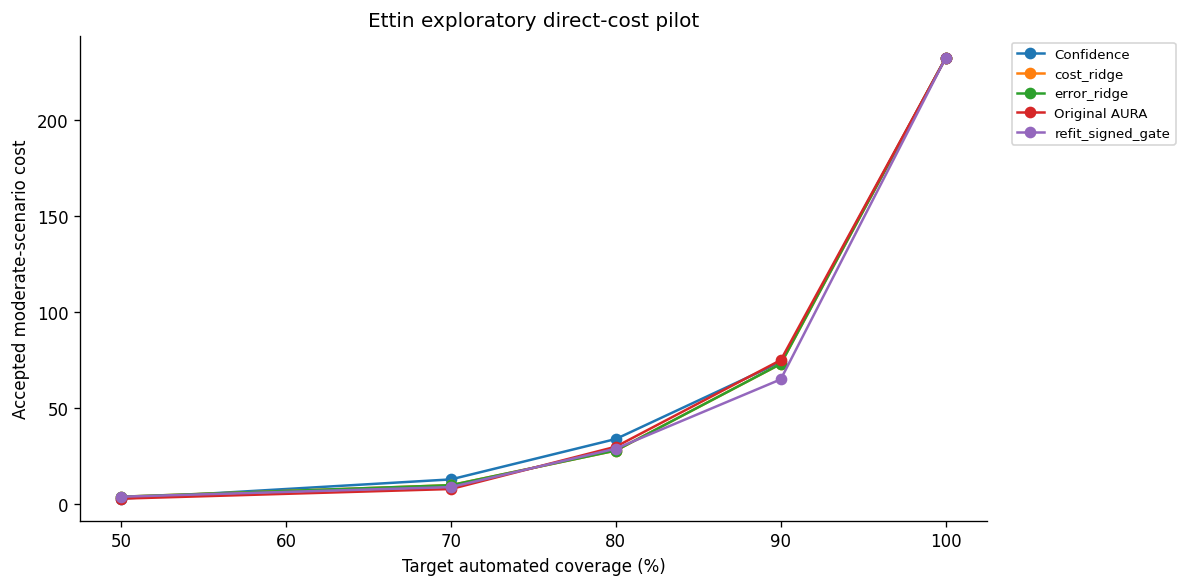

In [25]:
ettin_pilot_report = None
if pilot_available:
    state = ENCODER_ROUTING["Ettin-150M"]
    fitting = cal_df.iloc[np.flatnonzero(cal_keep)].copy()
    evaluation = val_df.iloc[np.flatnonzero(val_keep)].copy()
    x_fit, x_eval = state["fit_features"][cal_keep], state["val_features"][val_keep]
    predicted = state["cal_probabilities"].argmax(axis=1)[cal_keep]
    errors = (predicted != fitting.label.to_numpy()).astype(int)
    costs = C_MODERATE[fitting.label.to_numpy(), predicted]
    pilot_dir = RESULT_DIR / "routing" / "ettin" / "pilot"
    pilot_dir.mkdir(parents=True, exist_ok=True)
    pd.Series(costs).value_counts().sort_index().rename_axis("moderate_cost").to_csv(pilot_dir / "support.csv")
    selectors = {name: Pipeline([("scale", StandardScaler()), ("regressor", Ridge(alpha=1.0))]).fit(x_fit, target)
        for name, target in [("error_ridge", errors), ("cost_ridge", costs / float(C_MODERATE.max()))]}
    refit_gate = fit_correctness_gate(x_fit, 1 - errors)
    pilot_scores_ettin = {name: selector.predict(x_eval) for name, selector in selectors.items()}
    pilot_scores_ettin.update({"refit_signed_gate": refit_gate.predict_proba(x_eval)[:, 0],
        "confidence": state["val_scores"]["confidence"][val_keep],
        "original_aura": state["val_scores"]["original_aura"][val_keep]})
    ettin_pilot_report, decisions = evaluate_score_policies(
        evaluation, state["val_probabilities"][val_keep], pilot_scores_ettin)
    ettin_pilot_report.assign(encoder="Ettin-150M").to_csv(pilot_dir / "comparison.csv", index=False)
    decisions.to_csv(pilot_dir / "decisions.csv", index=False)
    joblib.dump({"encoder": "Ettin-150M", "checkpoint_sha256": ETTIN_CHECKPOINT_HASH,
        "selectors": selectors, "refit_gate": refit_gate,
        "fitting_row_ids": fitting.row_id.tolist(), "evaluation_row_ids": evaluation.row_id.tolist()},
        pilot_dir / "selectors.joblib")
    display(ettin_pilot_report[(ettin_pilot_report.evaluation_scenario == "moderate") &
        (ettin_pilot_report.target_coverage == 0.8)])
    plot_policy_comparison(ettin_pilot_report, "Ettin exploratory direct-cost pilot", "ettin_pilot.png")

## 12. Official test-partition evaluation

This section downloads the 3,080 official test examples and evaluates all four
classifiers, DistilBERT calibration, and the **first AURA policy**. It uses the
already-fixed models, temperature, costs, and coverage levels. It does not fit
anything on test labels. Set `RUN_OFFICIAL_TEST = False` above if you only want the
development demonstration.

The project has already inspected this test partition historically. This is a
new Colab reproduction/demo run, not new independent confirmation or the archived
final protocol runner. Do not tune settings to these results and then claim an
unseen-test improvement. We report normalized text overlap and retain all rows,
consistent with the original analysis population.

,count
test_messages,3080
normalized_matches_to_training_pool,7
normalized_duplicate_members_in_test,2


Official test inference:   0%|          | 0/193 [00:00<?, ?it/s]

Ettin official test inference:   0%|          | 0/385 [00:00<?, ?it/s]

,model,accuracy,macro_f1,log_loss,ece,brier
0,Logistic Regression,0.856169,0.856382,1.400585,0.501079,0.507397
1,Random Forest,0.777597,0.775027,1.817714,0.529901,0.645933
2,DistilBERT,0.899026,0.897319,0.424679,0.090187,0.155523
3,Ettin-150M,0.920130,0.920293,0.312153,0.023031,0.119595


,model,accuracy,macro_f1,log_loss,ece,brier
0,Raw DistilBERT,0.899026,0.897319,0.424679,0.090187,0.155523
1,Calibrated DistilBERT,0.899026,0.897319,0.359131,0.018923,0.145846


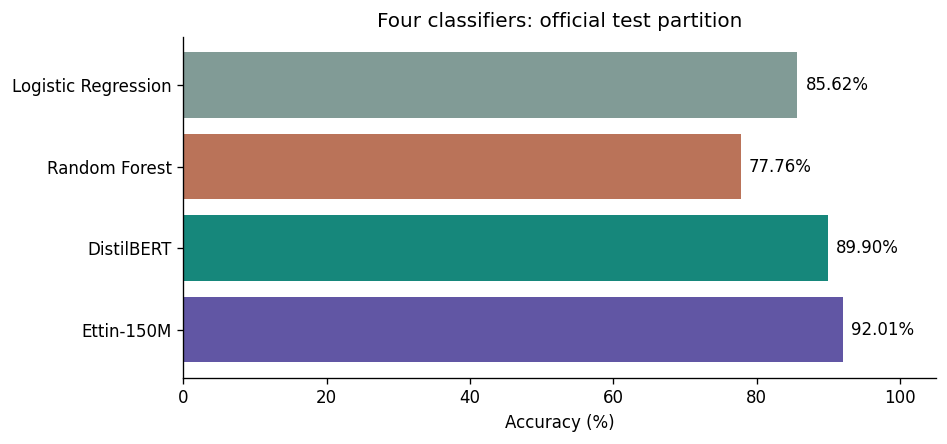

,policy,evaluation_scenario,target_coverage,actual_coverage,accepted,deferred,accepted_errors,accepted_accuracy,accepted_cost,cost_per_input
1,Confidence,moderate,0.5,0.5,1540,1540,9,0.994156,13.0,0.004221
4,First AURA,moderate,0.5,0.5,1540,1540,10,0.993506,15.0,0.004870
7,Confidence,moderate,0.7,0.7,2156,924,30,0.986085,45.0,0.014610
10,First AURA,moderate,0.7,0.7,2156,924,34,0.984230,47.0,0.015260
13,Confidence,moderate,0.8,0.8,2464,616,58,0.976461,92.0,0.029870
16,First AURA,moderate,0.8,0.8,2464,616,70,0.971591,103.0,0.033442
19,Confidence,moderate,0.9,0.9,2772,308,136,0.950938,219.0,0.071104
22,First AURA,moderate,0.9,0.9,2772,308,147,0.946970,222.0,0.072078
25,Confidence,moderate,1.0,1.0,3080,0,311,0.899026,575.0,0.186688
28,First AURA,moderate,1.0,1.0,3080,0,311,0.899026,575.0,0.186688


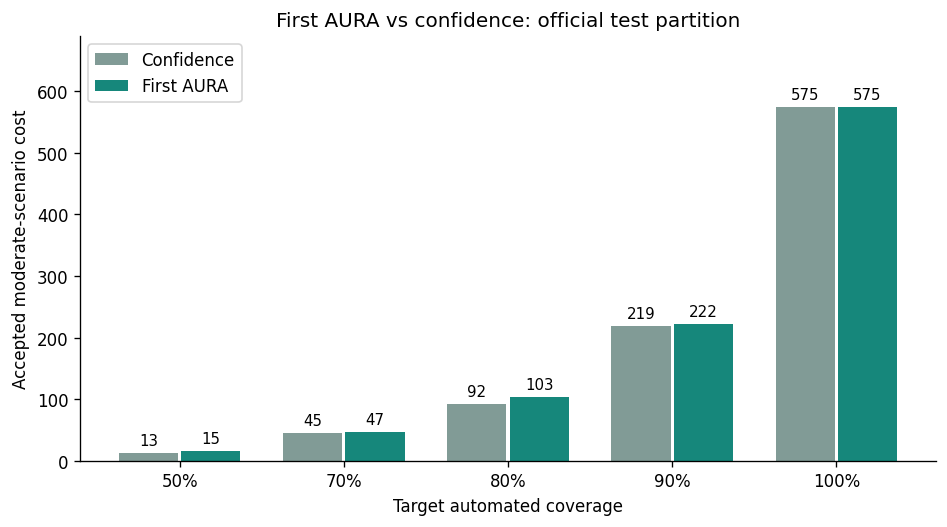

In [26]:
test_summary = None
if RUN_OFFICIAL_TEST:
    test_df = prepare_frame(pd.read_csv(f"{DATA_URL}/test.csv"))
    def normalize_text(series):
        return series.str.lower().str.split().str.join(" ")
    normalized_test = normalize_text(test_df.text)
    normalized_pool = set(normalize_text(train_pool.text))
    overlap_summary = {"test_messages": len(test_df),
        "normalized_matches_to_training_pool": int(normalized_test.isin(normalized_pool).sum()),
        "normalized_duplicate_members_in_test": int(normalized_test.duplicated(keep=False).sum())}
    display(pd.Series(overlap_summary).to_frame("count"))

    test_logits = predict_logits(test_df.text, "Official test inference")
    test_probabilities = {name: aligned_probabilities(pipeline, test_df.text)
                         for name, pipeline in classical_models.items()}
    test_probabilities["DistilBERT"] = softmax(test_logits, axis=1)
    ettin_test_logits = predict_logits(test_df.text, "Ettin official test inference",
        trained_model=ettin_model, trained_tokenizer=ettin_tokenizer, config=ETTIN_CONFIG)
    test_probabilities["Ettin-150M"] = softmax(ettin_test_logits, axis=1)
    test_metrics = pd.DataFrame([
        classification_metrics(name, test_df.label, p) for name, p in test_probabilities.items()])
    calibrated_test = softmax(test_logits / TEMPERATURE, axis=1)
    test_calibration = pd.DataFrame([
        classification_metrics("Raw DistilBERT", test_df.label, test_probabilities["DistilBERT"]),
        classification_metrics("Calibrated DistilBERT", test_df.label, calibrated_test),
    ])
    display(test_metrics)
    display(test_calibration)
    plot_classifier_accuracy(test_metrics, "Four classifiers: official test partition", "classifier_test.png")
    test_routing, test_decisions = evaluate_routing(test_df, calibrated_test)
    display(test_routing[test_routing.evaluation_scenario == "moderate"])
    plot_routing(test_routing, "First AURA vs confidence: official test partition", "routing_test.png")
    test_metrics.to_csv(RESULT_DIR / "classification_test.csv", index=False)
    test_calibration.to_csv(RESULT_DIR / "calibration_test.csv", index=False)
    test_routing.to_csv(RESULT_DIR / "routing_test.csv", index=False)
    test_decisions.to_csv(RESULT_DIR / "decisions_test.csv", index=False)
    test_summary = overlap_summary
else:
    print("Official-test evaluation skipped; development results remain available.")

### 12B. Test all frozen routing variants in this Colab run

The lexical witness and gates are already fitted on development data. No fitting
occurs here. The guard may miss a target because it does not backfill confidence
<= 0.5; matched-count controls prevent crediting it for merely accepting less.
The same signed-cost-vs-signed primary contrast is reported, but this new Colab
run does not replace the archived final protocol, model, or historical result.

,policy,evaluation_scenario,target_coverage,requested_count,accepted_count,actual_coverage,deferred_count,accepted_errors,accepted_accuracy,accepted_total_cost,accepted_cost_per_input,cost_per_accepted
67,confidence,moderate,0.8,2464,2464,0.8,616,58,0.976461,92.0,0.029870,0.037338
70,flat,moderate,0.8,2464,2464,0.8,616,58,0.976461,92.0,0.029870,0.037338
73,original_aura,moderate,0.8,2464,2464,0.8,616,70,0.971591,103.0,0.033442,0.041802
76,high_protection,moderate,0.8,2464,2464,0.8,616,77,0.968750,106.0,0.034416,0.043019
79,guarded_moderate,moderate,0.8,2464,2464,0.8,616,70,0.971591,103.0,0.033442,0.041802
82,logit_margin,moderate,0.8,2464,2464,0.8,616,58,0.976461,92.0,0.029870,0.037338
85,semantic_gate,moderate,0.8,2464,2464,0.8,616,58,0.976461,92.0,0.029870,0.037338
88,signed_gate,moderate,0.8,2464,2464,0.8,616,36,0.985390,56.0,0.018182,0.022727
91,signed_cost_gate,moderate,0.8,2464,2464,0.8,616,36,0.985390,52.0,0.016883,0.021104
94,confidence_guard_matched_count,moderate,0.8,2464,2464,0.8,616,58,0.976461,92.0,0.029870,0.037338


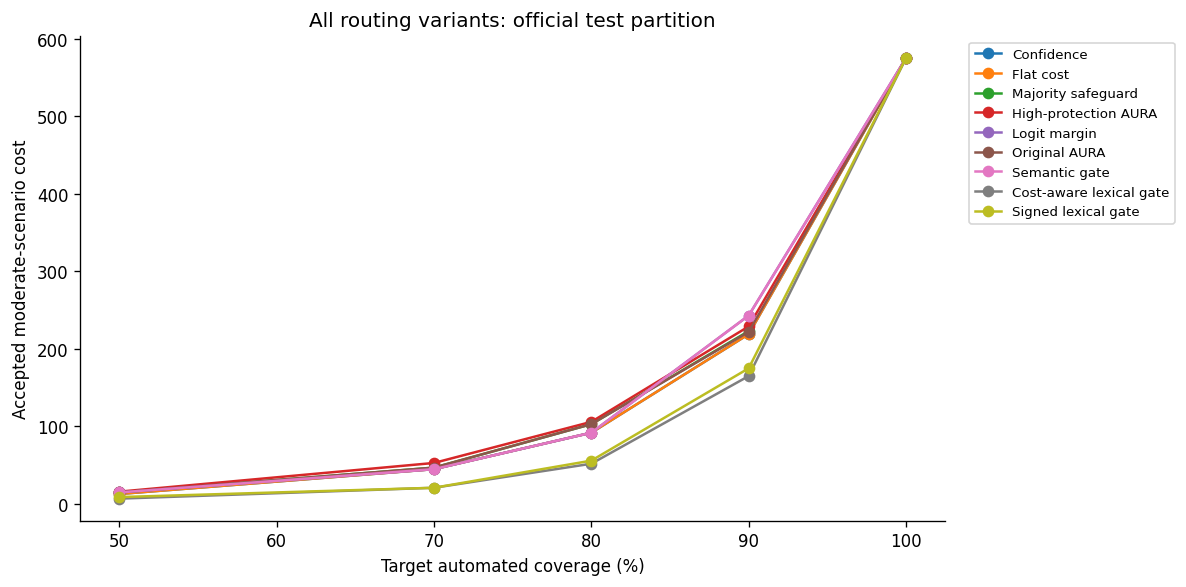

Paired routing bootstrap:   0%|          | 0/10000 [00:00<?, ?it/s]

,value
coverage,0.8
difference_per_1000,-1.298701
lower_per_1000,-4.545455
upper_per_1000,4.220779
resamples,10000
candidate,signed_cost_gate
reference,signed_gate
stage,colab_test_reproduction


,model,accuracy,macro_f1,log_loss,ece,brier
0,Logistic Regression,0.856169,0.856382,0.529468,0.019820,0.207239
1,Ettin-150M,0.920130,0.920293,0.306978,0.008885,0.119235


In [27]:
all_test_report = None
test_primary_interval = None
if RUN_OFFICIAL_TEST:
    DATA_TABLES["Official test (evaluated)"] = test_df
    partition_selector.options = list(DATA_TABLES)
    test_df.to_csv(DATA_DIR / "official_test.csv", index=False)
    test_features = lexical_features(test_logits, witness.decision_function(test_df.text.tolist()),
                                     witness.named_steps["classifier"].classes_)
    all_test_scores = routing_variant_scores(calibrated_test, test_features)
    all_test_report, all_test_decisions = evaluate_score_policies(
        test_df, calibrated_test, all_test_scores, include_guard=True)
    display(all_test_report[(all_test_report.evaluation_scenario == "moderate") &
                            (all_test_report.target_coverage == 0.8)])
    plot_policy_comparison(all_test_report, "All routing variants: official test partition", "all_routing_test.png")
    test_costs = C_MODERATE[test_df.label.to_numpy(), calibrated_test.argmax(axis=1)]
    test_primary_interval = paired_reranking_interval(all_test_scores["signed_gate"],
        all_test_scores["signed_cost_gate"], test_costs, test_df.row_id.to_numpy())
    test_primary_interval.update(candidate="signed_cost_gate", reference="signed_gate",
                                 stage="colab_test_reproduction")
    display(pd.Series(test_primary_interval).to_frame("value"))
    all_test_report.to_csv(RESULT_DIR / "all_routing_test.csv", index=False)
    all_test_decisions.to_csv(RESULT_DIR / "all_decisions_test.csv", index=False)
    pd.DataFrame({"row_id": test_df.row_id.to_numpy(), **all_test_scores}).to_csv(
        RESULT_DIR / "all_scores_test.csv", index=False)
    (RESULT_DIR / "test_primary_interval.json").write_text(json.dumps(test_primary_interval, indent=2))
    extra_test_calibration = []
    supplementary_test = {
        "Logistic Regression": softmax(classical_models["Logistic Regression"].decision_function(
            test_df.text.tolist()) / EXTRA_TEMPERATURES["Logistic Regression"], axis=1),
        "Ettin-150M": softmax(ettin_test_logits / EXTRA_TEMPERATURES["Ettin-150M"], axis=1)}
    for name, p in supplementary_test.items():
        extra_test_calibration.append(classification_metrics(name, test_df.label, p))
    display(pd.DataFrame(extra_test_calibration))
    pd.DataFrame(extra_test_calibration).to_csv(RESULT_DIR / "additional_calibration_test.csv", index=False)

### 12C. Apply Ettin's frozen AURA layer to the official test partition

No temperatures, gates, costs or budgets are fitted here. These are exploratory
results on an already-exposed test set, not a new confirmatory final experiment.
Each encoder's routing uses its own predictions; compare within-encoder baselines.

,policy,evaluation_scenario,target_coverage,requested_count,accepted_count,actual_coverage,deferred_count,accepted_errors,accepted_accuracy,accepted_total_cost,accepted_cost_per_input,cost_per_accepted,encoder,partition
67,confidence,moderate,0.8,2464,2464,0.8,616,58,0.976461,92.0,0.029870,0.037338,DistilBERT,test
70,flat,moderate,0.8,2464,2464,0.8,616,58,0.976461,92.0,0.029870,0.037338,DistilBERT,test
73,original_aura,moderate,0.8,2464,2464,0.8,616,70,0.971591,103.0,0.033442,0.041802,DistilBERT,test
76,high_protection,moderate,0.8,2464,2464,0.8,616,77,0.968750,106.0,0.034416,0.043019,DistilBERT,test
79,guarded_moderate,moderate,0.8,2464,2464,0.8,616,70,0.971591,103.0,0.033442,0.041802,DistilBERT,test
82,logit_margin,moderate,0.8,2464,2464,0.8,616,58,0.976461,92.0,0.029870,0.037338,DistilBERT,test
85,semantic_gate,moderate,0.8,2464,2464,0.8,616,58,0.976461,92.0,0.029870,0.037338,DistilBERT,test
88,signed_gate,moderate,0.8,2464,2464,0.8,616,36,0.985390,56.0,0.018182,0.022727,DistilBERT,test
91,signed_cost_gate,moderate,0.8,2464,2464,0.8,616,36,0.985390,52.0,0.016883,0.021104,DistilBERT,test
94,confidence_guard_matched_count,moderate,0.8,2464,2464,0.8,616,58,0.976461,92.0,0.029870,0.037338,DistilBERT,test


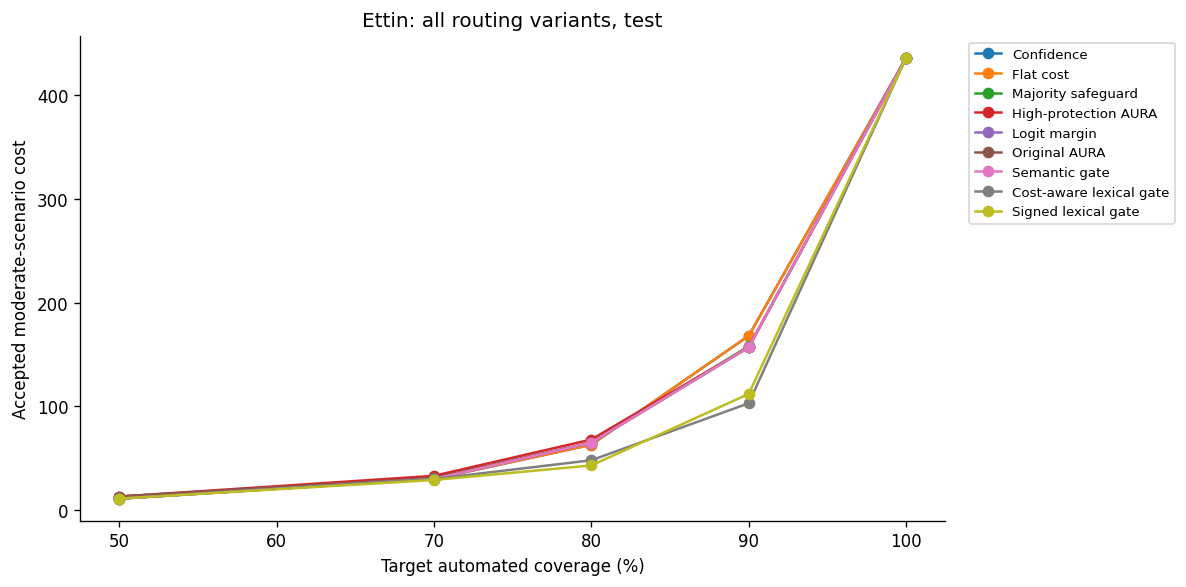

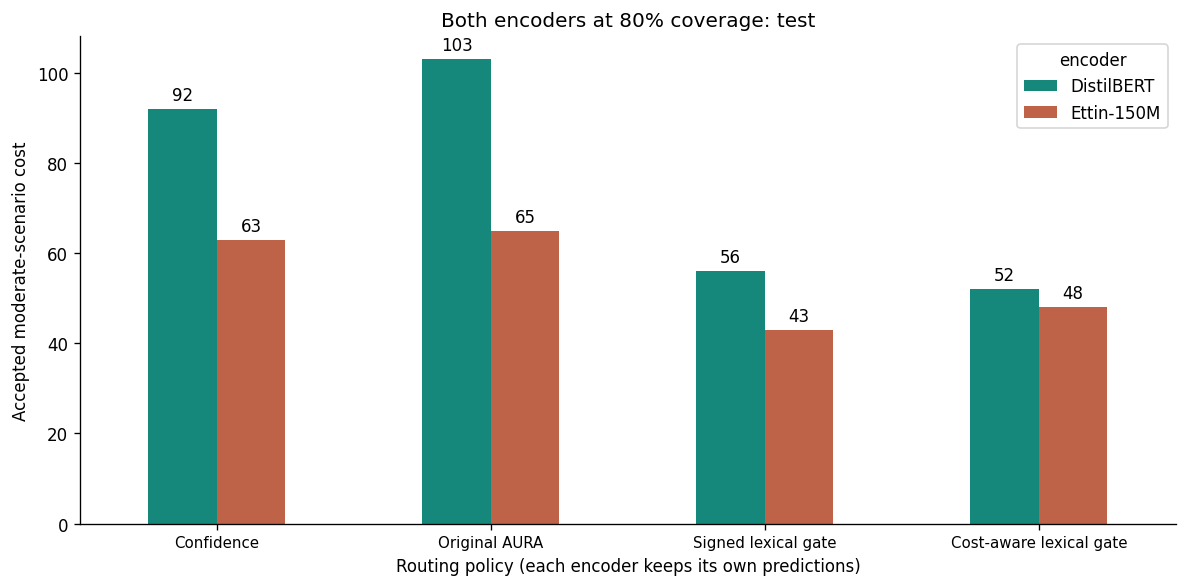

Paired routing bootstrap:   0%|          | 0/10000 [00:00<?, ?it/s]

,Ettin interval
coverage,0.8
difference_per_1000,1.623377
lower_per_1000,-1.623377
upper_per_1000,3.246753
resamples,10000
encoder,Ettin-150M
candidate,signed_cost_gate
reference,signed_gate
stage,exploratory_already_exposed_test


In [28]:
encoder_test_report = None
if RUN_OFFICIAL_TEST:
    ENCODER_ROUTING["DistilBERT"].update(test_logits=test_logits,
        test_probabilities=calibrated_test, test_scores=all_test_scores,
        test_report=all_test_report, test_decisions=all_test_decisions)
    state = ENCODER_ROUTING["Ettin-150M"]
    ettin_test_p = softmax(ettin_test_logits / state["temperature"], axis=1)
    features = lexical_features(ettin_test_logits, witness.decision_function(test_df.text.tolist()), witness.classes_)
    scores = routing_variant_scores(ettin_test_p, features, gates=state["gates"])
    report, decisions = evaluate_score_policies(test_df, ettin_test_p, scores, include_guard=True)
    state.update(test_logits=ettin_test_logits, test_probabilities=ettin_test_p,
        test_scores=scores, test_report=report, test_decisions=decisions)
    reports = []
    for name, state in ENCODER_ROUTING.items():
        export_encoder_logits(name, state, "test", test_df, state["test_logits"])
        reports.append(save_encoder_routing(name, state, "test", test_df, state["test_probabilities"],
            state["test_scores"], state["test_report"], state["test_decisions"]))
    encoder_test_report = pd.concat(reports, ignore_index=True)
    encoder_test_report.to_csv(RESULT_DIR / "encoder_routing_test.csv", index=False)
    display(encoder_test_report[(encoder_test_report.evaluation_scenario == "moderate") &
        (encoder_test_report.target_coverage == 0.8)])
    plot_policy_comparison(report, "Ettin: all routing variants, test", "ettin_all_routing_test.png")
    plot_encoder_comparison(encoder_test_report, "test")
    ettin_test_cost = C_MODERATE[test_df.label.to_numpy(), ettin_test_p.argmax(axis=1)]
    ettin_test_interval = paired_reranking_interval(scores["signed_gate"], scores["signed_cost_gate"],
        ettin_test_cost, test_df.row_id.to_numpy())
    ettin_test_interval.update(encoder="Ettin-150M", candidate="signed_cost_gate",
        reference="signed_gate", stage="exploratory_already_exposed_test")
    (RESULT_DIR / "routing" / "ettin" / "test_interval.json").write_text(json.dumps(ettin_test_interval, indent=2))
    display(pd.Series(ettin_test_interval).to_frame("Ettin interval"))

## 13. Live AUTO / DEFER demonstration

Change `DEMO_MESSAGES` and rerun the next cell. New messages have no known labels:
we show predictions, calibrated confidence, expected scenario risk, and the
largest risk contribution, rather than claiming they are correct.

The original AURA accepts a fixed fraction of a **batch**. A single message does
not have a standalone decision at a coverage percentage. For this live demo only,
we freeze a score cutoff at the development-validation 70% boundary and apply it
to new messages. This is a convenient illustrative threshold, **not** a validated
deployment policy or the exact-budget method used in the evaluation graphs.
Coverage on new messages is not guaranteed to be 70%; a risk-score tie at the cutoff
is accepted. No test scores or labels are used to choose this cutoff.

In [29]:
DEMO_COVERAGE = 0.70
boundary_count = int((Decimal(str(DEMO_COVERAGE)) * len(val_df)).to_integral_value(rounding=ROUND_FLOOR))
val_risks = expected_risk(calibrated_val, C_MODERATE)
FROZEN_RISK_CUTOFF = float(np.sort(val_risks)[boundary_count - 1])
FROZEN_CONFIDENCE_CUTOFF = float(np.sort(calibrated_val.max(axis=1))[-boundary_count])
print(f"Validation-derived illustrative risk cutoff: {FROZEN_RISK_CUTOFF:.6f}")

DEMO_MESSAGES = [
    "My new card has not arrived yet. Can I track it?",
    "I do not recognize a card payment on my account.",
    "I made a transfer but the recipient has not received it.",
    "How do I change my card PIN?",
]

def demonstrate_messages(messages):
    if not messages or any(not isinstance(message, str) or not message.strip() for message in messages):
        raise ValueError("Provide one or more non-empty messages.")
    probabilities = softmax(predict_logits(messages, show_progress=False) / TEMPERATURE, axis=1)
    predicted = probabilities.argmax(axis=1)
    contributions = probabilities * C_MODERATE[:, predicted].T
    risks = contributions.sum(axis=1)
    confidence = probabilities.max(axis=1)
    drivers = contributions.argmax(axis=1)
    results = pd.DataFrame({"message": messages,
        "predicted_intent": [INTENTS[i] for i in predicted],
        "calibrated_confidence": confidence, "expected_scenario_cost": risks,
        "largest_risk_driver": [INTENTS[i] for i in drivers],
        "driver_contribution": contributions[np.arange(len(messages)), drivers],
        "confidence_demo_decision": np.where(confidence >= FROZEN_CONFIDENCE_CUTOFF, "AUTO", "DEFER"),
        "AURA_demo_decision": np.where(risks <= FROZEN_RISK_CUTOFF, "AUTO", "DEFER")})
    return results

demo_results = demonstrate_messages(DEMO_MESSAGES)
with pd.option_context("display.max_colwidth", 100, "display.max_columns", None):
    display(demo_results)

Validation-derived illustrative risk cutoff: 0.116514


,message,predicted_intent,calibrated_confidence,expected_scenario_cost,largest_risk_driver,driver_contribution,confidence_demo_decision,AURA_demo_decision
0,My new card has not arrived yet. Can I track it?,card_arrival,0.987929,0.034809,lost_or_stolen_card,0.010366,AUTO,AUTO
1,I do not recognize a card payment on my account.,card_payment_not_recognised,0.990876,0.014983,pending_card_payment,0.003286,AUTO,AUTO
2,I made a transfer but the recipient has not received it.,transfer_not_received_by_recipient,0.976067,0.033426,balance_not_updated_after_bank_transfer,0.008882,AUTO,AUTO
3,How do I change my card PIN?,change_pin,0.988134,0.021418,get_physical_card,0.004264,AUTO,AUTO


### Inspect one message's risk calculation

The largest driver can be an alternative intent, even when the predicted intent
has high confidence. Its contribution is `probability × cost`. This explains
where the number comes from; it is not a causal explanation of customer harm.

In [30]:
MESSAGE_TO_EXPLAIN = DEMO_MESSAGES[1]
p = softmax(predict_logits([MESSAGE_TO_EXPLAIN], show_progress=False) / TEMPERATURE, axis=1)[0]
route = int(p.argmax())
explanation = pd.DataFrame({"possible_true_intent": INTENTS, "probability": p,
    "cost_if_predicted_route_is_accepted": C_MODERATE[:, route],
    "risk_contribution": p * C_MODERATE[:, route]})
print("Message:", MESSAGE_TO_EXPLAIN)
print("Predicted route:", INTENTS[route])
print("Expected scenario cost:", explanation.risk_contribution.sum())
display(explanation.sort_values("risk_contribution", ascending=False).head(8))

Message: I do not recognize a card payment on my account.
Predicted route: card_payment_not_recognised
Expected scenario cost: 0.014982550935520318


,possible_true_intent,probability,cost_if_predicted_route_is_accepted,risk_contribution
45,pending_card_payment,0.001643,2.0,0.003286
28,direct_debit_payment_not_recognised,0.003150,1.0,0.003150
53,reverted_card_payment?,0.000884,2.0,0.001767
25,declined_card_payment,0.000229,2.0,0.000458
15,card_payment_fee_charged,0.000203,2.0,0.000407
29,disposable_card_limits,0.000191,2.0,0.000381
54,supported_cards_and_currencies,0.000169,2.0,0.000338
22,compromised_card,0.000151,2.0,0.000303


### 13B. Interactive routing with any implemented policy

Choose a policy, enter a message and press **Run prediction**. Choose either encoder; policies retain its intent and use its own temperature and gates. The demo cutoff is derived only from validation scores at the
chosen coverage, not test results. Actual coverage on future inputs is unknown.
The majority guard additionally requires confidence > 0.5. These are illustrative
single-message cutoffs, separate from the exact-budget batch evaluations above.

In [31]:
def live_policy_prediction(message, policy, coverage, encoder="DistilBERT"):
    if not isinstance(message, str) or not message.strip():
        raise ValueError("Enter a non-empty customer message.")
    state = ENCODER_ROUTING[encoder]
    logits = predict_logits([message], show_progress=False, trained_model=state["model"],
        trained_tokenizer=state["tokenizer"], config=state["config"])
    probabilities = softmax(logits / state["temperature"], axis=1)
    features = lexical_features(logits, witness.decision_function([message]),
                                 witness.named_steps["classifier"].classes_)
    scores = routing_variant_scores(probabilities, features, gates=state["gates"])
    count = int((Decimal(str(coverage)) * len(val_df)).to_integral_value(rounding=ROUND_FLOOR))
    validation_scores = state["val_scores"][policy]
    if policy == "guarded_moderate":
        validation_scores = validation_scores[state["val_probabilities"].max(axis=1) > 0.5]
    cutoff = float(np.sort(validation_scores)[min(count, len(validation_scores)) - 1]) if count and len(validation_scores) else -np.inf
    accepted = bool(scores[policy][0] <= cutoff)
    if policy == "guarded_moderate":
        accepted = accepted and bool(probabilities.max() > 0.5)
    proposed = int(probabilities.argmax())
    return pd.DataFrame([{"encoder": encoder, "message": message, "policy": POLICY_LABELS[policy],
        "predicted_intent": INTENTS[proposed], "confidence": float(probabilities.max()),
        "policy_score": float(scores[policy][0]), "validation_demo_cutoff": cutoff,
        "decision": "AUTO" if accepted else "DEFER"}])

live_encoder = widgets.Dropdown(options=list(ENCODER_ROUTING), value="Ettin-150M", description="Encoder:")
live_message = widgets.Textarea(value="I do not recognize a card payment on my account.",
                                description="Message:", layout=widgets.Layout(width="95%", height="80px"))
live_policy = widgets.Dropdown(options=[(label, key) for key, label in POLICY_LABELS.items()],
                               value="signed_cost_gate", description="Policy:", layout=widgets.Layout(width="450px"))
live_coverage = widgets.SelectionSlider(options=[0.5, 0.7, 0.8, 0.9, 1.0], value=0.8,
                                        description="Budget:", continuous_update=False)
live_button = widgets.Button(description="Run prediction", icon="play", button_style="success")
live_output = widgets.Output()
def run_live_prediction(_):
    with live_output:
        live_output.clear_output(wait=True)
        display(live_policy_prediction(live_message.value, live_policy.value, live_coverage.value, live_encoder.value))
live_button.on_click(run_live_prediction)
display(widgets.VBox([live_encoder, live_message, live_policy, live_coverage, live_button, live_output]))

### 13C. Presentation interface: AURA live routing and results

This browser interface uses the **already loaded encoders and fitted routing layers**.
It does not retrain models. Complete preparation through **11B** first; run **12C**
as well if you want the already-exposed official-test results in the results tab.

Upload **`aura_demo_ui.py`**, supplied beside this notebook, when prompted below.
The interface includes three-policy live comparison, top-five calibrated intents,
an expandable cost explanation, and this run's saved classification/routing charts.
Ettin is initially selected; AURA's main policy is the **Cost-aware gate**.

The live cutoff comes from validation only. It illustrates a routing decision and
does not guarantee the requested automation percentage on new queries. No banking
action or human-review notification is executed. At 100%, every query is accepted.
**Use example banking messages without real account details.** The browser share link
is public while the Colab runtime is running; set `DEMO_SHARE = False` for local use.
Keep this runtime connected during the presentation.

**Dependency repair:** Gradio 6.12.0 / client 2.4.1 / Hub 0.36.0 are compatible with Transformers 4.57.1. If the earlier 6.31 install ran, execute the corrected install cell, restart the Colab session once, then rerun preparation with saved-checkpoint reuse enabled. A restart clears Python objects; compatible saved checkpoints do not need training again. Fresh runs install this stack in section 1 before importing the model libraries.


In [ ]:
%pip -q install --upgrade --no-cache-dir "transformers==4.57.1" "huggingface-hub==0.36.0" "gradio==6.12.0" "gradio-client==2.4.1" "matplotlib>=3.8,<4"

In [ ]:
import importlib.util
import sys
from pathlib import Path
from importlib.metadata import version

expected = {
    "transformers": "4.57.1",
    "huggingface-hub": "0.36.0",
    "gradio": "6.12.0",
    "gradio-client": "2.4.1",
}

for package, required in expected.items():
    installed = version(package)
    if installed != required:
        raise RuntimeError(
            f"{package}: found {installed}, expected {required}. "
            "Run the corrected installation cell and restart the session."
        )

if "ENCODER_ROUTING" not in globals():
    raise RuntimeError(
        "Reload the saved models and run preparation through section 11B first."
    )

ui_path = Path("aura_demo_ui.py")

if not ui_path.is_file():
    from google.colab import files
    print("Upload aura_demo_ui.py")
    files.upload()

if not ui_path.is_file():
    raise FileNotFoundError("Upload the file named aura_demo_ui.py.")

spec = importlib.util.spec_from_file_location("aura_demo_ui", ui_path)
if spec is None or spec.loader is None:
    raise ImportError("Cannot load aura_demo_ui.py.")

ui_module = importlib.util.module_from_spec(spec)
sys.modules["aura_demo_ui"] = ui_module
spec.loader.exec_module(ui_module)

if "aura_gradio_app" in globals():
    aura_gradio_app.close()

aura_gradio_app = ui_module.launch_notebook_demo(
    globals(),
    share=True,
)

## 14. Archived project results: historical reference only

These embedded results come from the saved October 10 final evaluation, using its
original frozen DistilBERT and gates. They are **not outputs of this new notebook run**,
do not include Ettin, and must not be merged silently with retrained-model results.
The archived primary cost-aware-vs-plain lexical result was inconclusive. The
development-only direct-cost pilot also did not establish improvement.

This preserves the project's history alongside the code. Use the current run's
tables and plots for its own comparisons; retain negative and mixed results.

In [32]:
ARCHIVED_COMPARISON = pd.DataFrame([{'policy': 'confidence', 'evaluation_scenario': 'flat', 'target_coverage': 0.5, 'requested_count': 1540, 'accepted_count': 1540, 'actual_coverage': 0.5, 'deferred_count': 1540, 'coverage_shortfall_count': 0, 'accepted_errors': 8, 'accepted_accuracy': 0.9948051948051948, 'accepted_total_cost': 8.0, 'accepted_cost_per_input': 0.0025974025974025, 'cost_per_accepted': 0.0051948051948051}, {'policy': 'flat', 'evaluation_scenario': 'flat', 'target_coverage': 0.5, 'requested_count': 1540, 'accepted_count': 1540, 'actual_coverage': 0.5, 'deferred_count': 1540, 'coverage_shortfall_count': 0, 'accepted_errors': 8, 'accepted_accuracy': 0.9948051948051948, 'accepted_total_cost': 8.0, 'accepted_cost_per_input': 0.0025974025974025, 'cost_per_accepted': 0.0051948051948051}, {'policy': 'original_aura', 'evaluation_scenario': 'flat', 'target_coverage': 0.5, 'requested_count': 1540, 'accepted_count': 1540, 'actual_coverage': 0.5, 'deferred_count': 1540, 'coverage_shortfall_count': 0, 'accepted_errors': 10, 'accepted_accuracy': 0.9935064935064936, 'accepted_total_cost': 10.0, 'accepted_cost_per_input': 0.0032467532467532, 'cost_per_accepted': 0.0064935064935064}, {'policy': 'high_protection', 'evaluation_scenario': 'flat', 'target_coverage': 0.5, 'requested_count': 1540, 'accepted_count': 1540, 'actual_coverage': 0.5, 'deferred_count': 1540, 'coverage_shortfall_count': 0, 'accepted_errors': 11, 'accepted_accuracy': 0.9928571428571428, 'accepted_total_cost': 11.0, 'accepted_cost_per_input': 0.0035714285714285, 'cost_per_accepted': 0.0071428571428571}, {'policy': 'guarded_moderate', 'evaluation_scenario': 'flat', 'target_coverage': 0.5, 'requested_count': 1540, 'accepted_count': 1540, 'actual_coverage': 0.5, 'deferred_count': 1540, 'coverage_shortfall_count': 0, 'accepted_errors': 10, 'accepted_accuracy': 0.9935064935064936, 'accepted_total_cost': 10.0, 'accepted_cost_per_input': 0.0032467532467532, 'cost_per_accepted': 0.0064935064935064}, {'policy': 'logit_margin', 'evaluation_scenario': 'flat', 'target_coverage': 0.5, 'requested_count': 1540, 'accepted_count': 1540, 'actual_coverage': 0.5, 'deferred_count': 1540, 'coverage_shortfall_count': 0, 'accepted_errors': 7, 'accepted_accuracy': 0.9954545454545456, 'accepted_total_cost': 7.0, 'accepted_cost_per_input': 0.0022727272727272, 'cost_per_accepted': 0.0045454545454545}, {'policy': 'semantic_gate', 'evaluation_scenario': 'flat', 'target_coverage': 0.5, 'requested_count': 1540, 'accepted_count': 1540, 'actual_coverage': 0.5, 'deferred_count': 1540, 'coverage_shortfall_count': 0, 'accepted_errors': 7, 'accepted_accuracy': 0.9954545454545456, 'accepted_total_cost': 7.0, 'accepted_cost_per_input': 0.0022727272727272, 'cost_per_accepted': 0.0045454545454545}, {'policy': 'signed_gate', 'evaluation_scenario': 'flat', 'target_coverage': 0.5, 'requested_count': 1540, 'accepted_count': 1540, 'actual_coverage': 0.5, 'deferred_count': 1540, 'coverage_shortfall_count': 0, 'accepted_errors': 6, 'accepted_accuracy': 0.9961038961038962, 'accepted_total_cost': 6.0, 'accepted_cost_per_input': 0.0019480519480519, 'cost_per_accepted': 0.0038961038961038}, {'policy': 'signed_cost_gate', 'evaluation_scenario': 'flat', 'target_coverage': 0.5, 'requested_count': 1540, 'accepted_count': 1540, 'actual_coverage': 0.5, 'deferred_count': 1540, 'coverage_shortfall_count': 0, 'accepted_errors': 6, 'accepted_accuracy': 0.9961038961038962, 'accepted_total_cost': 6.0, 'accepted_cost_per_input': 0.0019480519480519, 'cost_per_accepted': 0.0038961038961038}, {'policy': 'confidence_guard_matched', 'evaluation_scenario': 'flat', 'target_coverage': 0.5, 'requested_count': 1540, 'accepted_count': 1540, 'actual_coverage': 0.5, 'deferred_count': 1540, 'coverage_shortfall_count': 0, 'accepted_errors': 8, 'accepted_accuracy': 0.9948051948051948, 'accepted_total_cost': 8.0, 'accepted_cost_per_input': 0.0025974025974025, 'cost_per_accepted': 0.0051948051948051}, {'policy': 'original_aura_guard_matched', 'evaluation_scenario': 'flat', 'target_coverage': 0.5, 'requested_count': 1540, 'accepted_count': 1540, 'actual_coverage': 0.5, 'deferred_count': 1540, 'coverage_shortfall_count': 0, 'accepted_errors': 10, 'accepted_accuracy': 0.9935064935064936, 'accepted_total_cost': 10.0, 'accepted_cost_per_input': 0.0032467532467532, 'cost_per_accepted': 0.0064935064935064}, {'policy': 'confidence', 'evaluation_scenario': 'flat', 'target_coverage': 0.7, 'requested_count': 2156, 'accepted_count': 2156, 'actual_coverage': 0.7, 'deferred_count': 924, 'coverage_shortfall_count': 0, 'accepted_errors': 36, 'accepted_accuracy': 0.9833024118738404, 'accepted_total_cost': 36.0, 'accepted_cost_per_input': 0.0116883116883116, 'cost_per_accepted': 0.0166975881261595}, {'policy': 'flat', 'evaluation_scenario': 'flat', 'target_coverage': 0.7, 'requested_count': 2156, 'accepted_count': 2156, 'actual_coverage': 0.7, 'deferred_count': 924, 'coverage_shortfall_count': 0, 'accepted_errors': 36, 'accepted_accuracy': 0.9833024118738404, 'accepted_total_cost': 36.0, 'accepted_cost_per_input': 0.0116883116883116, 'cost_per_accepted': 0.0166975881261595}, {'policy': 'original_aura', 'evaluation_scenario': 'flat', 'target_coverage': 0.7, 'requested_count': 2156, 'accepted_count': 2156, 'actual_coverage': 0.7, 'deferred_count': 924, 'coverage_shortfall_count': 0, 'accepted_errors': 37, 'accepted_accuracy': 0.9828385899814472, 'accepted_total_cost': 37.0, 'accepted_cost_per_input': 0.012012987012987, 'cost_per_accepted': 0.0171614100185528}, {'policy': 'high_protection', 'evaluation_scenario': 'flat', 'target_coverage': 0.7, 'requested_count': 2156, 'accepted_count': 2156, 'actual_coverage': 0.7, 'deferred_count': 924, 'coverage_shortfall_count': 0, 'accepted_errors': 38, 'accepted_accuracy': 0.9823747680890538, 'accepted_total_cost': 38.0, 'accepted_cost_per_input': 0.0123376623376623, 'cost_per_accepted': 0.0176252319109461}, {'policy': 'guarded_moderate', 'evaluation_scenario': 'flat', 'target_coverage': 0.7, 'requested_count': 2156, 'accepted_count': 2156, 'actual_coverage': 0.7, 'deferred_count': 924, 'coverage_shortfall_count': 0, 'accepted_errors': 37, 'accepted_accuracy': 0.9828385899814472, 'accepted_total_cost': 37.0, 'accepted_cost_per_input': 0.012012987012987, 'cost_per_accepted': 0.0171614100185528}, {'policy': 'logit_margin', 'evaluation_scenario': 'flat', 'target_coverage': 0.7, 'requested_count': 2156, 'accepted_count': 2156, 'actual_coverage': 0.7, 'deferred_count': 924, 'coverage_shortfall_count': 0, 'accepted_errors': 35, 'accepted_accuracy': 0.9837662337662336, 'accepted_total_cost': 35.0, 'accepted_cost_per_input': 0.0113636363636363, 'cost_per_accepted': 0.0162337662337662}, {'policy': 'semantic_gate', 'evaluation_scenario': 'flat', 'target_coverage': 0.7, 'requested_count': 2156, 'accepted_count': 2156, 'actual_coverage': 0.7, 'deferred_count': 924, 'coverage_shortfall_count': 0, 'accepted_errors': 35, 'accepted_accuracy': 0.9837662337662336, 'accepted_total_cost': 35.0, 'accepted_cost_per_input': 0.0113636363636363, 'cost_per_accepted': 0.0162337662337662}, {'policy': 'signed_gate', 'evaluation_scenario': 'flat', 'target_coverage': 0.7, 'requested_count': 2156, 'accepted_count': 2156, 'actual_coverage': 0.7, 'deferred_count': 924, 'coverage_shortfall_count': 0, 'accepted_errors': 21, 'accepted_accuracy': 0.9902597402597404, 'accepted_total_cost': 21.0, 'accepted_cost_per_input': 0.0068181818181818, 'cost_per_accepted': 0.0097402597402597}, {'policy': 'signed_cost_gate', 'evaluation_scenario': 'flat', 'target_coverage': 0.7, 'requested_count': 2156, 'accepted_count': 2156, 'actual_coverage': 0.7, 'deferred_count': 924, 'coverage_shortfall_count': 0, 'accepted_errors': 23, 'accepted_accuracy': 0.9893320964749536, 'accepted_total_cost': 23.0, 'accepted_cost_per_input': 0.0074675324675324, 'cost_per_accepted': 0.0106679035250463}, {'policy': 'confidence_guard_matched', 'evaluation_scenario': 'flat', 'target_coverage': 0.7, 'requested_count': 2156, 'accepted_count': 2156, 'actual_coverage': 0.7, 'deferred_count': 924, 'coverage_shortfall_count': 0, 'accepted_errors': 36, 'accepted_accuracy': 0.9833024118738404, 'accepted_total_cost': 36.0, 'accepted_cost_per_input': 0.0116883116883116, 'cost_per_accepted': 0.0166975881261595}, {'policy': 'original_aura_guard_matched', 'evaluation_scenario': 'flat', 'target_coverage': 0.7, 'requested_count': 2156, 'accepted_count': 2156, 'actual_coverage': 0.7, 'deferred_count': 924, 'coverage_shortfall_count': 0, 'accepted_errors': 37, 'accepted_accuracy': 0.9828385899814472, 'accepted_total_cost': 37.0, 'accepted_cost_per_input': 0.012012987012987, 'cost_per_accepted': 0.0171614100185528}, {'policy': 'confidence', 'evaluation_scenario': 'flat', 'target_coverage': 0.8, 'requested_count': 2464, 'accepted_count': 2464, 'actual_coverage': 0.8, 'deferred_count': 616, 'coverage_shortfall_count': 0, 'accepted_errors': 63, 'accepted_accuracy': 0.9744318181818182, 'accepted_total_cost': 63.0, 'accepted_cost_per_input': 0.0204545454545454, 'cost_per_accepted': 0.0255681818181818}, {'policy': 'flat', 'evaluation_scenario': 'flat', 'target_coverage': 0.8, 'requested_count': 2464, 'accepted_count': 2464, 'actual_coverage': 0.8, 'deferred_count': 616, 'coverage_shortfall_count': 0, 'accepted_errors': 63, 'accepted_accuracy': 0.9744318181818182, 'accepted_total_cost': 63.0, 'accepted_cost_per_input': 0.0204545454545454, 'cost_per_accepted': 0.0255681818181818}, {'policy': 'original_aura', 'evaluation_scenario': 'flat', 'target_coverage': 0.8, 'requested_count': 2464, 'accepted_count': 2464, 'actual_coverage': 0.8, 'deferred_count': 616, 'coverage_shortfall_count': 0, 'accepted_errors': 76, 'accepted_accuracy': 0.969155844155844, 'accepted_total_cost': 76.0, 'accepted_cost_per_input': 0.0246753246753246, 'cost_per_accepted': 0.0308441558441558}, {'policy': 'high_protection', 'evaluation_scenario': 'flat', 'target_coverage': 0.8, 'requested_count': 2464, 'accepted_count': 2464, 'actual_coverage': 0.8, 'deferred_count': 616, 'coverage_shortfall_count': 0, 'accepted_errors': 79, 'accepted_accuracy': 0.9679383116883116, 'accepted_total_cost': 79.0, 'accepted_cost_per_input': 0.0256493506493506, 'cost_per_accepted': 0.0320616883116883}, {'policy': 'guarded_moderate', 'evaluation_scenario': 'flat', 'target_coverage': 0.8, 'requested_count': 2464, 'accepted_count': 2464, 'actual_coverage': 0.8, 'deferred_count': 616, 'coverage_shortfall_count': 0, 'accepted_errors': 76, 'accepted_accuracy': 0.969155844155844, 'accepted_total_cost': 76.0, 'accepted_cost_per_input': 0.0246753246753246, 'cost_per_accepted': 0.0308441558441558}, {'policy': 'logit_margin', 'evaluation_scenario': 'flat', 'target_coverage': 0.8, 'requested_count': 2464, 'accepted_count': 2464, 'actual_coverage': 0.8, 'deferred_count': 616, 'coverage_shortfall_count': 0, 'accepted_errors': 69, 'accepted_accuracy': 0.9719967532467532, 'accepted_total_cost': 69.0, 'accepted_cost_per_input': 0.0224025974025974, 'cost_per_accepted': 0.0280032467532467}, {'policy': 'semantic_gate', 'evaluation_scenario': 'flat', 'target_coverage': 0.8, 'requested_count': 2464, 'accepted_count': 2464, 'actual_coverage': 0.8, 'deferred_count': 616, 'coverage_shortfall_count': 0, 'accepted_errors': 69, 'accepted_accuracy': 0.9719967532467532, 'accepted_total_cost': 69.0, 'accepted_cost_per_input': 0.0224025974025974, 'cost_per_accepted': 0.0280032467532467}, {'policy': 'signed_gate', 'evaluation_scenario': 'flat', 'target_coverage': 0.8, 'requested_count': 2464, 'accepted_count': 2464, 'actual_coverage': 0.8, 'deferred_count': 616, 'coverage_shortfall_count': 0, 'accepted_errors': 39, 'accepted_accuracy': 0.984172077922078, 'accepted_total_cost': 39.0, 'accepted_cost_per_input': 0.0126623376623376, 'cost_per_accepted': 0.015827922077922}, {'policy': 'signed_cost_gate', 'evaluation_scenario': 'flat', 'target_coverage': 0.8, 'requested_count': 2464, 'accepted_count': 2464, 'actual_coverage': 0.8, 'deferred_count': 616, 'coverage_shortfall_count': 0, 'accepted_errors': 40, 'accepted_accuracy': 0.9837662337662336, 'accepted_total_cost': 40.0, 'accepted_cost_per_input': 0.0129870129870129, 'cost_per_accepted': 0.0162337662337662}, {'policy': 'confidence_guard_matched', 'evaluation_scenario': 'flat', 'target_coverage': 0.8, 'requested_count': 2464, 'accepted_count': 2464, 'actual_coverage': 0.8, 'deferred_count': 616, 'coverage_shortfall_count': 0, 'accepted_errors': 63, 'accepted_accuracy': 0.9744318181818182, 'accepted_total_cost': 63.0, 'accepted_cost_per_input': 0.0204545454545454, 'cost_per_accepted': 0.0255681818181818}, {'policy': 'original_aura_guard_matched', 'evaluation_scenario': 'flat', 'target_coverage': 0.8, 'requested_count': 2464, 'accepted_count': 2464, 'actual_coverage': 0.8, 'deferred_count': 616, 'coverage_shortfall_count': 0, 'accepted_errors': 76, 'accepted_accuracy': 0.969155844155844, 'accepted_total_cost': 76.0, 'accepted_cost_per_input': 0.0246753246753246, 'cost_per_accepted': 0.0308441558441558}, {'policy': 'confidence', 'evaluation_scenario': 'flat', 'target_coverage': 0.9, 'requested_count': 2772, 'accepted_count': 2772, 'actual_coverage': 0.9, 'deferred_count': 308, 'coverage_shortfall_count': 0, 'accepted_errors': 137, 'accepted_accuracy': 0.9505772005772006, 'accepted_total_cost': 137.0, 'accepted_cost_per_input': 0.0444805194805194, 'cost_per_accepted': 0.0494227994227994}, {'policy': 'flat', 'evaluation_scenario': 'flat', 'target_coverage': 0.9, 'requested_count': 2772, 'accepted_count': 2772, 'actual_coverage': 0.9, 'deferred_count': 308, 'coverage_shortfall_count': 0, 'accepted_errors': 137, 'accepted_accuracy': 0.9505772005772006, 'accepted_total_cost': 137.0, 'accepted_cost_per_input': 0.0444805194805194, 'cost_per_accepted': 0.0494227994227994}, {'policy': 'original_aura', 'evaluation_scenario': 'flat', 'target_coverage': 0.9, 'requested_count': 2772, 'accepted_count': 2772, 'actual_coverage': 0.9, 'deferred_count': 308, 'coverage_shortfall_count': 0, 'accepted_errors': 153, 'accepted_accuracy': 0.9448051948051948, 'accepted_total_cost': 153.0, 'accepted_cost_per_input': 0.0496753246753246, 'cost_per_accepted': 0.0551948051948051}, {'policy': 'high_protection', 'evaluation_scenario': 'flat', 'target_coverage': 0.9, 'requested_count': 2772, 'accepted_count': 2772, 'actual_coverage': 0.9, 'deferred_count': 308, 'coverage_shortfall_count': 0, 'accepted_errors': 161, 'accepted_accuracy': 0.941919191919192, 'accepted_total_cost': 161.0, 'accepted_cost_per_input': 0.0522727272727272, 'cost_per_accepted': 0.058080808080808}, {'policy': 'guarded_moderate', 'evaluation_scenario': 'flat', 'target_coverage': 0.9, 'requested_count': 2772, 'accepted_count': 2772, 'actual_coverage': 0.9, 'deferred_count': 308, 'coverage_shortfall_count': 0, 'accepted_errors': 152, 'accepted_accuracy': 0.9451659451659452, 'accepted_total_cost': 152.0, 'accepted_cost_per_input': 0.0493506493506493, 'cost_per_accepted': 0.0548340548340548}, {'policy': 'logit_margin', 'evaluation_scenario': 'flat', 'target_coverage': 0.9, 'requested_count': 2772, 'accepted_count': 2772, 'actual_coverage': 0.9, 'deferred_count': 308, 'coverage_shortfall_count': 0, 'accepted_errors': 147, 'accepted_accuracy': 0.946969696969697, 'accepted_total_cost': 147.0, 'accepted_cost_per_input': 0.0477272727272727, 'cost_per_accepted': 0.053030303030303}, {'policy': 'semantic_gate', 'evaluation_scenario': 'flat', 'target_coverage': 0.9, 'requested_count': 2772, 'accepted_count': 2772, 'actual_coverage': 0.9, 'deferred_count': 308, 'coverage_shortfall_count': 0, 'accepted_errors': 147, 'accepted_accuracy': 0.946969696969697, 'accepted_total_cost': 147.0, 'accepted_cost_per_input': 0.0477272727272727, 'cost_per_accepted': 0.053030303030303}, {'policy': 'signed_gate', 'evaluation_scenario': 'flat', 'target_coverage': 0.9, 'requested_count': 2772, 'accepted_count': 2772, 'actual_coverage': 0.9, 'deferred_count': 308, 'coverage_shortfall_count': 0, 'accepted_errors': 102, 'accepted_accuracy': 0.9632034632034632, 'accepted_total_cost': 102.0, 'accepted_cost_per_input': 0.0331168831168831, 'cost_per_accepted': 0.0367965367965368}, {'policy': 'signed_cost_gate', 'evaluation_scenario': 'flat', 'target_coverage': 0.9, 'requested_count': 2772, 'accepted_count': 2772, 'actual_coverage': 0.9, 'deferred_count': 308, 'coverage_shortfall_count': 0, 'accepted_errors': 115, 'accepted_accuracy': 0.9585137085137084, 'accepted_total_cost': 115.0, 'accepted_cost_per_input': 0.0373376623376623, 'cost_per_accepted': 0.0414862914862914}, {'policy': 'confidence_guard_matched', 'evaluation_scenario': 'flat', 'target_coverage': 0.9, 'requested_count': 2772, 'accepted_count': 2772, 'actual_coverage': 0.9, 'deferred_count': 308, 'coverage_shortfall_count': 0, 'accepted_errors': 137, 'accepted_accuracy': 0.9505772005772006, 'accepted_total_cost': 137.0, 'accepted_cost_per_input': 0.0444805194805194, 'cost_per_accepted': 0.0494227994227994}, {'policy': 'original_aura_guard_matched', 'evaluation_scenario': 'flat', 'target_coverage': 0.9, 'requested_count': 2772, 'accepted_count': 2772, 'actual_coverage': 0.9, 'deferred_count': 308, 'coverage_shortfall_count': 0, 'accepted_errors': 153, 'accepted_accuracy': 0.9448051948051948, 'accepted_total_cost': 153.0, 'accepted_cost_per_input': 0.0496753246753246, 'cost_per_accepted': 0.0551948051948051}, {'policy': 'confidence', 'evaluation_scenario': 'flat', 'target_coverage': 1.0, 'requested_count': 3080, 'accepted_count': 3080, 'actual_coverage': 1.0, 'deferred_count': 0, 'coverage_shortfall_count': 0, 'accepted_errors': 315, 'accepted_accuracy': 0.8977272727272727, 'accepted_total_cost': 315.0, 'accepted_cost_per_input': 0.1022727272727272, 'cost_per_accepted': 0.1022727272727272}, {'policy': 'flat', 'evaluation_scenario': 'flat', 'target_coverage': 1.0, 'requested_count': 3080, 'accepted_count': 3080, 'actual_coverage': 1.0, 'deferred_count': 0, 'coverage_shortfall_count': 0, 'accepted_errors': 315, 'accepted_accuracy': 0.8977272727272727, 'accepted_total_cost': 315.0, 'accepted_cost_per_input': 0.1022727272727272, 'cost_per_accepted': 0.1022727272727272}, {'policy': 'original_aura', 'evaluation_scenario': 'flat', 'target_coverage': 1.0, 'requested_count': 3080, 'accepted_count': 3080, 'actual_coverage': 1.0, 'deferred_count': 0, 'coverage_shortfall_count': 0, 'accepted_errors': 315, 'accepted_accuracy': 0.8977272727272727, 'accepted_total_cost': 315.0, 'accepted_cost_per_input': 0.1022727272727272, 'cost_per_accepted': 0.1022727272727272}, {'policy': 'high_protection', 'evaluation_scenario': 'flat', 'target_coverage': 1.0, 'requested_count': 3080, 'accepted_count': 3080, 'actual_coverage': 1.0, 'deferred_count': 0, 'coverage_shortfall_count': 0, 'accepted_errors': 315, 'accepted_accuracy': 0.8977272727272727, 'accepted_total_cost': 315.0, 'accepted_cost_per_input': 0.1022727272727272, 'cost_per_accepted': 0.1022727272727272}, {'policy': 'guarded_moderate', 'evaluation_scenario': 'flat', 'target_coverage': 1.0, 'requested_count': 3080, 'accepted_count': 2929, 'actual_coverage': 0.950974025974026, 'deferred_count': 151, 'coverage_shortfall_count': 151, 'accepted_errors': 217, 'accepted_accuracy': 0.9259132809832707, 'accepted_total_cost': 217.0, 'accepted_cost_per_input': 0.0704545454545454, 'cost_per_accepted': 0.0740867190167292}, {'policy': 'logit_margin', 'evaluation_scenario': 'flat', 'target_coverage': 1.0, 'requested_count': 3080, 'accepted_count': 3080, 'actual_coverage': 1.0, 'deferred_count': 0, 'coverage_shortfall_count': 0, 'accepted_errors': 315, 'accepted_accuracy': 0.8977272727272727, 'accepted_total_cost': 315.0, 'accepted_cost_per_input': 0.1022727272727272, 'cost_per_accepted': 0.1022727272727272}, {'policy': 'semantic_gate', 'evaluation_scenario': 'flat', 'target_coverage': 1.0, 'requested_count': 3080, 'accepted_count': 3080, 'actual_coverage': 1.0, 'deferred_count': 0, 'coverage_shortfall_count': 0, 'accepted_errors': 315, 'accepted_accuracy': 0.8977272727272727, 'accepted_total_cost': 315.0, 'accepted_cost_per_input': 0.1022727272727272, 'cost_per_accepted': 0.1022727272727272}, {'policy': 'signed_gate', 'evaluation_scenario': 'flat', 'target_coverage': 1.0, 'requested_count': 3080, 'accepted_count': 3080, 'actual_coverage': 1.0, 'deferred_count': 0, 'coverage_shortfall_count': 0, 'accepted_errors': 315, 'accepted_accuracy': 0.8977272727272727, 'accepted_total_cost': 315.0, 'accepted_cost_per_input': 0.1022727272727272, 'cost_per_accepted': 0.1022727272727272}, {'policy': 'signed_cost_gate', 'evaluation_scenario': 'flat', 'target_coverage': 1.0, 'requested_count': 3080, 'accepted_count': 3080, 'actual_coverage': 1.0, 'deferred_count': 0, 'coverage_shortfall_count': 0, 'accepted_errors': 315, 'accepted_accuracy': 0.8977272727272727, 'accepted_total_cost': 315.0, 'accepted_cost_per_input': 0.1022727272727272, 'cost_per_accepted': 0.1022727272727272}, {'policy': 'confidence_guard_matched', 'evaluation_scenario': 'flat', 'target_coverage': 1.0, 'requested_count': 3080, 'accepted_count': 2929, 'actual_coverage': 0.950974025974026, 'deferred_count': 151, 'coverage_shortfall_count': 151, 'accepted_errors': 217, 'accepted_accuracy': 0.9259132809832707, 'accepted_total_cost': 217.0, 'accepted_cost_per_input': 0.0704545454545454, 'cost_per_accepted': 0.0740867190167292}, {'policy': 'original_aura_guard_matched', 'evaluation_scenario': 'flat', 'target_coverage': 1.0, 'requested_count': 3080, 'accepted_count': 2929, 'actual_coverage': 0.950974025974026, 'deferred_count': 151, 'coverage_shortfall_count': 151, 'accepted_errors': 233, 'accepted_accuracy': 0.9204506657562308, 'accepted_total_cost': 233.0, 'accepted_cost_per_input': 0.0756493506493506, 'cost_per_accepted': 0.0795493342437692}, {'policy': 'confidence', 'evaluation_scenario': 'moderate', 'target_coverage': 0.5, 'requested_count': 1540, 'accepted_count': 1540, 'actual_coverage': 0.5, 'deferred_count': 1540, 'coverage_shortfall_count': 0, 'accepted_errors': 8, 'accepted_accuracy': 0.9948051948051948, 'accepted_total_cost': 13.0, 'accepted_cost_per_input': 0.0042207792207792, 'cost_per_accepted': 0.0084415584415584}, {'policy': 'flat', 'evaluation_scenario': 'moderate', 'target_coverage': 0.5, 'requested_count': 1540, 'accepted_count': 1540, 'actual_coverage': 0.5, 'deferred_count': 1540, 'coverage_shortfall_count': 0, 'accepted_errors': 8, 'accepted_accuracy': 0.9948051948051948, 'accepted_total_cost': 13.0, 'accepted_cost_per_input': 0.0042207792207792, 'cost_per_accepted': 0.0084415584415584}, {'policy': 'original_aura', 'evaluation_scenario': 'moderate', 'target_coverage': 0.5, 'requested_count': 1540, 'accepted_count': 1540, 'actual_coverage': 0.5, 'deferred_count': 1540, 'coverage_shortfall_count': 0, 'accepted_errors': 10, 'accepted_accuracy': 0.9935064935064936, 'accepted_total_cost': 15.0, 'accepted_cost_per_input': 0.0048701298701298, 'cost_per_accepted': 0.0097402597402597}, {'policy': 'high_protection', 'evaluation_scenario': 'moderate', 'target_coverage': 0.5, 'requested_count': 1540, 'accepted_count': 1540, 'actual_coverage': 0.5, 'deferred_count': 1540, 'coverage_shortfall_count': 0, 'accepted_errors': 11, 'accepted_accuracy': 0.9928571428571428, 'accepted_total_cost': 15.0, 'accepted_cost_per_input': 0.0048701298701298, 'cost_per_accepted': 0.0097402597402597}, {'policy': 'guarded_moderate', 'evaluation_scenario': 'moderate', 'target_coverage': 0.5, 'requested_count': 1540, 'accepted_count': 1540, 'actual_coverage': 0.5, 'deferred_count': 1540, 'coverage_shortfall_count': 0, 'accepted_errors': 10, 'accepted_accuracy': 0.9935064935064936, 'accepted_total_cost': 15.0, 'accepted_cost_per_input': 0.0048701298701298, 'cost_per_accepted': 0.0097402597402597}, {'policy': 'logit_margin', 'evaluation_scenario': 'moderate', 'target_coverage': 0.5, 'requested_count': 1540, 'accepted_count': 1540, 'actual_coverage': 0.5, 'deferred_count': 1540, 'coverage_shortfall_count': 0, 'accepted_errors': 7, 'accepted_accuracy': 0.9954545454545456, 'accepted_total_cost': 11.0, 'accepted_cost_per_input': 0.0035714285714285, 'cost_per_accepted': 0.0071428571428571}, {'policy': 'semantic_gate', 'evaluation_scenario': 'moderate', 'target_coverage': 0.5, 'requested_count': 1540, 'accepted_count': 1540, 'actual_coverage': 0.5, 'deferred_count': 1540, 'coverage_shortfall_count': 0, 'accepted_errors': 7, 'accepted_accuracy': 0.9954545454545456, 'accepted_total_cost': 11.0, 'accepted_cost_per_input': 0.0035714285714285, 'cost_per_accepted': 0.0071428571428571}, {'policy': 'signed_gate', 'evaluation_scenario': 'moderate', 'target_coverage': 0.5, 'requested_count': 1540, 'accepted_count': 1540, 'actual_coverage': 0.5, 'deferred_count': 1540, 'coverage_shortfall_count': 0, 'accepted_errors': 6, 'accepted_accuracy': 0.9961038961038962, 'accepted_total_cost': 9.0, 'accepted_cost_per_input': 0.0029220779220779, 'cost_per_accepted': 0.0058441558441558}, {'policy': 'signed_cost_gate', 'evaluation_scenario': 'moderate', 'target_coverage': 0.5, 'requested_count': 1540, 'accepted_count': 1540, 'actual_coverage': 0.5, 'deferred_count': 1540, 'coverage_shortfall_count': 0, 'accepted_errors': 6, 'accepted_accuracy': 0.9961038961038962, 'accepted_total_cost': 9.0, 'accepted_cost_per_input': 0.0029220779220779, 'cost_per_accepted': 0.0058441558441558}, {'policy': 'confidence_guard_matched', 'evaluation_scenario': 'moderate', 'target_coverage': 0.5, 'requested_count': 1540, 'accepted_count': 1540, 'actual_coverage': 0.5, 'deferred_count': 1540, 'coverage_shortfall_count': 0, 'accepted_errors': 8, 'accepted_accuracy': 0.9948051948051948, 'accepted_total_cost': 13.0, 'accepted_cost_per_input': 0.0042207792207792, 'cost_per_accepted': 0.0084415584415584}, {'policy': 'original_aura_guard_matched', 'evaluation_scenario': 'moderate', 'target_coverage': 0.5, 'requested_count': 1540, 'accepted_count': 1540, 'actual_coverage': 0.5, 'deferred_count': 1540, 'coverage_shortfall_count': 0, 'accepted_errors': 10, 'accepted_accuracy': 0.9935064935064936, 'accepted_total_cost': 15.0, 'accepted_cost_per_input': 0.0048701298701298, 'cost_per_accepted': 0.0097402597402597}, {'policy': 'confidence', 'evaluation_scenario': 'moderate', 'target_coverage': 0.7, 'requested_count': 2156, 'accepted_count': 2156, 'actual_coverage': 0.7, 'deferred_count': 924, 'coverage_shortfall_count': 0, 'accepted_errors': 36, 'accepted_accuracy': 0.9833024118738404, 'accepted_total_cost': 53.0, 'accepted_cost_per_input': 0.0172077922077922, 'cost_per_accepted': 0.024582560296846}, {'policy': 'flat', 'evaluation_scenario': 'moderate', 'target_coverage': 0.7, 'requested_count': 2156, 'accepted_count': 2156, 'actual_coverage': 0.7, 'deferred_count': 924, 'coverage_shortfall_count': 0, 'accepted_errors': 36, 'accepted_accuracy': 0.9833024118738404, 'accepted_total_cost': 53.0, 'accepted_cost_per_input': 0.0172077922077922, 'cost_per_accepted': 0.024582560296846}, {'policy': 'original_aura', 'evaluation_scenario': 'moderate', 'target_coverage': 0.7, 'requested_count': 2156, 'accepted_count': 2156, 'actual_coverage': 0.7, 'deferred_count': 924, 'coverage_shortfall_count': 0, 'accepted_errors': 37, 'accepted_accuracy': 0.9828385899814472, 'accepted_total_cost': 51.0, 'accepted_cost_per_input': 0.0165584415584415, 'cost_per_accepted': 0.0236549165120593}, {'policy': 'high_protection', 'evaluation_scenario': 'moderate', 'target_coverage': 0.7, 'requested_count': 2156, 'accepted_count': 2156, 'actual_coverage': 0.7, 'deferred_count': 924, 'coverage_shortfall_count': 0, 'accepted_errors': 38, 'accepted_accuracy': 0.9823747680890538, 'accepted_total_cost': 52.0, 'accepted_cost_per_input': 0.0168831168831168, 'cost_per_accepted': 0.0241187384044526}, {'policy': 'guarded_moderate', 'evaluation_scenario': 'moderate', 'target_coverage': 0.7, 'requested_count': 2156, 'accepted_count': 2156, 'actual_coverage': 0.7, 'deferred_count': 924, 'coverage_shortfall_count': 0, 'accepted_errors': 37, 'accepted_accuracy': 0.9828385899814472, 'accepted_total_cost': 51.0, 'accepted_cost_per_input': 0.0165584415584415, 'cost_per_accepted': 0.0236549165120593}, {'policy': 'logit_margin', 'evaluation_scenario': 'moderate', 'target_coverage': 0.7, 'requested_count': 2156, 'accepted_count': 2156, 'actual_coverage': 0.7, 'deferred_count': 924, 'coverage_shortfall_count': 0, 'accepted_errors': 35, 'accepted_accuracy': 0.9837662337662336, 'accepted_total_cost': 51.0, 'accepted_cost_per_input': 0.0165584415584415, 'cost_per_accepted': 0.0236549165120593}, {'policy': 'semantic_gate', 'evaluation_scenario': 'moderate', 'target_coverage': 0.7, 'requested_count': 2156, 'accepted_count': 2156, 'actual_coverage': 0.7, 'deferred_count': 924, 'coverage_shortfall_count': 0, 'accepted_errors': 35, 'accepted_accuracy': 0.9837662337662336, 'accepted_total_cost': 51.0, 'accepted_cost_per_input': 0.0165584415584415, 'cost_per_accepted': 0.0236549165120593}, {'policy': 'signed_gate', 'evaluation_scenario': 'moderate', 'target_coverage': 0.7, 'requested_count': 2156, 'accepted_count': 2156, 'actual_coverage': 0.7, 'deferred_count': 924, 'coverage_shortfall_count': 0, 'accepted_errors': 21, 'accepted_accuracy': 0.9902597402597404, 'accepted_total_cost': 27.0, 'accepted_cost_per_input': 0.0087662337662337, 'cost_per_accepted': 0.0125231910946196}, {'policy': 'signed_cost_gate', 'evaluation_scenario': 'moderate', 'target_coverage': 0.7, 'requested_count': 2156, 'accepted_count': 2156, 'actual_coverage': 0.7, 'deferred_count': 924, 'coverage_shortfall_count': 0, 'accepted_errors': 23, 'accepted_accuracy': 0.9893320964749536, 'accepted_total_cost': 29.0, 'accepted_cost_per_input': 0.0094155844155844, 'cost_per_accepted': 0.0134508348794063}, {'policy': 'confidence_guard_matched', 'evaluation_scenario': 'moderate', 'target_coverage': 0.7, 'requested_count': 2156, 'accepted_count': 2156, 'actual_coverage': 0.7, 'deferred_count': 924, 'coverage_shortfall_count': 0, 'accepted_errors': 36, 'accepted_accuracy': 0.9833024118738404, 'accepted_total_cost': 53.0, 'accepted_cost_per_input': 0.0172077922077922, 'cost_per_accepted': 0.024582560296846}, {'policy': 'original_aura_guard_matched', 'evaluation_scenario': 'moderate', 'target_coverage': 0.7, 'requested_count': 2156, 'accepted_count': 2156, 'actual_coverage': 0.7, 'deferred_count': 924, 'coverage_shortfall_count': 0, 'accepted_errors': 37, 'accepted_accuracy': 0.9828385899814472, 'accepted_total_cost': 51.0, 'accepted_cost_per_input': 0.0165584415584415, 'cost_per_accepted': 0.0236549165120593}, {'policy': 'confidence', 'evaluation_scenario': 'moderate', 'target_coverage': 0.8, 'requested_count': 2464, 'accepted_count': 2464, 'actual_coverage': 0.8, 'deferred_count': 616, 'coverage_shortfall_count': 0, 'accepted_errors': 63, 'accepted_accuracy': 0.9744318181818182, 'accepted_total_cost': 95.0, 'accepted_cost_per_input': 0.0308441558441558, 'cost_per_accepted': 0.0385551948051948}, {'policy': 'flat', 'evaluation_scenario': 'moderate', 'target_coverage': 0.8, 'requested_count': 2464, 'accepted_count': 2464, 'actual_coverage': 0.8, 'deferred_count': 616, 'coverage_shortfall_count': 0, 'accepted_errors': 63, 'accepted_accuracy': 0.9744318181818182, 'accepted_total_cost': 95.0, 'accepted_cost_per_input': 0.0308441558441558, 'cost_per_accepted': 0.0385551948051948}, {'policy': 'original_aura', 'evaluation_scenario': 'moderate', 'target_coverage': 0.8, 'requested_count': 2464, 'accepted_count': 2464, 'actual_coverage': 0.8, 'deferred_count': 616, 'coverage_shortfall_count': 0, 'accepted_errors': 76, 'accepted_accuracy': 0.969155844155844, 'accepted_total_cost': 108.0, 'accepted_cost_per_input': 0.035064935064935, 'cost_per_accepted': 0.0438311688311688}, {'policy': 'high_protection', 'evaluation_scenario': 'moderate', 'target_coverage': 0.8, 'requested_count': 2464, 'accepted_count': 2464, 'actual_coverage': 0.8, 'deferred_count': 616, 'coverage_shortfall_count': 0, 'accepted_errors': 79, 'accepted_accuracy': 0.9679383116883116, 'accepted_total_cost': 110.0, 'accepted_cost_per_input': 0.0357142857142857, 'cost_per_accepted': 0.0446428571428571}, {'policy': 'guarded_moderate', 'evaluation_scenario': 'moderate', 'target_coverage': 0.8, 'requested_count': 2464, 'accepted_count': 2464, 'actual_coverage': 0.8, 'deferred_count': 616, 'coverage_shortfall_count': 0, 'accepted_errors': 76, 'accepted_accuracy': 0.969155844155844, 'accepted_total_cost': 108.0, 'accepted_cost_per_input': 0.035064935064935, 'cost_per_accepted': 0.0438311688311688}, {'policy': 'logit_margin', 'evaluation_scenario': 'moderate', 'target_coverage': 0.8, 'requested_count': 2464, 'accepted_count': 2464, 'actual_coverage': 0.8, 'deferred_count': 616, 'coverage_shortfall_count': 0, 'accepted_errors': 69, 'accepted_accuracy': 0.9719967532467532, 'accepted_total_cost': 110.0, 'accepted_cost_per_input': 0.0357142857142857, 'cost_per_accepted': 0.0446428571428571}, {'policy': 'semantic_gate', 'evaluation_scenario': 'moderate', 'target_coverage': 0.8, 'requested_count': 2464, 'accepted_count': 2464, 'actual_coverage': 0.8, 'deferred_count': 616, 'coverage_shortfall_count': 0, 'accepted_errors': 69, 'accepted_accuracy': 0.9719967532467532, 'accepted_total_cost': 110.0, 'accepted_cost_per_input': 0.0357142857142857, 'cost_per_accepted': 0.0446428571428571}, {'policy': 'signed_gate', 'evaluation_scenario': 'moderate', 'target_coverage': 0.8, 'requested_count': 2464, 'accepted_count': 2464, 'actual_coverage': 0.8, 'deferred_count': 616, 'coverage_shortfall_count': 0, 'accepted_errors': 39, 'accepted_accuracy': 0.984172077922078, 'accepted_total_cost': 62.0, 'accepted_cost_per_input': 0.0201298701298701, 'cost_per_accepted': 0.0251623376623376}, {'policy': 'signed_cost_gate', 'evaluation_scenario': 'moderate', 'target_coverage': 0.8, 'requested_count': 2464, 'accepted_count': 2464, 'actual_coverage': 0.8, 'deferred_count': 616, 'coverage_shortfall_count': 0, 'accepted_errors': 40, 'accepted_accuracy': 0.9837662337662336, 'accepted_total_cost': 60.0, 'accepted_cost_per_input': 0.0194805194805194, 'cost_per_accepted': 0.0243506493506493}, {'policy': 'confidence_guard_matched', 'evaluation_scenario': 'moderate', 'target_coverage': 0.8, 'requested_count': 2464, 'accepted_count': 2464, 'actual_coverage': 0.8, 'deferred_count': 616, 'coverage_shortfall_count': 0, 'accepted_errors': 63, 'accepted_accuracy': 0.9744318181818182, 'accepted_total_cost': 95.0, 'accepted_cost_per_input': 0.0308441558441558, 'cost_per_accepted': 0.0385551948051948}, {'policy': 'original_aura_guard_matched', 'evaluation_scenario': 'moderate', 'target_coverage': 0.8, 'requested_count': 2464, 'accepted_count': 2464, 'actual_coverage': 0.8, 'deferred_count': 616, 'coverage_shortfall_count': 0, 'accepted_errors': 76, 'accepted_accuracy': 0.969155844155844, 'accepted_total_cost': 108.0, 'accepted_cost_per_input': 0.035064935064935, 'cost_per_accepted': 0.0438311688311688}, {'policy': 'confidence', 'evaluation_scenario': 'moderate', 'target_coverage': 0.9, 'requested_count': 2772, 'accepted_count': 2772, 'actual_coverage': 0.9, 'deferred_count': 308, 'coverage_shortfall_count': 0, 'accepted_errors': 137, 'accepted_accuracy': 0.9505772005772006, 'accepted_total_cost': 233.0, 'accepted_cost_per_input': 0.0756493506493506, 'cost_per_accepted': 0.084054834054834}, {'policy': 'flat', 'evaluation_scenario': 'moderate', 'target_coverage': 0.9, 'requested_count': 2772, 'accepted_count': 2772, 'actual_coverage': 0.9, 'deferred_count': 308, 'coverage_shortfall_count': 0, 'accepted_errors': 137, 'accepted_accuracy': 0.9505772005772006, 'accepted_total_cost': 233.0, 'accepted_cost_per_input': 0.0756493506493506, 'cost_per_accepted': 0.084054834054834}, {'policy': 'original_aura', 'evaluation_scenario': 'moderate', 'target_coverage': 0.9, 'requested_count': 2772, 'accepted_count': 2772, 'actual_coverage': 0.9, 'deferred_count': 308, 'coverage_shortfall_count': 0, 'accepted_errors': 153, 'accepted_accuracy': 0.9448051948051948, 'accepted_total_cost': 234.0, 'accepted_cost_per_input': 0.0759740259740259, 'cost_per_accepted': 0.0844155844155844}, {'policy': 'high_protection', 'evaluation_scenario': 'moderate', 'target_coverage': 0.9, 'requested_count': 2772, 'accepted_count': 2772, 'actual_coverage': 0.9, 'deferred_count': 308, 'coverage_shortfall_count': 0, 'accepted_errors': 161, 'accepted_accuracy': 0.941919191919192, 'accepted_total_cost': 241.0, 'accepted_cost_per_input': 0.0782467532467532, 'cost_per_accepted': 0.0869408369408369}, {'policy': 'guarded_moderate', 'evaluation_scenario': 'moderate', 'target_coverage': 0.9, 'requested_count': 2772, 'accepted_count': 2772, 'actual_coverage': 0.9, 'deferred_count': 308, 'coverage_shortfall_count': 0, 'accepted_errors': 152, 'accepted_accuracy': 0.9451659451659452, 'accepted_total_cost': 236.0, 'accepted_cost_per_input': 0.0766233766233766, 'cost_per_accepted': 0.0851370851370851}, {'policy': 'logit_margin', 'evaluation_scenario': 'moderate', 'target_coverage': 0.9, 'requested_count': 2772, 'accepted_count': 2772, 'actual_coverage': 0.9, 'deferred_count': 308, 'coverage_shortfall_count': 0, 'accepted_errors': 147, 'accepted_accuracy': 0.946969696969697, 'accepted_total_cost': 253.0, 'accepted_cost_per_input': 0.0821428571428571, 'cost_per_accepted': 0.0912698412698412}, {'policy': 'semantic_gate', 'evaluation_scenario': 'moderate', 'target_coverage': 0.9, 'requested_count': 2772, 'accepted_count': 2772, 'actual_coverage': 0.9, 'deferred_count': 308, 'coverage_shortfall_count': 0, 'accepted_errors': 147, 'accepted_accuracy': 0.946969696969697, 'accepted_total_cost': 253.0, 'accepted_cost_per_input': 0.0821428571428571, 'cost_per_accepted': 0.0912698412698412}, {'policy': 'signed_gate', 'evaluation_scenario': 'moderate', 'target_coverage': 0.9, 'requested_count': 2772, 'accepted_count': 2772, 'actual_coverage': 0.9, 'deferred_count': 308, 'coverage_shortfall_count': 0, 'accepted_errors': 102, 'accepted_accuracy': 0.9632034632034632, 'accepted_total_cost': 169.0, 'accepted_cost_per_input': 0.0548701298701298, 'cost_per_accepted': 0.0609668109668109}, {'policy': 'signed_cost_gate', 'evaluation_scenario': 'moderate', 'target_coverage': 0.9, 'requested_count': 2772, 'accepted_count': 2772, 'actual_coverage': 0.9, 'deferred_count': 308, 'coverage_shortfall_count': 0, 'accepted_errors': 115, 'accepted_accuracy': 0.9585137085137084, 'accepted_total_cost': 174.0, 'accepted_cost_per_input': 0.0564935064935064, 'cost_per_accepted': 0.0627705627705627}, {'policy': 'confidence_guard_matched', 'evaluation_scenario': 'moderate', 'target_coverage': 0.9, 'requested_count': 2772, 'accepted_count': 2772, 'actual_coverage': 0.9, 'deferred_count': 308, 'coverage_shortfall_count': 0, 'accepted_errors': 137, 'accepted_accuracy': 0.9505772005772006, 'accepted_total_cost': 233.0, 'accepted_cost_per_input': 0.0756493506493506, 'cost_per_accepted': 0.084054834054834}, {'policy': 'original_aura_guard_matched', 'evaluation_scenario': 'moderate', 'target_coverage': 0.9, 'requested_count': 2772, 'accepted_count': 2772, 'actual_coverage': 0.9, 'deferred_count': 308, 'coverage_shortfall_count': 0, 'accepted_errors': 153, 'accepted_accuracy': 0.9448051948051948, 'accepted_total_cost': 234.0, 'accepted_cost_per_input': 0.0759740259740259, 'cost_per_accepted': 0.0844155844155844}, {'policy': 'confidence', 'evaluation_scenario': 'moderate', 'target_coverage': 1.0, 'requested_count': 3080, 'accepted_count': 3080, 'actual_coverage': 1.0, 'deferred_count': 0, 'coverage_shortfall_count': 0, 'accepted_errors': 315, 'accepted_accuracy': 0.8977272727272727, 'accepted_total_cost': 581.0, 'accepted_cost_per_input': 0.1886363636363636, 'cost_per_accepted': 0.1886363636363636}, {'policy': 'flat', 'evaluation_scenario': 'moderate', 'target_coverage': 1.0, 'requested_count': 3080, 'accepted_count': 3080, 'actual_coverage': 1.0, 'deferred_count': 0, 'coverage_shortfall_count': 0, 'accepted_errors': 315, 'accepted_accuracy': 0.8977272727272727, 'accepted_total_cost': 581.0, 'accepted_cost_per_input': 0.1886363636363636, 'cost_per_accepted': 0.1886363636363636}, {'policy': 'original_aura', 'evaluation_scenario': 'moderate', 'target_coverage': 1.0, 'requested_count': 3080, 'accepted_count': 3080, 'actual_coverage': 1.0, 'deferred_count': 0, 'coverage_shortfall_count': 0, 'accepted_errors': 315, 'accepted_accuracy': 0.8977272727272727, 'accepted_total_cost': 581.0, 'accepted_cost_per_input': 0.1886363636363636, 'cost_per_accepted': 0.1886363636363636}, {'policy': 'high_protection', 'evaluation_scenario': 'moderate', 'target_coverage': 1.0, 'requested_count': 3080, 'accepted_count': 3080, 'actual_coverage': 1.0, 'deferred_count': 0, 'coverage_shortfall_count': 0, 'accepted_errors': 315, 'accepted_accuracy': 0.8977272727272727, 'accepted_total_cost': 581.0, 'accepted_cost_per_input': 0.1886363636363636, 'cost_per_accepted': 0.1886363636363636}, {'policy': 'guarded_moderate', 'evaluation_scenario': 'moderate', 'target_coverage': 1.0, 'requested_count': 3080, 'accepted_count': 2929, 'actual_coverage': 0.950974025974026, 'deferred_count': 151, 'coverage_shortfall_count': 151, 'accepted_errors': 217, 'accepted_accuracy': 0.9259132809832707, 'accepted_total_cost': 382.0, 'accepted_cost_per_input': 0.124025974025974, 'cost_per_accepted': 0.1304199385455787}, {'policy': 'logit_margin', 'evaluation_scenario': 'moderate', 'target_coverage': 1.0, 'requested_count': 3080, 'accepted_count': 3080, 'actual_coverage': 1.0, 'deferred_count': 0, 'coverage_shortfall_count': 0, 'accepted_errors': 315, 'accepted_accuracy': 0.8977272727272727, 'accepted_total_cost': 581.0, 'accepted_cost_per_input': 0.1886363636363636, 'cost_per_accepted': 0.1886363636363636}, {'policy': 'semantic_gate', 'evaluation_scenario': 'moderate', 'target_coverage': 1.0, 'requested_count': 3080, 'accepted_count': 3080, 'actual_coverage': 1.0, 'deferred_count': 0, 'coverage_shortfall_count': 0, 'accepted_errors': 315, 'accepted_accuracy': 0.8977272727272727, 'accepted_total_cost': 581.0, 'accepted_cost_per_input': 0.1886363636363636, 'cost_per_accepted': 0.1886363636363636}, {'policy': 'signed_gate', 'evaluation_scenario': 'moderate', 'target_coverage': 1.0, 'requested_count': 3080, 'accepted_count': 3080, 'actual_coverage': 1.0, 'deferred_count': 0, 'coverage_shortfall_count': 0, 'accepted_errors': 315, 'accepted_accuracy': 0.8977272727272727, 'accepted_total_cost': 581.0, 'accepted_cost_per_input': 0.1886363636363636, 'cost_per_accepted': 0.1886363636363636}, {'policy': 'signed_cost_gate', 'evaluation_scenario': 'moderate', 'target_coverage': 1.0, 'requested_count': 3080, 'accepted_count': 3080, 'actual_coverage': 1.0, 'deferred_count': 0, 'coverage_shortfall_count': 0, 'accepted_errors': 315, 'accepted_accuracy': 0.8977272727272727, 'accepted_total_cost': 581.0, 'accepted_cost_per_input': 0.1886363636363636, 'cost_per_accepted': 0.1886363636363636}, {'policy': 'confidence_guard_matched', 'evaluation_scenario': 'moderate', 'target_coverage': 1.0, 'requested_count': 3080, 'accepted_count': 2929, 'actual_coverage': 0.950974025974026, 'deferred_count': 151, 'coverage_shortfall_count': 151, 'accepted_errors': 217, 'accepted_accuracy': 0.9259132809832707, 'accepted_total_cost': 382.0, 'accepted_cost_per_input': 0.124025974025974, 'cost_per_accepted': 0.1304199385455787}, {'policy': 'original_aura_guard_matched', 'evaluation_scenario': 'moderate', 'target_coverage': 1.0, 'requested_count': 3080, 'accepted_count': 2929, 'actual_coverage': 0.950974025974026, 'deferred_count': 151, 'coverage_shortfall_count': 151, 'accepted_errors': 233, 'accepted_accuracy': 0.9204506657562308, 'accepted_total_cost': 382.0, 'accepted_cost_per_input': 0.124025974025974, 'cost_per_accepted': 0.1304199385455787}, {'policy': 'confidence', 'evaluation_scenario': 'high_protection', 'target_coverage': 0.5, 'requested_count': 1540, 'accepted_count': 1540, 'actual_coverage': 0.5, 'deferred_count': 1540, 'coverage_shortfall_count': 0, 'accepted_errors': 8, 'accepted_accuracy': 0.9948051948051948, 'accepted_total_cost': 19.0, 'accepted_cost_per_input': 0.0061688311688311, 'cost_per_accepted': 0.0123376623376623}, {'policy': 'flat', 'evaluation_scenario': 'high_protection', 'target_coverage': 0.5, 'requested_count': 1540, 'accepted_count': 1540, 'actual_coverage': 0.5, 'deferred_count': 1540, 'coverage_shortfall_count': 0, 'accepted_errors': 8, 'accepted_accuracy': 0.9948051948051948, 'accepted_total_cost': 19.0, 'accepted_cost_per_input': 0.0061688311688311, 'cost_per_accepted': 0.0123376623376623}, {'policy': 'original_aura', 'evaluation_scenario': 'high_protection', 'target_coverage': 0.5, 'requested_count': 1540, 'accepted_count': 1540, 'actual_coverage': 0.5, 'deferred_count': 1540, 'coverage_shortfall_count': 0, 'accepted_errors': 10, 'accepted_accuracy': 0.9935064935064936, 'accepted_total_cost': 21.0, 'accepted_cost_per_input': 0.0068181818181818, 'cost_per_accepted': 0.0136363636363636}, {'policy': 'high_protection', 'evaluation_scenario': 'high_protection', 'target_coverage': 0.5, 'requested_count': 1540, 'accepted_count': 1540, 'actual_coverage': 0.5, 'deferred_count': 1540, 'coverage_shortfall_count': 0, 'accepted_errors': 11, 'accepted_accuracy': 0.9928571428571428, 'accepted_total_cost': 20.0, 'accepted_cost_per_input': 0.0064935064935064, 'cost_per_accepted': 0.0129870129870129}, {'policy': 'guarded_moderate', 'evaluation_scenario': 'high_protection', 'target_coverage': 0.5, 'requested_count': 1540, 'accepted_count': 1540, 'actual_coverage': 0.5, 'deferred_count': 1540, 'coverage_shortfall_count': 0, 'accepted_errors': 10, 'accepted_accuracy': 0.9935064935064936, 'accepted_total_cost': 21.0, 'accepted_cost_per_input': 0.0068181818181818, 'cost_per_accepted': 0.0136363636363636}, {'policy': 'logit_margin', 'evaluation_scenario': 'high_protection', 'target_coverage': 0.5, 'requested_count': 1540, 'accepted_count': 1540, 'actual_coverage': 0.5, 'deferred_count': 1540, 'coverage_shortfall_count': 0, 'accepted_errors': 7, 'accepted_accuracy': 0.9954545454545456, 'accepted_total_cost': 16.0, 'accepted_cost_per_input': 0.0051948051948051, 'cost_per_accepted': 0.0103896103896103}, {'policy': 'semantic_gate', 'evaluation_scenario': 'high_protection', 'target_coverage': 0.5, 'requested_count': 1540, 'accepted_count': 1540, 'actual_coverage': 0.5, 'deferred_count': 1540, 'coverage_shortfall_count': 0, 'accepted_errors': 7, 'accepted_accuracy': 0.9954545454545456, 'accepted_total_cost': 16.0, 'accepted_cost_per_input': 0.0051948051948051, 'cost_per_accepted': 0.0103896103896103}, {'policy': 'signed_gate', 'evaluation_scenario': 'high_protection', 'target_coverage': 0.5, 'requested_count': 1540, 'accepted_count': 1540, 'actual_coverage': 0.5, 'deferred_count': 1540, 'coverage_shortfall_count': 0, 'accepted_errors': 6, 'accepted_accuracy': 0.9961038961038962, 'accepted_total_cost': 12.0, 'accepted_cost_per_input': 0.0038961038961038, 'cost_per_accepted': 0.0077922077922077}, {'policy': 'signed_cost_gate', 'evaluation_scenario': 'high_protection', 'target_coverage': 0.5, 'requested_count': 1540, 'accepted_count': 1540, 'actual_coverage': 0.5, 'deferred_count': 1540, 'coverage_shortfall_count': 0, 'accepted_errors': 6, 'accepted_accuracy': 0.9961038961038962, 'accepted_total_cost': 12.0, 'accepted_cost_per_input': 0.0038961038961038, 'cost_per_accepted': 0.0077922077922077}, {'policy': 'confidence_guard_matched', 'evaluation_scenario': 'high_protection', 'target_coverage': 0.5, 'requested_count': 1540, 'accepted_count': 1540, 'actual_coverage': 0.5, 'deferred_count': 1540, 'coverage_shortfall_count': 0, 'accepted_errors': 8, 'accepted_accuracy': 0.9948051948051948, 'accepted_total_cost': 19.0, 'accepted_cost_per_input': 0.0061688311688311, 'cost_per_accepted': 0.0123376623376623}, {'policy': 'original_aura_guard_matched', 'evaluation_scenario': 'high_protection', 'target_coverage': 0.5, 'requested_count': 1540, 'accepted_count': 1540, 'actual_coverage': 0.5, 'deferred_count': 1540, 'coverage_shortfall_count': 0, 'accepted_errors': 10, 'accepted_accuracy': 0.9935064935064936, 'accepted_total_cost': 21.0, 'accepted_cost_per_input': 0.0068181818181818, 'cost_per_accepted': 0.0136363636363636}, {'policy': 'confidence', 'evaluation_scenario': 'high_protection', 'target_coverage': 0.7, 'requested_count': 2156, 'accepted_count': 2156, 'actual_coverage': 0.7, 'deferred_count': 924, 'coverage_shortfall_count': 0, 'accepted_errors': 36, 'accepted_accuracy': 0.9833024118738404, 'accepted_total_cost': 71.0, 'accepted_cost_per_input': 0.023051948051948, 'cost_per_accepted': 0.0329313543599257}, {'policy': 'flat', 'evaluation_scenario': 'high_protection', 'target_coverage': 0.7, 'requested_count': 2156, 'accepted_count': 2156, 'actual_coverage': 0.7, 'deferred_count': 924, 'coverage_shortfall_count': 0, 'accepted_errors': 36, 'accepted_accuracy': 0.9833024118738404, 'accepted_total_cost': 71.0, 'accepted_cost_per_input': 0.023051948051948, 'cost_per_accepted': 0.0329313543599257}, {'policy': 'original_aura', 'evaluation_scenario': 'high_protection', 'target_coverage': 0.7, 'requested_count': 2156, 'accepted_count': 2156, 'actual_coverage': 0.7, 'deferred_count': 924, 'coverage_shortfall_count': 0, 'accepted_errors': 37, 'accepted_accuracy': 0.9828385899814472, 'accepted_total_cost': 66.0, 'accepted_cost_per_input': 0.0214285714285714, 'cost_per_accepted': 0.0306122448979591}, {'policy': 'high_protection', 'evaluation_scenario': 'high_protection', 'target_coverage': 0.7, 'requested_count': 2156, 'accepted_count': 2156, 'actual_coverage': 0.7, 'deferred_count': 924, 'coverage_shortfall_count': 0, 'accepted_errors': 38, 'accepted_accuracy': 0.9823747680890538, 'accepted_total_cost': 67.0, 'accepted_cost_per_input': 0.0217532467532467, 'cost_per_accepted': 0.0310760667903525}, {'policy': 'guarded_moderate', 'evaluation_scenario': 'high_protection', 'target_coverage': 0.7, 'requested_count': 2156, 'accepted_count': 2156, 'actual_coverage': 0.7, 'deferred_count': 924, 'coverage_shortfall_count': 0, 'accepted_errors': 37, 'accepted_accuracy': 0.9828385899814472, 'accepted_total_cost': 66.0, 'accepted_cost_per_input': 0.0214285714285714, 'cost_per_accepted': 0.0306122448979591}, {'policy': 'logit_margin', 'evaluation_scenario': 'high_protection', 'target_coverage': 0.7, 'requested_count': 2156, 'accepted_count': 2156, 'actual_coverage': 0.7, 'deferred_count': 924, 'coverage_shortfall_count': 0, 'accepted_errors': 35, 'accepted_accuracy': 0.9837662337662336, 'accepted_total_cost': 68.0, 'accepted_cost_per_input': 0.022077922077922, 'cost_per_accepted': 0.0315398886827458}, {'policy': 'semantic_gate', 'evaluation_scenario': 'high_protection', 'target_coverage': 0.7, 'requested_count': 2156, 'accepted_count': 2156, 'actual_coverage': 0.7, 'deferred_count': 924, 'coverage_shortfall_count': 0, 'accepted_errors': 35, 'accepted_accuracy': 0.9837662337662336, 'accepted_total_cost': 68.0, 'accepted_cost_per_input': 0.022077922077922, 'cost_per_accepted': 0.0315398886827458}, {'policy': 'signed_gate', 'evaluation_scenario': 'high_protection', 'target_coverage': 0.7, 'requested_count': 2156, 'accepted_count': 2156, 'actual_coverage': 0.7, 'deferred_count': 924, 'coverage_shortfall_count': 0, 'accepted_errors': 21, 'accepted_accuracy': 0.9902597402597404, 'accepted_total_cost': 33.0, 'accepted_cost_per_input': 0.0107142857142857, 'cost_per_accepted': 0.0153061224489795}, {'policy': 'signed_cost_gate', 'evaluation_scenario': 'high_protection', 'target_coverage': 0.7, 'requested_count': 2156, 'accepted_count': 2156, 'actual_coverage': 0.7, 'deferred_count': 924, 'coverage_shortfall_count': 0, 'accepted_errors': 23, 'accepted_accuracy': 0.9893320964749536, 'accepted_total_cost': 35.0, 'accepted_cost_per_input': 0.0113636363636363, 'cost_per_accepted': 0.0162337662337662}, {'policy': 'confidence_guard_matched', 'evaluation_scenario': 'high_protection', 'target_coverage': 0.7, 'requested_count': 2156, 'accepted_count': 2156, 'actual_coverage': 0.7, 'deferred_count': 924, 'coverage_shortfall_count': 0, 'accepted_errors': 36, 'accepted_accuracy': 0.9833024118738404, 'accepted_total_cost': 71.0, 'accepted_cost_per_input': 0.023051948051948, 'cost_per_accepted': 0.0329313543599257}, {'policy': 'original_aura_guard_matched', 'evaluation_scenario': 'high_protection', 'target_coverage': 0.7, 'requested_count': 2156, 'accepted_count': 2156, 'actual_coverage': 0.7, 'deferred_count': 924, 'coverage_shortfall_count': 0, 'accepted_errors': 37, 'accepted_accuracy': 0.9828385899814472, 'accepted_total_cost': 66.0, 'accepted_cost_per_input': 0.0214285714285714, 'cost_per_accepted': 0.0306122448979591}, {'policy': 'confidence', 'evaluation_scenario': 'high_protection', 'target_coverage': 0.8, 'requested_count': 2464, 'accepted_count': 2464, 'actual_coverage': 0.8, 'deferred_count': 616, 'coverage_shortfall_count': 0, 'accepted_errors': 63, 'accepted_accuracy': 0.9744318181818182, 'accepted_total_cost': 128.0, 'accepted_cost_per_input': 0.0415584415584415, 'cost_per_accepted': 0.0519480519480519}, {'policy': 'flat', 'evaluation_scenario': 'high_protection', 'target_coverage': 0.8, 'requested_count': 2464, 'accepted_count': 2464, 'actual_coverage': 0.8, 'deferred_count': 616, 'coverage_shortfall_count': 0, 'accepted_errors': 63, 'accepted_accuracy': 0.9744318181818182, 'accepted_total_cost': 128.0, 'accepted_cost_per_input': 0.0415584415584415, 'cost_per_accepted': 0.0519480519480519}, {'policy': 'original_aura', 'evaluation_scenario': 'high_protection', 'target_coverage': 0.8, 'requested_count': 2464, 'accepted_count': 2464, 'actual_coverage': 0.8, 'deferred_count': 616, 'coverage_shortfall_count': 0, 'accepted_errors': 76, 'accepted_accuracy': 0.969155844155844, 'accepted_total_cost': 141.0, 'accepted_cost_per_input': 0.0457792207792207, 'cost_per_accepted': 0.0572240259740259}, {'policy': 'high_protection', 'evaluation_scenario': 'high_protection', 'target_coverage': 0.8, 'requested_count': 2464, 'accepted_count': 2464, 'actual_coverage': 0.8, 'deferred_count': 616, 'coverage_shortfall_count': 0, 'accepted_errors': 79, 'accepted_accuracy': 0.9679383116883116, 'accepted_total_cost': 142.0, 'accepted_cost_per_input': 0.0461038961038961, 'cost_per_accepted': 0.0576298701298701}, {'policy': 'guarded_moderate', 'evaluation_scenario': 'high_protection', 'target_coverage': 0.8, 'requested_count': 2464, 'accepted_count': 2464, 'actual_coverage': 0.8, 'deferred_count': 616, 'coverage_shortfall_count': 0, 'accepted_errors': 76, 'accepted_accuracy': 0.969155844155844, 'accepted_total_cost': 141.0, 'accepted_cost_per_input': 0.0457792207792207, 'cost_per_accepted': 0.0572240259740259}, {'policy': 'logit_margin', 'evaluation_scenario': 'high_protection', 'target_coverage': 0.8, 'requested_count': 2464, 'accepted_count': 2464, 'actual_coverage': 0.8, 'deferred_count': 616, 'coverage_shortfall_count': 0, 'accepted_errors': 69, 'accepted_accuracy': 0.9719967532467532, 'accepted_total_cost': 154.0, 'accepted_cost_per_input': 0.05, 'cost_per_accepted': 0.0625}, {'policy': 'semantic_gate', 'evaluation_scenario': 'high_protection', 'target_coverage': 0.8, 'requested_count': 2464, 'accepted_count': 2464, 'actual_coverage': 0.8, 'deferred_count': 616, 'coverage_shortfall_count': 0, 'accepted_errors': 69, 'accepted_accuracy': 0.9719967532467532, 'accepted_total_cost': 154.0, 'accepted_cost_per_input': 0.05, 'cost_per_accepted': 0.0625}, {'policy': 'signed_gate', 'evaluation_scenario': 'high_protection', 'target_coverage': 0.8, 'requested_count': 2464, 'accepted_count': 2464, 'actual_coverage': 0.8, 'deferred_count': 616, 'coverage_shortfall_count': 0, 'accepted_errors': 39, 'accepted_accuracy': 0.984172077922078, 'accepted_total_cost': 86.0, 'accepted_cost_per_input': 0.0279220779220779, 'cost_per_accepted': 0.0349025974025974}, {'policy': 'signed_cost_gate', 'evaluation_scenario': 'high_protection', 'target_coverage': 0.8, 'requested_count': 2464, 'accepted_count': 2464, 'actual_coverage': 0.8, 'deferred_count': 616, 'coverage_shortfall_count': 0, 'accepted_errors': 40, 'accepted_accuracy': 0.9837662337662336, 'accepted_total_cost': 81.0, 'accepted_cost_per_input': 0.0262987012987012, 'cost_per_accepted': 0.0328733766233766}, {'policy': 'confidence_guard_matched', 'evaluation_scenario': 'high_protection', 'target_coverage': 0.8, 'requested_count': 2464, 'accepted_count': 2464, 'actual_coverage': 0.8, 'deferred_count': 616, 'coverage_shortfall_count': 0, 'accepted_errors': 63, 'accepted_accuracy': 0.9744318181818182, 'accepted_total_cost': 128.0, 'accepted_cost_per_input': 0.0415584415584415, 'cost_per_accepted': 0.0519480519480519}, {'policy': 'original_aura_guard_matched', 'evaluation_scenario': 'high_protection', 'target_coverage': 0.8, 'requested_count': 2464, 'accepted_count': 2464, 'actual_coverage': 0.8, 'deferred_count': 616, 'coverage_shortfall_count': 0, 'accepted_errors': 76, 'accepted_accuracy': 0.969155844155844, 'accepted_total_cost': 141.0, 'accepted_cost_per_input': 0.0457792207792207, 'cost_per_accepted': 0.0572240259740259}, {'policy': 'confidence', 'evaluation_scenario': 'high_protection', 'target_coverage': 0.9, 'requested_count': 2772, 'accepted_count': 2772, 'actual_coverage': 0.9, 'deferred_count': 308, 'coverage_shortfall_count': 0, 'accepted_errors': 137, 'accepted_accuracy': 0.9505772005772006, 'accepted_total_cost': 333.0, 'accepted_cost_per_input': 0.1081168831168831, 'cost_per_accepted': 0.1201298701298701}, {'policy': 'flat', 'evaluation_scenario': 'high_protection', 'target_coverage': 0.9, 'requested_count': 2772, 'accepted_count': 2772, 'actual_coverage': 0.9, 'deferred_count': 308, 'coverage_shortfall_count': 0, 'accepted_errors': 137, 'accepted_accuracy': 0.9505772005772006, 'accepted_total_cost': 333.0, 'accepted_cost_per_input': 0.1081168831168831, 'cost_per_accepted': 0.1201298701298701}, {'policy': 'original_aura', 'evaluation_scenario': 'high_protection', 'target_coverage': 0.9, 'requested_count': 2772, 'accepted_count': 2772, 'actual_coverage': 0.9, 'deferred_count': 308, 'coverage_shortfall_count': 0, 'accepted_errors': 153, 'accepted_accuracy': 0.9448051948051948, 'accepted_total_cost': 317.0, 'accepted_cost_per_input': 0.1029220779220779, 'cost_per_accepted': 0.1143578643578643}, {'policy': 'high_protection', 'evaluation_scenario': 'high_protection', 'target_coverage': 0.9, 'requested_count': 2772, 'accepted_count': 2772, 'actual_coverage': 0.9, 'deferred_count': 308, 'coverage_shortfall_count': 0, 'accepted_errors': 161, 'accepted_accuracy': 0.941919191919192, 'accepted_total_cost': 322.0, 'accepted_cost_per_input': 0.1045454545454545, 'cost_per_accepted': 0.1161616161616161}, {'policy': 'guarded_moderate', 'evaluation_scenario': 'high_protection', 'target_coverage': 0.9, 'requested_count': 2772, 'accepted_count': 2772, 'actual_coverage': 0.9, 'deferred_count': 308, 'coverage_shortfall_count': 0, 'accepted_errors': 152, 'accepted_accuracy': 0.9451659451659452, 'accepted_total_cost': 322.0, 'accepted_cost_per_input': 0.1045454545454545, 'cost_per_accepted': 0.1161616161616161}, {'policy': 'logit_margin', 'evaluation_scenario': 'high_protection', 'target_coverage': 0.9, 'requested_count': 2772, 'accepted_count': 2772, 'actual_coverage': 0.9, 'deferred_count': 308, 'coverage_shortfall_count': 0, 'accepted_errors': 147, 'accepted_accuracy': 0.946969696969697, 'accepted_total_cost': 365.0, 'accepted_cost_per_input': 0.1185064935064935, 'cost_per_accepted': 0.1316738816738816}, {'policy': 'semantic_gate', 'evaluation_scenario': 'high_protection', 'target_coverage': 0.9, 'requested_count': 2772, 'accepted_count': 2772, 'actual_coverage': 0.9, 'deferred_count': 308, 'coverage_shortfall_count': 0, 'accepted_errors': 147, 'accepted_accuracy': 0.946969696969697, 'accepted_total_cost': 365.0, 'accepted_cost_per_input': 0.1185064935064935, 'cost_per_accepted': 0.1316738816738816}, {'policy': 'signed_gate', 'evaluation_scenario': 'high_protection', 'target_coverage': 0.9, 'requested_count': 2772, 'accepted_count': 2772, 'actual_coverage': 0.9, 'deferred_count': 308, 'coverage_shortfall_count': 0, 'accepted_errors': 102, 'accepted_accuracy': 0.9632034632034632, 'accepted_total_cost': 239.0, 'accepted_cost_per_input': 0.0775974025974026, 'cost_per_accepted': 0.0862193362193362}, {'policy': 'signed_cost_gate', 'evaluation_scenario': 'high_protection', 'target_coverage': 0.9, 'requested_count': 2772, 'accepted_count': 2772, 'actual_coverage': 0.9, 'deferred_count': 308, 'coverage_shortfall_count': 0, 'accepted_errors': 115, 'accepted_accuracy': 0.9585137085137084, 'accepted_total_cost': 235.0, 'accepted_cost_per_input': 0.0762987012987013, 'cost_per_accepted': 0.0847763347763347}, {'policy': 'confidence_guard_matched', 'evaluation_scenario': 'high_protection', 'target_coverage': 0.9, 'requested_count': 2772, 'accepted_count': 2772, 'actual_coverage': 0.9, 'deferred_count': 308, 'coverage_shortfall_count': 0, 'accepted_errors': 137, 'accepted_accuracy': 0.9505772005772006, 'accepted_total_cost': 333.0, 'accepted_cost_per_input': 0.1081168831168831, 'cost_per_accepted': 0.1201298701298701}, {'policy': 'original_aura_guard_matched', 'evaluation_scenario': 'high_protection', 'target_coverage': 0.9, 'requested_count': 2772, 'accepted_count': 2772, 'actual_coverage': 0.9, 'deferred_count': 308, 'coverage_shortfall_count': 0, 'accepted_errors': 153, 'accepted_accuracy': 0.9448051948051948, 'accepted_total_cost': 317.0, 'accepted_cost_per_input': 0.1029220779220779, 'cost_per_accepted': 0.1143578643578643}, {'policy': 'confidence', 'evaluation_scenario': 'high_protection', 'target_coverage': 1.0, 'requested_count': 3080, 'accepted_count': 3080, 'actual_coverage': 1.0, 'deferred_count': 0, 'coverage_shortfall_count': 0, 'accepted_errors': 315, 'accepted_accuracy': 0.8977272727272727, 'accepted_total_cost': 863.0, 'accepted_cost_per_input': 0.2801948051948052, 'cost_per_accepted': 0.2801948051948052}, {'policy': 'flat', 'evaluation_scenario': 'high_protection', 'target_coverage': 1.0, 'requested_count': 3080, 'accepted_count': 3080, 'actual_coverage': 1.0, 'deferred_count': 0, 'coverage_shortfall_count': 0, 'accepted_errors': 315, 'accepted_accuracy': 0.8977272727272727, 'accepted_total_cost': 863.0, 'accepted_cost_per_input': 0.2801948051948052, 'cost_per_accepted': 0.2801948051948052}, {'policy': 'original_aura', 'evaluation_scenario': 'high_protection', 'target_coverage': 1.0, 'requested_count': 3080, 'accepted_count': 3080, 'actual_coverage': 1.0, 'deferred_count': 0, 'coverage_shortfall_count': 0, 'accepted_errors': 315, 'accepted_accuracy': 0.8977272727272727, 'accepted_total_cost': 863.0, 'accepted_cost_per_input': 0.2801948051948052, 'cost_per_accepted': 0.2801948051948052}, {'policy': 'high_protection', 'evaluation_scenario': 'high_protection', 'target_coverage': 1.0, 'requested_count': 3080, 'accepted_count': 3080, 'actual_coverage': 1.0, 'deferred_count': 0, 'coverage_shortfall_count': 0, 'accepted_errors': 315, 'accepted_accuracy': 0.8977272727272727, 'accepted_total_cost': 863.0, 'accepted_cost_per_input': 0.2801948051948052, 'cost_per_accepted': 0.2801948051948052}, {'policy': 'guarded_moderate', 'evaluation_scenario': 'high_protection', 'target_coverage': 1.0, 'requested_count': 3080, 'accepted_count': 2929, 'actual_coverage': 0.950974025974026, 'deferred_count': 151, 'coverage_shortfall_count': 151, 'accepted_errors': 217, 'accepted_accuracy': 0.9259132809832707, 'accepted_total_cost': 554.0, 'accepted_cost_per_input': 0.1798701298701298, 'cost_per_accepted': 0.1891430522362581}, {'policy': 'logit_margin', 'evaluation_scenario': 'high_protection', 'target_coverage': 1.0, 'requested_count': 3080, 'accepted_count': 3080, 'actual_coverage': 1.0, 'deferred_count': 0, 'coverage_shortfall_count': 0, 'accepted_errors': 315, 'accepted_accuracy': 0.8977272727272727, 'accepted_total_cost': 863.0, 'accepted_cost_per_input': 0.2801948051948052, 'cost_per_accepted': 0.2801948051948052}, {'policy': 'semantic_gate', 'evaluation_scenario': 'high_protection', 'target_coverage': 1.0, 'requested_count': 3080, 'accepted_count': 3080, 'actual_coverage': 1.0, 'deferred_count': 0, 'coverage_shortfall_count': 0, 'accepted_errors': 315, 'accepted_accuracy': 0.8977272727272727, 'accepted_total_cost': 863.0, 'accepted_cost_per_input': 0.2801948051948052, 'cost_per_accepted': 0.2801948051948052}, {'policy': 'signed_gate', 'evaluation_scenario': 'high_protection', 'target_coverage': 1.0, 'requested_count': 3080, 'accepted_count': 3080, 'actual_coverage': 1.0, 'deferred_count': 0, 'coverage_shortfall_count': 0, 'accepted_errors': 315, 'accepted_accuracy': 0.8977272727272727, 'accepted_total_cost': 863.0, 'accepted_cost_per_input': 0.2801948051948052, 'cost_per_accepted': 0.2801948051948052}, {'policy': 'signed_cost_gate', 'evaluation_scenario': 'high_protection', 'target_coverage': 1.0, 'requested_count': 3080, 'accepted_count': 3080, 'actual_coverage': 1.0, 'deferred_count': 0, 'coverage_shortfall_count': 0, 'accepted_errors': 315, 'accepted_accuracy': 0.8977272727272727, 'accepted_total_cost': 863.0, 'accepted_cost_per_input': 0.2801948051948052, 'cost_per_accepted': 0.2801948051948052}, {'policy': 'confidence_guard_matched', 'evaluation_scenario': 'high_protection', 'target_coverage': 1.0, 'requested_count': 3080, 'accepted_count': 2929, 'actual_coverage': 0.950974025974026, 'deferred_count': 151, 'coverage_shortfall_count': 151, 'accepted_errors': 217, 'accepted_accuracy': 0.9259132809832707, 'accepted_total_cost': 554.0, 'accepted_cost_per_input': 0.1798701298701298, 'cost_per_accepted': 0.1891430522362581}, {'policy': 'original_aura_guard_matched', 'evaluation_scenario': 'high_protection', 'target_coverage': 1.0, 'requested_count': 3080, 'accepted_count': 2929, 'actual_coverage': 0.950974025974026, 'deferred_count': 151, 'coverage_shortfall_count': 151, 'accepted_errors': 233, 'accepted_accuracy': 0.9204506657562308, 'accepted_total_cost': 536.0, 'accepted_cost_per_input': 0.174025974025974, 'cost_per_accepted': 0.1829976101058381}])
ARCHIVED_PRIMARY_RESULT = json.loads('{"accepted_count": 2464, "candidate": "signed_cost_gate", "confidence_level": 0.95, "difference": -0.0006493506493506494, "evaluation_scenario": "moderate", "favorable_direction": "negative", "interpretation": "inconclusive_not_evidence_of_equivalence", "lower": -0.005194805194805195, "metric": "candidate_minus_reference_accepted_cost_per_input", "n_resamples": 10000, "reference": "signed_gate", "seed": 42, "target_coverage": 0.8, "upper": 0.0016233766233766235}')
display(ARCHIVED_COMPARISON[(ARCHIVED_COMPARISON.evaluation_scenario == "moderate") & (ARCHIVED_COMPARISON.target_coverage == 0.8)])
display(pd.json_normalize(ARCHIVED_PRIMARY_RESULT).T)
(RESULT_DIR / "archived_primary_reference.json").write_text(json.dumps(ARCHIVED_PRIMARY_RESULT, indent=2))

,policy,evaluation_scenario,target_coverage,requested_count,accepted_count,actual_coverage,deferred_count,coverage_shortfall_count,accepted_errors,accepted_accuracy,accepted_total_cost,accepted_cost_per_input,cost_per_accepted
77,confidence,moderate,0.8,2464,2464,0.8,616,0,63,0.974432,95.0,0.030844,0.038555
78,flat,moderate,0.8,2464,2464,0.8,616,0,63,0.974432,95.0,0.030844,0.038555
79,original_aura,moderate,0.8,2464,2464,0.8,616,0,76,0.969156,108.0,0.035065,0.043831
80,high_protection,moderate,0.8,2464,2464,0.8,616,0,79,0.967938,110.0,0.035714,0.044643
81,guarded_moderate,moderate,0.8,2464,2464,0.8,616,0,76,0.969156,108.0,0.035065,0.043831
82,logit_margin,moderate,0.8,2464,2464,0.8,616,0,69,0.971997,110.0,0.035714,0.044643
83,semantic_gate,moderate,0.8,2464,2464,0.8,616,0,69,0.971997,110.0,0.035714,0.044643
84,signed_gate,moderate,0.8,2464,2464,0.8,616,0,39,0.984172,62.0,0.020130,0.025162
85,signed_cost_gate,moderate,0.8,2464,2464,0.8,616,0,40,0.983766,60.0,0.019481,0.024351
86,confidence_guard_matched,moderate,0.8,2464,2464,0.8,616,0,63,0.974432,95.0,0.030844,0.038555


,0
accepted_count,2464
candidate,signed_cost_gate
confidence_level,0.95
difference,-0.000649
evaluation_scenario,moderate
favorable_direction,negative
interpretation,inconclusive_not_evidence_of_equivalence
lower,-0.005195
metric,candidate_minus_reference_accepted_cost_per_input
n_resamples,10000


496

In [33]:
ARCHIVED_EXPERIMENTS = json.loads('{"Original AURA: development": [{"policy": "confidence", "evaluation_scenario": "flat", "target_coverage": 0.5, "actual_coverage": 0.4996668887, "accepted_count": 750, "deferred_count": 751, "accepted_errors": 2, "accepted_accuracy": 0.9973333333, "accepted_total_cost": 2.0, "cost_per_accepted": 0.0026666667, "accepted_cost_per_input": 0.001332445}, {"policy": "confidence", "evaluation_scenario": "moderate", "target_coverage": 0.5, "actual_coverage": 0.4996668887, "accepted_count": 750, "deferred_count": 751, "accepted_errors": 2, "accepted_accuracy": 0.9973333333, "accepted_total_cost": 4.0, "cost_per_accepted": 0.0053333333, "accepted_cost_per_input": 0.0026648901}, {"policy": "confidence", "evaluation_scenario": "high_protection", "target_coverage": 0.5, "actual_coverage": 0.4996668887, "accepted_count": 750, "deferred_count": 751, "accepted_errors": 2, "accepted_accuracy": 0.9973333333, "accepted_total_cost": 6.0, "cost_per_accepted": 0.008, "accepted_cost_per_input": 0.0039973351}, {"policy": "flat", "evaluation_scenario": "flat", "target_coverage": 0.5, "actual_coverage": 0.4996668887, "accepted_count": 750, "deferred_count": 751, "accepted_errors": 2, "accepted_accuracy": 0.9973333333, "accepted_total_cost": 2.0, "cost_per_accepted": 0.0026666667, "accepted_cost_per_input": 0.001332445}, {"policy": "flat", "evaluation_scenario": "moderate", "target_coverage": 0.5, "actual_coverage": 0.4996668887, "accepted_count": 750, "deferred_count": 751, "accepted_errors": 2, "accepted_accuracy": 0.9973333333, "accepted_total_cost": 4.0, "cost_per_accepted": 0.0053333333, "accepted_cost_per_input": 0.0026648901}, {"policy": "flat", "evaluation_scenario": "high_protection", "target_coverage": 0.5, "actual_coverage": 0.4996668887, "accepted_count": 750, "deferred_count": 751, "accepted_errors": 2, "accepted_accuracy": 0.9973333333, "accepted_total_cost": 6.0, "cost_per_accepted": 0.008, "accepted_cost_per_input": 0.0039973351}, {"policy": "moderate", "evaluation_scenario": "flat", "target_coverage": 0.5, "actual_coverage": 0.4996668887, "accepted_count": 750, "deferred_count": 751, "accepted_errors": 2, "accepted_accuracy": 0.9973333333, "accepted_total_cost": 2.0, "cost_per_accepted": 0.0026666667, "accepted_cost_per_input": 0.001332445}, {"policy": "moderate", "evaluation_scenario": "moderate", "target_coverage": 0.5, "actual_coverage": 0.4996668887, "accepted_count": 750, "deferred_count": 751, "accepted_errors": 2, "accepted_accuracy": 0.9973333333, "accepted_total_cost": 4.0, "cost_per_accepted": 0.0053333333, "accepted_cost_per_input": 0.0026648901}, {"policy": "moderate", "evaluation_scenario": "high_protection", "target_coverage": 0.5, "actual_coverage": 0.4996668887, "accepted_count": 750, "deferred_count": 751, "accepted_errors": 2, "accepted_accuracy": 0.9973333333, "accepted_total_cost": 6.0, "cost_per_accepted": 0.008, "accepted_cost_per_input": 0.0039973351}, {"policy": "high_protection", "evaluation_scenario": "flat", "target_coverage": 0.5, "actual_coverage": 0.4996668887, "accepted_count": 750, "deferred_count": 751, "accepted_errors": 2, "accepted_accuracy": 0.9973333333, "accepted_total_cost": 2.0, "cost_per_accepted": 0.0026666667, "accepted_cost_per_input": 0.001332445}, {"policy": "high_protection", "evaluation_scenario": "moderate", "target_coverage": 0.5, "actual_coverage": 0.4996668887, "accepted_count": 750, "deferred_count": 751, "accepted_errors": 2, "accepted_accuracy": 0.9973333333, "accepted_total_cost": 4.0, "cost_per_accepted": 0.0053333333, "accepted_cost_per_input": 0.0026648901}, {"policy": "high_protection", "evaluation_scenario": "high_protection", "target_coverage": 0.5, "actual_coverage": 0.4996668887, "accepted_count": 750, "deferred_count": 751, "accepted_errors": 2, "accepted_accuracy": 0.9973333333, "accepted_total_cost": 6.0, "cost_per_accepted": 0.008, "accepted_cost_per_input": 0.0039973351}, {"policy": "confidence", "evaluation_scenario": "flat", "target_coverage": 0.7, "actual_coverage": 0.6995336442, "accepted_count": 1050, "deferred_count": 451, "accepted_errors": 14, "accepted_accuracy": 0.9866666667, "accepted_total_cost": 14.0, "cost_per_accepted": 0.0133333333, "accepted_cost_per_input": 0.0093271153}, {"policy": "confidence", "evaluation_scenario": "moderate", "target_coverage": 0.7, "actual_coverage": 0.6995336442, "accepted_count": 1050, "deferred_count": 451, "accepted_errors": 14, "accepted_accuracy": 0.9866666667, "accepted_total_cost": 29.0, "cost_per_accepted": 0.0276190476, "accepted_cost_per_input": 0.019320453}, {"policy": "confidence", "evaluation_scenario": "high_protection", "target_coverage": 0.7, "actual_coverage": 0.6995336442, "accepted_count": 1050, "deferred_count": 451, "accepted_errors": 14, "accepted_accuracy": 0.9866666667, "accepted_total_cost": 45.0, "cost_per_accepted": 0.0428571429, "accepted_cost_per_input": 0.0299800133}, {"policy": "flat", "evaluation_scenario": "flat", "target_coverage": 0.7, "actual_coverage": 0.6995336442, "accepted_count": 1050, "deferred_count": 451, "accepted_errors": 14, "accepted_accuracy": 0.9866666667, "accepted_total_cost": 14.0, "cost_per_accepted": 0.0133333333, "accepted_cost_per_input": 0.0093271153}, {"policy": "flat", "evaluation_scenario": "moderate", "target_coverage": 0.7, "actual_coverage": 0.6995336442, "accepted_count": 1050, "deferred_count": 451, "accepted_errors": 14, "accepted_accuracy": 0.9866666667, "accepted_total_cost": 29.0, "cost_per_accepted": 0.0276190476, "accepted_cost_per_input": 0.019320453}, {"policy": "flat", "evaluation_scenario": "high_protection", "target_coverage": 0.7, "actual_coverage": 0.6995336442, "accepted_count": 1050, "deferred_count": 451, "accepted_errors": 14, "accepted_accuracy": 0.9866666667, "accepted_total_cost": 45.0, "cost_per_accepted": 0.0428571429, "accepted_cost_per_input": 0.0299800133}, {"policy": "moderate", "evaluation_scenario": "flat", "target_coverage": 0.7, "actual_coverage": 0.6995336442, "accepted_count": 1050, "deferred_count": 451, "accepted_errors": 14, "accepted_accuracy": 0.9866666667, "accepted_total_cost": 14.0, "cost_per_accepted": 0.0133333333, "accepted_cost_per_input": 0.0093271153}, {"policy": "moderate", "evaluation_scenario": "moderate", "target_coverage": 0.7, "actual_coverage": 0.6995336442, "accepted_count": 1050, "deferred_count": 451, "accepted_errors": 14, "accepted_accuracy": 0.9866666667, "accepted_total_cost": 21.0, "cost_per_accepted": 0.02, "accepted_cost_per_input": 0.0139906729}, {"policy": "moderate", "evaluation_scenario": "high_protection", "target_coverage": 0.7, "actual_coverage": 0.6995336442, "accepted_count": 1050, "deferred_count": 451, "accepted_errors": 14, "accepted_accuracy": 0.9866666667, "accepted_total_cost": 28.0, "cost_per_accepted": 0.0266666667, "accepted_cost_per_input": 0.0186542305}, {"policy": "high_protection", "evaluation_scenario": "flat", "target_coverage": 0.7, "actual_coverage": 0.6995336442, "accepted_count": 1050, "deferred_count": 451, "accepted_errors": 15, "accepted_accuracy": 0.9857142857, "accepted_total_cost": 15.0, "cost_per_accepted": 0.0142857143, "accepted_cost_per_input": 0.0099933378}, {"policy": "high_protection", "evaluation_scenario": "moderate", "target_coverage": 0.7, "actual_coverage": 0.6995336442, "accepted_count": 1050, "deferred_count": 451, "accepted_errors": 15, "accepted_accuracy": 0.9857142857, "accepted_total_cost": 22.0, "cost_per_accepted": 0.020952381, "accepted_cost_per_input": 0.0146568954}, {"policy": "high_protection", "evaluation_scenario": "high_protection", "target_coverage": 0.7, "actual_coverage": 0.6995336442, "accepted_count": 1050, "deferred_count": 451, "accepted_errors": 15, "accepted_accuracy": 0.9857142857, "accepted_total_cost": 29.0, "cost_per_accepted": 0.0276190476, "accepted_cost_per_input": 0.019320453}, {"policy": "confidence", "evaluation_scenario": "flat", "target_coverage": 0.8, "actual_coverage": 0.799467022, "accepted_count": 1200, "deferred_count": 301, "accepted_errors": 29, "accepted_accuracy": 0.9758333333, "accepted_total_cost": 29.0, "cost_per_accepted": 0.0241666667, "accepted_cost_per_input": 0.019320453}, {"policy": "confidence", "evaluation_scenario": "moderate", "target_coverage": 0.8, "actual_coverage": 0.799467022, "accepted_count": 1200, "deferred_count": 301, "accepted_errors": 29, "accepted_accuracy": 0.9758333333, "accepted_total_cost": 56.0, "cost_per_accepted": 0.0466666667, "accepted_cost_per_input": 0.037308461}, {"policy": "confidence", "evaluation_scenario": "high_protection", "target_coverage": 0.8, "actual_coverage": 0.799467022, "accepted_count": 1200, "deferred_count": 301, "accepted_errors": 29, "accepted_accuracy": 0.9758333333, "accepted_total_cost": 84.0, "cost_per_accepted": 0.07, "accepted_cost_per_input": 0.0559626915}, {"policy": "flat", "evaluation_scenario": "flat", "target_coverage": 0.8, "actual_coverage": 0.799467022, "accepted_count": 1200, "deferred_count": 301, "accepted_errors": 29, "accepted_accuracy": 0.9758333333, "accepted_total_cost": 29.0, "cost_per_accepted": 0.0241666667, "accepted_cost_per_input": 0.019320453}, {"policy": "flat", "evaluation_scenario": "moderate", "target_coverage": 0.8, "actual_coverage": 0.799467022, "accepted_count": 1200, "deferred_count": 301, "accepted_errors": 29, "accepted_accuracy": 0.9758333333, "accepted_total_cost": 56.0, "cost_per_accepted": 0.0466666667, "accepted_cost_per_input": 0.037308461}, {"policy": "flat", "evaluation_scenario": "high_protection", "target_coverage": 0.8, "actual_coverage": 0.799467022, "accepted_count": 1200, "deferred_count": 301, "accepted_errors": 29, "accepted_accuracy": 0.9758333333, "accepted_total_cost": 84.0, "cost_per_accepted": 0.07, "accepted_cost_per_input": 0.0559626915}, {"policy": "moderate", "evaluation_scenario": "flat", "target_coverage": 0.8, "actual_coverage": 0.799467022, "accepted_count": 1200, "deferred_count": 301, "accepted_errors": 35, "accepted_accuracy": 0.9708333333, "accepted_total_cost": 35.0, "cost_per_accepted": 0.0291666667, "accepted_cost_per_input": 0.0233177881}, {"policy": "moderate", "evaluation_scenario": "moderate", "target_coverage": 0.8, "actual_coverage": 0.799467022, "accepted_count": 1200, "deferred_count": 301, "accepted_errors": 35, "accepted_accuracy": 0.9708333333, "accepted_total_cost": 59.0, "cost_per_accepted": 0.0491666667, "accepted_cost_per_input": 0.0393071286}, {"policy": "moderate", "evaluation_scenario": "high_protection", "target_coverage": 0.8, "actual_coverage": 0.799467022, "accepted_count": 1200, "deferred_count": 301, "accepted_errors": 35, "accepted_accuracy": 0.9708333333, "accepted_total_cost": 84.0, "cost_per_accepted": 0.07, "accepted_cost_per_input": 0.0559626915}, {"policy": "high_protection", "evaluation_scenario": "flat", "target_coverage": 0.8, "actual_coverage": 0.799467022, "accepted_count": 1200, "deferred_count": 301, "accepted_errors": 34, "accepted_accuracy": 0.9716666667, "accepted_total_cost": 34.0, "cost_per_accepted": 0.0283333333, "accepted_cost_per_input": 0.0226515656}, {"policy": "high_protection", "evaluation_scenario": "moderate", "target_coverage": 0.8, "actual_coverage": 0.799467022, "accepted_count": 1200, "deferred_count": 301, "accepted_errors": 34, "accepted_accuracy": 0.9716666667, "accepted_total_cost": 52.0, "cost_per_accepted": 0.0433333333, "accepted_cost_per_input": 0.034643571}, {"policy": "high_protection", "evaluation_scenario": "high_protection", "target_coverage": 0.8, "actual_coverage": 0.799467022, "accepted_count": 1200, "deferred_count": 301, "accepted_errors": 34, "accepted_accuracy": 0.9716666667, "accepted_total_cost": 70.0, "cost_per_accepted": 0.0583333333, "accepted_cost_per_input": 0.0466355763}, {"policy": "confidence", "evaluation_scenario": "flat", "target_coverage": 0.9, "actual_coverage": 0.8994003997, "accepted_count": 1350, "deferred_count": 151, "accepted_errors": 68, "accepted_accuracy": 0.9496296296, "accepted_total_cost": 68.0, "cost_per_accepted": 0.0503703704, "accepted_cost_per_input": 0.0453031312}, {"policy": "confidence", "evaluation_scenario": "moderate", "target_coverage": 0.9, "actual_coverage": 0.8994003997, "accepted_count": 1350, "deferred_count": 151, "accepted_errors": 68, "accepted_accuracy": 0.9496296296, "accepted_total_cost": 128.0, "cost_per_accepted": 0.0948148148, "accepted_cost_per_input": 0.0852764823}, {"policy": "confidence", "evaluation_scenario": "high_protection", "target_coverage": 0.9, "actual_coverage": 0.8994003997, "accepted_count": 1350, "deferred_count": 151, "accepted_errors": 68, "accepted_accuracy": 0.9496296296, "accepted_total_cost": 190.0, "cost_per_accepted": 0.1407407407, "accepted_cost_per_input": 0.1265822785}, {"policy": "flat", "evaluation_scenario": "flat", "target_coverage": 0.9, "actual_coverage": 0.8994003997, "accepted_count": 1350, "deferred_count": 151, "accepted_errors": 68, "accepted_accuracy": 0.9496296296, "accepted_total_cost": 68.0, "cost_per_accepted": 0.0503703704, "accepted_cost_per_input": 0.0453031312}, {"policy": "flat", "evaluation_scenario": "moderate", "target_coverage": 0.9, "actual_coverage": 0.8994003997, "accepted_count": 1350, "deferred_count": 151, "accepted_errors": 68, "accepted_accuracy": 0.9496296296, "accepted_total_cost": 128.0, "cost_per_accepted": 0.0948148148, "accepted_cost_per_input": 0.0852764823}, {"policy": "flat", "evaluation_scenario": "high_protection", "target_coverage": 0.9, "actual_coverage": 0.8994003997, "accepted_count": 1350, "deferred_count": 151, "accepted_errors": 68, "accepted_accuracy": 0.9496296296, "accepted_total_cost": 190.0, "cost_per_accepted": 0.1407407407, "accepted_cost_per_input": 0.1265822785}, {"policy": "moderate", "evaluation_scenario": "flat", "target_coverage": 0.9, "actual_coverage": 0.8994003997, "accepted_count": 1350, "deferred_count": 151, "accepted_errors": 73, "accepted_accuracy": 0.9459259259, "accepted_total_cost": 73.0, "cost_per_accepted": 0.0540740741, "accepted_cost_per_input": 0.0486342438}, {"policy": "moderate", "evaluation_scenario": "moderate", "target_coverage": 0.9, "actual_coverage": 0.8994003997, "accepted_count": 1350, "deferred_count": 151, "accepted_errors": 73, "accepted_accuracy": 0.9459259259, "accepted_total_cost": 120.0, "cost_per_accepted": 0.0888888889, "accepted_cost_per_input": 0.0799467022}, {"policy": "moderate", "evaluation_scenario": "high_protection", "target_coverage": 0.9, "actual_coverage": 0.8994003997, "accepted_count": 1350, "deferred_count": 151, "accepted_errors": 73, "accepted_accuracy": 0.9459259259, "accepted_total_cost": 168.0, "cost_per_accepted": 0.1244444444, "accepted_cost_per_input": 0.1119253831}, {"policy": "high_protection", "evaluation_scenario": "flat", "target_coverage": 0.9, "actual_coverage": 0.8994003997, "accepted_count": 1350, "deferred_count": 151, "accepted_errors": 79, "accepted_accuracy": 0.9414814815, "accepted_total_cost": 79.0, "cost_per_accepted": 0.0585185185, "accepted_cost_per_input": 0.0526315789}, {"policy": "high_protection", "evaluation_scenario": "moderate", "target_coverage": 0.9, "actual_coverage": 0.8994003997, "accepted_count": 1350, "deferred_count": 151, "accepted_errors": 79, "accepted_accuracy": 0.9414814815, "accepted_total_cost": 125.0, "cost_per_accepted": 0.0925925926, "accepted_cost_per_input": 0.0832778148}, {"policy": "high_protection", "evaluation_scenario": "high_protection", "target_coverage": 0.9, "actual_coverage": 0.8994003997, "accepted_count": 1350, "deferred_count": 151, "accepted_errors": 79, "accepted_accuracy": 0.9414814815, "accepted_total_cost": 172.0, "cost_per_accepted": 0.1274074074, "accepted_cost_per_input": 0.1145902732}, {"policy": "confidence", "evaluation_scenario": "flat", "target_coverage": 1.0, "actual_coverage": 1.0, "accepted_count": 1501, "deferred_count": 0, "accepted_errors": 160, "accepted_accuracy": 0.8934043971, "accepted_total_cost": 160.0, "cost_per_accepted": 0.1065956029, "accepted_cost_per_input": 0.1065956029}, {"policy": "confidence", "evaluation_scenario": "moderate", "target_coverage": 1.0, "actual_coverage": 1.0, "accepted_count": 1501, "deferred_count": 0, "accepted_errors": 160, "accepted_accuracy": 0.8934043971, "accepted_total_cost": 300.0, "cost_per_accepted": 0.1998667555, "accepted_cost_per_input": 0.1998667555}, {"policy": "confidence", "evaluation_scenario": "high_protection", "target_coverage": 1.0, "actual_coverage": 1.0, "accepted_count": 1501, "deferred_count": 0, "accepted_errors": 160, "accepted_accuracy": 0.8934043971, "accepted_total_cost": 448.0, "cost_per_accepted": 0.2984676882, "accepted_cost_per_input": 0.2984676882}, {"policy": "flat", "evaluation_scenario": "flat", "target_coverage": 1.0, "actual_coverage": 1.0, "accepted_count": 1501, "deferred_count": 0, "accepted_errors": 160, "accepted_accuracy": 0.8934043971, "accepted_total_cost": 160.0, "cost_per_accepted": 0.1065956029, "accepted_cost_per_input": 0.1065956029}, {"policy": "flat", "evaluation_scenario": "moderate", "target_coverage": 1.0, "actual_coverage": 1.0, "accepted_count": 1501, "deferred_count": 0, "accepted_errors": 160, "accepted_accuracy": 0.8934043971, "accepted_total_cost": 300.0, "cost_per_accepted": 0.1998667555, "accepted_cost_per_input": 0.1998667555}, {"policy": "flat", "evaluation_scenario": "high_protection", "target_coverage": 1.0, "actual_coverage": 1.0, "accepted_count": 1501, "deferred_count": 0, "accepted_errors": 160, "accepted_accuracy": 0.8934043971, "accepted_total_cost": 448.0, "cost_per_accepted": 0.2984676882, "accepted_cost_per_input": 0.2984676882}, {"policy": "moderate", "evaluation_scenario": "flat", "target_coverage": 1.0, "actual_coverage": 1.0, "accepted_count": 1501, "deferred_count": 0, "accepted_errors": 160, "accepted_accuracy": 0.8934043971, "accepted_total_cost": 160.0, "cost_per_accepted": 0.1065956029, "accepted_cost_per_input": 0.1065956029}, {"policy": "moderate", "evaluation_scenario": "moderate", "target_coverage": 1.0, "actual_coverage": 1.0, "accepted_count": 1501, "deferred_count": 0, "accepted_errors": 160, "accepted_accuracy": 0.8934043971, "accepted_total_cost": 300.0, "cost_per_accepted": 0.1998667555, "accepted_cost_per_input": 0.1998667555}, {"policy": "moderate", "evaluation_scenario": "high_protection", "target_coverage": 1.0, "actual_coverage": 1.0, "accepted_count": 1501, "deferred_count": 0, "accepted_errors": 160, "accepted_accuracy": 0.8934043971, "accepted_total_cost": 448.0, "cost_per_accepted": 0.2984676882, "accepted_cost_per_input": 0.2984676882}, {"policy": "high_protection", "evaluation_scenario": "flat", "target_coverage": 1.0, "actual_coverage": 1.0, "accepted_count": 1501, "deferred_count": 0, "accepted_errors": 160, "accepted_accuracy": 0.8934043971, "accepted_total_cost": 160.0, "cost_per_accepted": 0.1065956029, "accepted_cost_per_input": 0.1065956029}, {"policy": "high_protection", "evaluation_scenario": "moderate", "target_coverage": 1.0, "actual_coverage": 1.0, "accepted_count": 1501, "deferred_count": 0, "accepted_errors": 160, "accepted_accuracy": 0.8934043971, "accepted_total_cost": 300.0, "cost_per_accepted": 0.1998667555, "accepted_cost_per_input": 0.1998667555}, {"policy": "high_protection", "evaluation_scenario": "high_protection", "target_coverage": 1.0, "actual_coverage": 1.0, "accepted_count": 1501, "deferred_count": 0, "accepted_errors": 160, "accepted_accuracy": 0.8934043971, "accepted_total_cost": 448.0, "cost_per_accepted": 0.2984676882, "accepted_cost_per_input": 0.2984676882}], "Majority safeguard: development": [{"policy": "guarded_moderate", "evaluation_scenario": "flat", "target_coverage": 0.5, "requested_count": 750, "accepted_count": 750, "actual_coverage": 0.4996668887, "coverage_shortfall_count": 0, "accepted_errors": 2, "accepted_total_cost": 2.0, "accepted_cost_per_input": 0.001332445, "cost_per_accepted": 0.0026666667, "accepted_accuracy": 0.9973333333, "changed_vs_original_aura": 0}, {"policy": "guarded_moderate", "evaluation_scenario": "moderate", "target_coverage": 0.5, "requested_count": 750, "accepted_count": 750, "actual_coverage": 0.4996668887, "coverage_shortfall_count": 0, "accepted_errors": 2, "accepted_total_cost": 4.0, "accepted_cost_per_input": 0.0026648901, "cost_per_accepted": 0.0053333333, "accepted_accuracy": 0.9973333333, "changed_vs_original_aura": 0}, {"policy": "guarded_moderate", "evaluation_scenario": "high_protection", "target_coverage": 0.5, "requested_count": 750, "accepted_count": 750, "actual_coverage": 0.4996668887, "coverage_shortfall_count": 0, "accepted_errors": 2, "accepted_total_cost": 6.0, "accepted_cost_per_input": 0.0039973351, "cost_per_accepted": 0.008, "accepted_accuracy": 0.9973333333, "changed_vs_original_aura": 0}, {"policy": "confidence_requested_budget", "evaluation_scenario": "flat", "target_coverage": 0.5, "requested_count": 750, "accepted_count": 750, "actual_coverage": 0.4996668887, "coverage_shortfall_count": 0, "accepted_errors": 2, "accepted_total_cost": 2.0, "accepted_cost_per_input": 0.001332445, "cost_per_accepted": 0.0026666667, "accepted_accuracy": 0.9973333333, "changed_vs_original_aura": 58}, {"policy": "confidence_requested_budget", "evaluation_scenario": "moderate", "target_coverage": 0.5, "requested_count": 750, "accepted_count": 750, "actual_coverage": 0.4996668887, "coverage_shortfall_count": 0, "accepted_errors": 2, "accepted_total_cost": 4.0, "accepted_cost_per_input": 0.0026648901, "cost_per_accepted": 0.0053333333, "accepted_accuracy": 0.9973333333, "changed_vs_original_aura": 58}, {"policy": "confidence_requested_budget", "evaluation_scenario": "high_protection", "target_coverage": 0.5, "requested_count": 750, "accepted_count": 750, "actual_coverage": 0.4996668887, "coverage_shortfall_count": 0, "accepted_errors": 2, "accepted_total_cost": 6.0, "accepted_cost_per_input": 0.0039973351, "cost_per_accepted": 0.008, "accepted_accuracy": 0.9973333333, "changed_vs_original_aura": 58}, {"policy": "confidence_matched_budget", "evaluation_scenario": "flat", "target_coverage": 0.5, "requested_count": 750, "accepted_count": 750, "actual_coverage": 0.4996668887, "coverage_shortfall_count": 0, "accepted_errors": 2, "accepted_total_cost": 2.0, "accepted_cost_per_input": 0.001332445, "cost_per_accepted": 0.0026666667, "accepted_accuracy": 0.9973333333, "changed_vs_original_aura": 58}, {"policy": "confidence_matched_budget", "evaluation_scenario": "moderate", "target_coverage": 0.5, "requested_count": 750, "accepted_count": 750, "actual_coverage": 0.4996668887, "coverage_shortfall_count": 0, "accepted_errors": 2, "accepted_total_cost": 4.0, "accepted_cost_per_input": 0.0026648901, "cost_per_accepted": 0.0053333333, "accepted_accuracy": 0.9973333333, "changed_vs_original_aura": 58}, {"policy": "confidence_matched_budget", "evaluation_scenario": "high_protection", "target_coverage": 0.5, "requested_count": 750, "accepted_count": 750, "actual_coverage": 0.4996668887, "coverage_shortfall_count": 0, "accepted_errors": 2, "accepted_total_cost": 6.0, "accepted_cost_per_input": 0.0039973351, "cost_per_accepted": 0.008, "accepted_accuracy": 0.9973333333, "changed_vs_original_aura": 58}, {"policy": "moderate_requested_budget", "evaluation_scenario": "flat", "target_coverage": 0.5, "requested_count": 750, "accepted_count": 750, "actual_coverage": 0.4996668887, "coverage_shortfall_count": 0, "accepted_errors": 2, "accepted_total_cost": 2.0, "accepted_cost_per_input": 0.001332445, "cost_per_accepted": 0.0026666667, "accepted_accuracy": 0.9973333333, "changed_vs_original_aura": 0}, {"policy": "moderate_requested_budget", "evaluation_scenario": "moderate", "target_coverage": 0.5, "requested_count": 750, "accepted_count": 750, "actual_coverage": 0.4996668887, "coverage_shortfall_count": 0, "accepted_errors": 2, "accepted_total_cost": 4.0, "accepted_cost_per_input": 0.0026648901, "cost_per_accepted": 0.0053333333, "accepted_accuracy": 0.9973333333, "changed_vs_original_aura": 0}, {"policy": "moderate_requested_budget", "evaluation_scenario": "high_protection", "target_coverage": 0.5, "requested_count": 750, "accepted_count": 750, "actual_coverage": 0.4996668887, "coverage_shortfall_count": 0, "accepted_errors": 2, "accepted_total_cost": 6.0, "accepted_cost_per_input": 0.0039973351, "cost_per_accepted": 0.008, "accepted_accuracy": 0.9973333333, "changed_vs_original_aura": 0}, {"policy": "moderate_matched_budget", "evaluation_scenario": "flat", "target_coverage": 0.5, "requested_count": 750, "accepted_count": 750, "actual_coverage": 0.4996668887, "coverage_shortfall_count": 0, "accepted_errors": 2, "accepted_total_cost": 2.0, "accepted_cost_per_input": 0.001332445, "cost_per_accepted": 0.0026666667, "accepted_accuracy": 0.9973333333, "changed_vs_original_aura": 0}, {"policy": "moderate_matched_budget", "evaluation_scenario": "moderate", "target_coverage": 0.5, "requested_count": 750, "accepted_count": 750, "actual_coverage": 0.4996668887, "coverage_shortfall_count": 0, "accepted_errors": 2, "accepted_total_cost": 4.0, "accepted_cost_per_input": 0.0026648901, "cost_per_accepted": 0.0053333333, "accepted_accuracy": 0.9973333333, "changed_vs_original_aura": 0}, {"policy": "moderate_matched_budget", "evaluation_scenario": "high_protection", "target_coverage": 0.5, "requested_count": 750, "accepted_count": 750, "actual_coverage": 0.4996668887, "coverage_shortfall_count": 0, "accepted_errors": 2, "accepted_total_cost": 6.0, "accepted_cost_per_input": 0.0039973351, "cost_per_accepted": 0.008, "accepted_accuracy": 0.9973333333, "changed_vs_original_aura": 0}, {"policy": "guarded_moderate", "evaluation_scenario": "flat", "target_coverage": 0.7, "requested_count": 1050, "accepted_count": 1050, "actual_coverage": 0.6995336442, "coverage_shortfall_count": 0, "accepted_errors": 14, "accepted_total_cost": 14.0, "accepted_cost_per_input": 0.0093271153, "cost_per_accepted": 0.0133333333, "accepted_accuracy": 0.9866666667, "changed_vs_original_aura": 0}, {"policy": "guarded_moderate", "evaluation_scenario": "moderate", "target_coverage": 0.7, "requested_count": 1050, "accepted_count": 1050, "actual_coverage": 0.6995336442, "coverage_shortfall_count": 0, "accepted_errors": 14, "accepted_total_cost": 21.0, "accepted_cost_per_input": 0.0139906729, "cost_per_accepted": 0.02, "accepted_accuracy": 0.9866666667, "changed_vs_original_aura": 0}, {"policy": "guarded_moderate", "evaluation_scenario": "high_protection", "target_coverage": 0.7, "requested_count": 1050, "accepted_count": 1050, "actual_coverage": 0.6995336442, "coverage_shortfall_count": 0, "accepted_errors": 14, "accepted_total_cost": 28.0, "accepted_cost_per_input": 0.0186542305, "cost_per_accepted": 0.0266666667, "accepted_accuracy": 0.9866666667, "changed_vs_original_aura": 0}, {"policy": "confidence_requested_budget", "evaluation_scenario": "flat", "target_coverage": 0.7, "requested_count": 1050, "accepted_count": 1050, "actual_coverage": 0.6995336442, "coverage_shortfall_count": 0, "accepted_errors": 14, "accepted_total_cost": 14.0, "accepted_cost_per_input": 0.0093271153, "cost_per_accepted": 0.0133333333, "accepted_accuracy": 0.9866666667, "changed_vs_original_aura": 52}, {"policy": "confidence_requested_budget", "evaluation_scenario": "moderate", "target_coverage": 0.7, "requested_count": 1050, "accepted_count": 1050, "actual_coverage": 0.6995336442, "coverage_shortfall_count": 0, "accepted_errors": 14, "accepted_total_cost": 29.0, "accepted_cost_per_input": 0.019320453, "cost_per_accepted": 0.0276190476, "accepted_accuracy": 0.9866666667, "changed_vs_original_aura": 52}, {"policy": "confidence_requested_budget", "evaluation_scenario": "high_protection", "target_coverage": 0.7, "requested_count": 1050, "accepted_count": 1050, "actual_coverage": 0.6995336442, "coverage_shortfall_count": 0, "accepted_errors": 14, "accepted_total_cost": 45.0, "accepted_cost_per_input": 0.0299800133, "cost_per_accepted": 0.0428571429, "accepted_accuracy": 0.9866666667, "changed_vs_original_aura": 52}, {"policy": "confidence_matched_budget", "evaluation_scenario": "flat", "target_coverage": 0.7, "requested_count": 1050, "accepted_count": 1050, "actual_coverage": 0.6995336442, "coverage_shortfall_count": 0, "accepted_errors": 14, "accepted_total_cost": 14.0, "accepted_cost_per_input": 0.0093271153, "cost_per_accepted": 0.0133333333, "accepted_accuracy": 0.9866666667, "changed_vs_original_aura": 52}, {"policy": "confidence_matched_budget", "evaluation_scenario": "moderate", "target_coverage": 0.7, "requested_count": 1050, "accepted_count": 1050, "actual_coverage": 0.6995336442, "coverage_shortfall_count": 0, "accepted_errors": 14, "accepted_total_cost": 29.0, "accepted_cost_per_input": 0.019320453, "cost_per_accepted": 0.0276190476, "accepted_accuracy": 0.9866666667, "changed_vs_original_aura": 52}, {"policy": "confidence_matched_budget", "evaluation_scenario": "high_protection", "target_coverage": 0.7, "requested_count": 1050, "accepted_count": 1050, "actual_coverage": 0.6995336442, "coverage_shortfall_count": 0, "accepted_errors": 14, "accepted_total_cost": 45.0, "accepted_cost_per_input": 0.0299800133, "cost_per_accepted": 0.0428571429, "accepted_accuracy": 0.9866666667, "changed_vs_original_aura": 52}, {"policy": "moderate_requested_budget", "evaluation_scenario": "flat", "target_coverage": 0.7, "requested_count": 1050, "accepted_count": 1050, "actual_coverage": 0.6995336442, "coverage_shortfall_count": 0, "accepted_errors": 14, "accepted_total_cost": 14.0, "accepted_cost_per_input": 0.0093271153, "cost_per_accepted": 0.0133333333, "accepted_accuracy": 0.9866666667, "changed_vs_original_aura": 0}, {"policy": "moderate_requested_budget", "evaluation_scenario": "moderate", "target_coverage": 0.7, "requested_count": 1050, "accepted_count": 1050, "actual_coverage": 0.6995336442, "coverage_shortfall_count": 0, "accepted_errors": 14, "accepted_total_cost": 21.0, "accepted_cost_per_input": 0.0139906729, "cost_per_accepted": 0.02, "accepted_accuracy": 0.9866666667, "changed_vs_original_aura": 0}, {"policy": "moderate_requested_budget", "evaluation_scenario": "high_protection", "target_coverage": 0.7, "requested_count": 1050, "accepted_count": 1050, "actual_coverage": 0.6995336442, "coverage_shortfall_count": 0, "accepted_errors": 14, "accepted_total_cost": 28.0, "accepted_cost_per_input": 0.0186542305, "cost_per_accepted": 0.0266666667, "accepted_accuracy": 0.9866666667, "changed_vs_original_aura": 0}, {"policy": "moderate_matched_budget", "evaluation_scenario": "flat", "target_coverage": 0.7, "requested_count": 1050, "accepted_count": 1050, "actual_coverage": 0.6995336442, "coverage_shortfall_count": 0, "accepted_errors": 14, "accepted_total_cost": 14.0, "accepted_cost_per_input": 0.0093271153, "cost_per_accepted": 0.0133333333, "accepted_accuracy": 0.9866666667, "changed_vs_original_aura": 0}, {"policy": "moderate_matched_budget", "evaluation_scenario": "moderate", "target_coverage": 0.7, "requested_count": 1050, "accepted_count": 1050, "actual_coverage": 0.6995336442, "coverage_shortfall_count": 0, "accepted_errors": 14, "accepted_total_cost": 21.0, "accepted_cost_per_input": 0.0139906729, "cost_per_accepted": 0.02, "accepted_accuracy": 0.9866666667, "changed_vs_original_aura": 0}, {"policy": "moderate_matched_budget", "evaluation_scenario": "high_protection", "target_coverage": 0.7, "requested_count": 1050, "accepted_count": 1050, "actual_coverage": 0.6995336442, "coverage_shortfall_count": 0, "accepted_errors": 14, "accepted_total_cost": 28.0, "accepted_cost_per_input": 0.0186542305, "cost_per_accepted": 0.0266666667, "accepted_accuracy": 0.9866666667, "changed_vs_original_aura": 0}, {"policy": "guarded_moderate", "evaluation_scenario": "flat", "target_coverage": 0.8, "requested_count": 1200, "accepted_count": 1200, "actual_coverage": 0.799467022, "coverage_shortfall_count": 0, "accepted_errors": 35, "accepted_total_cost": 35.0, "accepted_cost_per_input": 0.0233177881, "cost_per_accepted": 0.0291666667, "accepted_accuracy": 0.9708333333, "changed_vs_original_aura": 0}, {"policy": "guarded_moderate", "evaluation_scenario": "moderate", "target_coverage": 0.8, "requested_count": 1200, "accepted_count": 1200, "actual_coverage": 0.799467022, "coverage_shortfall_count": 0, "accepted_errors": 35, "accepted_total_cost": 59.0, "accepted_cost_per_input": 0.0393071286, "cost_per_accepted": 0.0491666667, "accepted_accuracy": 0.9708333333, "changed_vs_original_aura": 0}, {"policy": "guarded_moderate", "evaluation_scenario": "high_protection", "target_coverage": 0.8, "requested_count": 1200, "accepted_count": 1200, "actual_coverage": 0.799467022, "coverage_shortfall_count": 0, "accepted_errors": 35, "accepted_total_cost": 84.0, "accepted_cost_per_input": 0.0559626915, "cost_per_accepted": 0.07, "accepted_accuracy": 0.9708333333, "changed_vs_original_aura": 0}, {"policy": "confidence_requested_budget", "evaluation_scenario": "flat", "target_coverage": 0.8, "requested_count": 1200, "accepted_count": 1200, "actual_coverage": 0.799467022, "coverage_shortfall_count": 0, "accepted_errors": 29, "accepted_total_cost": 29.0, "accepted_cost_per_input": 0.019320453, "cost_per_accepted": 0.0241666667, "accepted_accuracy": 0.9758333333, "changed_vs_original_aura": 46}, {"policy": "confidence_requested_budget", "evaluation_scenario": "moderate", "target_coverage": 0.8, "requested_count": 1200, "accepted_count": 1200, "actual_coverage": 0.799467022, "coverage_shortfall_count": 0, "accepted_errors": 29, "accepted_total_cost": 56.0, "accepted_cost_per_input": 0.037308461, "cost_per_accepted": 0.0466666667, "accepted_accuracy": 0.9758333333, "changed_vs_original_aura": 46}, {"policy": "confidence_requested_budget", "evaluation_scenario": "high_protection", "target_coverage": 0.8, "requested_count": 1200, "accepted_count": 1200, "actual_coverage": 0.799467022, "coverage_shortfall_count": 0, "accepted_errors": 29, "accepted_total_cost": 84.0, "accepted_cost_per_input": 0.0559626915, "cost_per_accepted": 0.07, "accepted_accuracy": 0.9758333333, "changed_vs_original_aura": 46}, {"policy": "confidence_matched_budget", "evaluation_scenario": "flat", "target_coverage": 0.8, "requested_count": 1200, "accepted_count": 1200, "actual_coverage": 0.799467022, "coverage_shortfall_count": 0, "accepted_errors": 29, "accepted_total_cost": 29.0, "accepted_cost_per_input": 0.019320453, "cost_per_accepted": 0.0241666667, "accepted_accuracy": 0.9758333333, "changed_vs_original_aura": 46}, {"policy": "confidence_matched_budget", "evaluation_scenario": "moderate", "target_coverage": 0.8, "requested_count": 1200, "accepted_count": 1200, "actual_coverage": 0.799467022, "coverage_shortfall_count": 0, "accepted_errors": 29, "accepted_total_cost": 56.0, "accepted_cost_per_input": 0.037308461, "cost_per_accepted": 0.0466666667, "accepted_accuracy": 0.9758333333, "changed_vs_original_aura": 46}, {"policy": "confidence_matched_budget", "evaluation_scenario": "high_protection", "target_coverage": 0.8, "requested_count": 1200, "accepted_count": 1200, "actual_coverage": 0.799467022, "coverage_shortfall_count": 0, "accepted_errors": 29, "accepted_total_cost": 84.0, "accepted_cost_per_input": 0.0559626915, "cost_per_accepted": 0.07, "accepted_accuracy": 0.9758333333, "changed_vs_original_aura": 46}, {"policy": "moderate_requested_budget", "evaluation_scenario": "flat", "target_coverage": 0.8, "requested_count": 1200, "accepted_count": 1200, "actual_coverage": 0.799467022, "coverage_shortfall_count": 0, "accepted_errors": 35, "accepted_total_cost": 35.0, "accepted_cost_per_input": 0.0233177881, "cost_per_accepted": 0.0291666667, "accepted_accuracy": 0.9708333333, "changed_vs_original_aura": 0}, {"policy": "moderate_requested_budget", "evaluation_scenario": "moderate", "target_coverage": 0.8, "requested_count": 1200, "accepted_count": 1200, "actual_coverage": 0.799467022, "coverage_shortfall_count": 0, "accepted_errors": 35, "accepted_total_cost": 59.0, "accepted_cost_per_input": 0.0393071286, "cost_per_accepted": 0.0491666667, "accepted_accuracy": 0.9708333333, "changed_vs_original_aura": 0}, {"policy": "moderate_requested_budget", "evaluation_scenario": "high_protection", "target_coverage": 0.8, "requested_count": 1200, "accepted_count": 1200, "actual_coverage": 0.799467022, "coverage_shortfall_count": 0, "accepted_errors": 35, "accepted_total_cost": 84.0, "accepted_cost_per_input": 0.0559626915, "cost_per_accepted": 0.07, "accepted_accuracy": 0.9708333333, "changed_vs_original_aura": 0}, {"policy": "moderate_matched_budget", "evaluation_scenario": "flat", "target_coverage": 0.8, "requested_count": 1200, "accepted_count": 1200, "actual_coverage": 0.799467022, "coverage_shortfall_count": 0, "accepted_errors": 35, "accepted_total_cost": 35.0, "accepted_cost_per_input": 0.0233177881, "cost_per_accepted": 0.0291666667, "accepted_accuracy": 0.9708333333, "changed_vs_original_aura": 0}, {"policy": "moderate_matched_budget", "evaluation_scenario": "moderate", "target_coverage": 0.8, "requested_count": 1200, "accepted_count": 1200, "actual_coverage": 0.799467022, "coverage_shortfall_count": 0, "accepted_errors": 35, "accepted_total_cost": 59.0, "accepted_cost_per_input": 0.0393071286, "cost_per_accepted": 0.0491666667, "accepted_accuracy": 0.9708333333, "changed_vs_original_aura": 0}, {"policy": "moderate_matched_budget", "evaluation_scenario": "high_protection", "target_coverage": 0.8, "requested_count": 1200, "accepted_count": 1200, "actual_coverage": 0.799467022, "coverage_shortfall_count": 0, "accepted_errors": 35, "accepted_total_cost": 84.0, "accepted_cost_per_input": 0.0559626915, "cost_per_accepted": 0.07, "accepted_accuracy": 0.9708333333, "changed_vs_original_aura": 0}, {"policy": "guarded_moderate", "evaluation_scenario": "flat", "target_coverage": 0.9, "requested_count": 1350, "accepted_count": 1350, "actual_coverage": 0.8994003997, "coverage_shortfall_count": 0, "accepted_errors": 73, "accepted_total_cost": 73.0, "accepted_cost_per_input": 0.0486342438, "cost_per_accepted": 0.0540740741, "accepted_accuracy": 0.9459259259, "changed_vs_original_aura": 0}, {"policy": "guarded_moderate", "evaluation_scenario": "moderate", "target_coverage": 0.9, "requested_count": 1350, "accepted_count": 1350, "actual_coverage": 0.8994003997, "coverage_shortfall_count": 0, "accepted_errors": 73, "accepted_total_cost": 120.0, "accepted_cost_per_input": 0.0799467022, "cost_per_accepted": 0.0888888889, "accepted_accuracy": 0.9459259259, "changed_vs_original_aura": 0}, {"policy": "guarded_moderate", "evaluation_scenario": "high_protection", "target_coverage": 0.9, "requested_count": 1350, "accepted_count": 1350, "actual_coverage": 0.8994003997, "coverage_shortfall_count": 0, "accepted_errors": 73, "accepted_total_cost": 168.0, "accepted_cost_per_input": 0.1119253831, "cost_per_accepted": 0.1244444444, "accepted_accuracy": 0.9459259259, "changed_vs_original_aura": 0}, {"policy": "confidence_requested_budget", "evaluation_scenario": "flat", "target_coverage": 0.9, "requested_count": 1350, "accepted_count": 1350, "actual_coverage": 0.8994003997, "coverage_shortfall_count": 0, "accepted_errors": 68, "accepted_total_cost": 68.0, "accepted_cost_per_input": 0.0453031312, "cost_per_accepted": 0.0503703704, "accepted_accuracy": 0.9496296296, "changed_vs_original_aura": 46}, {"policy": "confidence_requested_budget", "evaluation_scenario": "moderate", "target_coverage": 0.9, "requested_count": 1350, "accepted_count": 1350, "actual_coverage": 0.8994003997, "coverage_shortfall_count": 0, "accepted_errors": 68, "accepted_total_cost": 128.0, "accepted_cost_per_input": 0.0852764823, "cost_per_accepted": 0.0948148148, "accepted_accuracy": 0.9496296296, "changed_vs_original_aura": 46}, {"policy": "confidence_requested_budget", "evaluation_scenario": "high_protection", "target_coverage": 0.9, "requested_count": 1350, "accepted_count": 1350, "actual_coverage": 0.8994003997, "coverage_shortfall_count": 0, "accepted_errors": 68, "accepted_total_cost": 190.0, "accepted_cost_per_input": 0.1265822785, "cost_per_accepted": 0.1407407407, "accepted_accuracy": 0.9496296296, "changed_vs_original_aura": 46}, {"policy": "confidence_matched_budget", "evaluation_scenario": "flat", "target_coverage": 0.9, "requested_count": 1350, "accepted_count": 1350, "actual_coverage": 0.8994003997, "coverage_shortfall_count": 0, "accepted_errors": 68, "accepted_total_cost": 68.0, "accepted_cost_per_input": 0.0453031312, "cost_per_accepted": 0.0503703704, "accepted_accuracy": 0.9496296296, "changed_vs_original_aura": 46}, {"policy": "confidence_matched_budget", "evaluation_scenario": "moderate", "target_coverage": 0.9, "requested_count": 1350, "accepted_count": 1350, "actual_coverage": 0.8994003997, "coverage_shortfall_count": 0, "accepted_errors": 68, "accepted_total_cost": 128.0, "accepted_cost_per_input": 0.0852764823, "cost_per_accepted": 0.0948148148, "accepted_accuracy": 0.9496296296, "changed_vs_original_aura": 46}, {"policy": "confidence_matched_budget", "evaluation_scenario": "high_protection", "target_coverage": 0.9, "requested_count": 1350, "accepted_count": 1350, "actual_coverage": 0.8994003997, "coverage_shortfall_count": 0, "accepted_errors": 68, "accepted_total_cost": 190.0, "accepted_cost_per_input": 0.1265822785, "cost_per_accepted": 0.1407407407, "accepted_accuracy": 0.9496296296, "changed_vs_original_aura": 46}, {"policy": "moderate_requested_budget", "evaluation_scenario": "flat", "target_coverage": 0.9, "requested_count": 1350, "accepted_count": 1350, "actual_coverage": 0.8994003997, "coverage_shortfall_count": 0, "accepted_errors": 73, "accepted_total_cost": 73.0, "accepted_cost_per_input": 0.0486342438, "cost_per_accepted": 0.0540740741, "accepted_accuracy": 0.9459259259, "changed_vs_original_aura": 0}, {"policy": "moderate_requested_budget", "evaluation_scenario": "moderate", "target_coverage": 0.9, "requested_count": 1350, "accepted_count": 1350, "actual_coverage": 0.8994003997, "coverage_shortfall_count": 0, "accepted_errors": 73, "accepted_total_cost": 120.0, "accepted_cost_per_input": 0.0799467022, "cost_per_accepted": 0.0888888889, "accepted_accuracy": 0.9459259259, "changed_vs_original_aura": 0}, {"policy": "moderate_requested_budget", "evaluation_scenario": "high_protection", "target_coverage": 0.9, "requested_count": 1350, "accepted_count": 1350, "actual_coverage": 0.8994003997, "coverage_shortfall_count": 0, "accepted_errors": 73, "accepted_total_cost": 168.0, "accepted_cost_per_input": 0.1119253831, "cost_per_accepted": 0.1244444444, "accepted_accuracy": 0.9459259259, "changed_vs_original_aura": 0}, {"policy": "moderate_matched_budget", "evaluation_scenario": "flat", "target_coverage": 0.9, "requested_count": 1350, "accepted_count": 1350, "actual_coverage": 0.8994003997, "coverage_shortfall_count": 0, "accepted_errors": 73, "accepted_total_cost": 73.0, "accepted_cost_per_input": 0.0486342438, "cost_per_accepted": 0.0540740741, "accepted_accuracy": 0.9459259259, "changed_vs_original_aura": 0}, {"policy": "moderate_matched_budget", "evaluation_scenario": "moderate", "target_coverage": 0.9, "requested_count": 1350, "accepted_count": 1350, "actual_coverage": 0.8994003997, "coverage_shortfall_count": 0, "accepted_errors": 73, "accepted_total_cost": 120.0, "accepted_cost_per_input": 0.0799467022, "cost_per_accepted": 0.0888888889, "accepted_accuracy": 0.9459259259, "changed_vs_original_aura": 0}, {"policy": "moderate_matched_budget", "evaluation_scenario": "high_protection", "target_coverage": 0.9, "requested_count": 1350, "accepted_count": 1350, "actual_coverage": 0.8994003997, "coverage_shortfall_count": 0, "accepted_errors": 73, "accepted_total_cost": 168.0, "accepted_cost_per_input": 0.1119253831, "cost_per_accepted": 0.1244444444, "accepted_accuracy": 0.9459259259, "changed_vs_original_aura": 0}, {"policy": "guarded_moderate", "evaluation_scenario": "flat", "target_coverage": 1.0, "requested_count": 1501, "accepted_count": 1445, "actual_coverage": 0.962691539, "coverage_shortfall_count": 56, "accepted_errors": 118, "accepted_total_cost": 118.0, "accepted_cost_per_input": 0.0786142572, "cost_per_accepted": 0.0816608997, "accepted_accuracy": 0.9183391003, "changed_vs_original_aura": 56}, {"policy": "guarded_moderate", "evaluation_scenario": "moderate", "target_coverage": 1.0, "requested_count": 1501, "accepted_count": 1445, "actual_coverage": 0.962691539, "coverage_shortfall_count": 56, "accepted_errors": 118, "accepted_total_cost": 219.0, "accepted_cost_per_input": 0.1459027315, "cost_per_accepted": 0.1515570934, "accepted_accuracy": 0.9183391003, "changed_vs_original_aura": 56}, {"policy": "guarded_moderate", "evaluation_scenario": "high_protection", "target_coverage": 1.0, "requested_count": 1501, "accepted_count": 1445, "actual_coverage": 0.962691539, "coverage_shortfall_count": 56, "accepted_errors": 118, "accepted_total_cost": 324.0, "accepted_cost_per_input": 0.2158560959, "cost_per_accepted": 0.2242214533, "accepted_accuracy": 0.9183391003, "changed_vs_original_aura": 56}, {"policy": "confidence_requested_budget", "evaluation_scenario": "flat", "target_coverage": 1.0, "requested_count": 1501, "accepted_count": 1501, "actual_coverage": 1.0, "coverage_shortfall_count": 0, "accepted_errors": 160, "accepted_total_cost": 160.0, "accepted_cost_per_input": 0.1065956029, "cost_per_accepted": 0.1065956029, "accepted_accuracy": 0.8934043971, "changed_vs_original_aura": 0}, {"policy": "confidence_requested_budget", "evaluation_scenario": "moderate", "target_coverage": 1.0, "requested_count": 1501, "accepted_count": 1501, "actual_coverage": 1.0, "coverage_shortfall_count": 0, "accepted_errors": 160, "accepted_total_cost": 300.0, "accepted_cost_per_input": 0.1998667555, "cost_per_accepted": 0.1998667555, "accepted_accuracy": 0.8934043971, "changed_vs_original_aura": 0}, {"policy": "confidence_requested_budget", "evaluation_scenario": "high_protection", "target_coverage": 1.0, "requested_count": 1501, "accepted_count": 1501, "actual_coverage": 1.0, "coverage_shortfall_count": 0, "accepted_errors": 160, "accepted_total_cost": 448.0, "accepted_cost_per_input": 0.2984676882, "cost_per_accepted": 0.2984676882, "accepted_accuracy": 0.8934043971, "changed_vs_original_aura": 0}, {"policy": "confidence_matched_budget", "evaluation_scenario": "flat", "target_coverage": 1.0, "requested_count": 1501, "accepted_count": 1445, "actual_coverage": 0.962691539, "coverage_shortfall_count": 56, "accepted_errors": 118, "accepted_total_cost": 118.0, "accepted_cost_per_input": 0.0786142572, "cost_per_accepted": 0.0816608997, "accepted_accuracy": 0.9183391003, "changed_vs_original_aura": 56}, {"policy": "confidence_matched_budget", "evaluation_scenario": "moderate", "target_coverage": 1.0, "requested_count": 1501, "accepted_count": 1445, "actual_coverage": 0.962691539, "coverage_shortfall_count": 56, "accepted_errors": 118, "accepted_total_cost": 219.0, "accepted_cost_per_input": 0.1459027315, "cost_per_accepted": 0.1515570934, "accepted_accuracy": 0.9183391003, "changed_vs_original_aura": 56}, {"policy": "confidence_matched_budget", "evaluation_scenario": "high_protection", "target_coverage": 1.0, "requested_count": 1501, "accepted_count": 1445, "actual_coverage": 0.962691539, "coverage_shortfall_count": 56, "accepted_errors": 118, "accepted_total_cost": 324.0, "accepted_cost_per_input": 0.2158560959, "cost_per_accepted": 0.2242214533, "accepted_accuracy": 0.9183391003, "changed_vs_original_aura": 56}, {"policy": "moderate_requested_budget", "evaluation_scenario": "flat", "target_coverage": 1.0, "requested_count": 1501, "accepted_count": 1501, "actual_coverage": 1.0, "coverage_shortfall_count": 0, "accepted_errors": 160, "accepted_total_cost": 160.0, "accepted_cost_per_input": 0.1065956029, "cost_per_accepted": 0.1065956029, "accepted_accuracy": 0.8934043971, "changed_vs_original_aura": 0}, {"policy": "moderate_requested_budget", "evaluation_scenario": "moderate", "target_coverage": 1.0, "requested_count": 1501, "accepted_count": 1501, "actual_coverage": 1.0, "coverage_shortfall_count": 0, "accepted_errors": 160, "accepted_total_cost": 300.0, "accepted_cost_per_input": 0.1998667555, "cost_per_accepted": 0.1998667555, "accepted_accuracy": 0.8934043971, "changed_vs_original_aura": 0}, {"policy": "moderate_requested_budget", "evaluation_scenario": "high_protection", "target_coverage": 1.0, "requested_count": 1501, "accepted_count": 1501, "actual_coverage": 1.0, "coverage_shortfall_count": 0, "accepted_errors": 160, "accepted_total_cost": 448.0, "accepted_cost_per_input": 0.2984676882, "cost_per_accepted": 0.2984676882, "accepted_accuracy": 0.8934043971, "changed_vs_original_aura": 0}, {"policy": "moderate_matched_budget", "evaluation_scenario": "flat", "target_coverage": 1.0, "requested_count": 1501, "accepted_count": 1445, "actual_coverage": 0.962691539, "coverage_shortfall_count": 56, "accepted_errors": 125, "accepted_total_cost": 125.0, "accepted_cost_per_input": 0.0832778148, "cost_per_accepted": 0.0865051903, "accepted_accuracy": 0.9134948097, "changed_vs_original_aura": 56}, {"policy": "moderate_matched_budget", "evaluation_scenario": "moderate", "target_coverage": 1.0, "requested_count": 1501, "accepted_count": 1445, "actual_coverage": 0.962691539, "coverage_shortfall_count": 56, "accepted_errors": 125, "accepted_total_cost": 207.0, "accepted_cost_per_input": 0.1379080613, "cost_per_accepted": 0.1432525952, "accepted_accuracy": 0.9134948097, "changed_vs_original_aura": 56}, {"policy": "moderate_matched_budget", "evaluation_scenario": "high_protection", "target_coverage": 1.0, "requested_count": 1501, "accepted_count": 1445, "actual_coverage": 0.962691539, "coverage_shortfall_count": 56, "accepted_errors": 125, "accepted_total_cost": 290.0, "accepted_cost_per_input": 0.1932045303, "cost_per_accepted": 0.2006920415, "accepted_accuracy": 0.9134948097, "changed_vs_original_aura": 56}], "Lexical variants: development": [{"policy": "confidence", "evaluation_scenario": "flat", "target_coverage": 0.5, "accepted_count": 750, "actual_coverage": 0.4996668887, "accepted_errors": 2, "accepted_total_cost": 2.0, "accepted_cost_per_input": 0.001332445, "cost_per_accepted": 0.0026666667}, {"policy": "confidence", "evaluation_scenario": "moderate", "target_coverage": 0.5, "accepted_count": 750, "actual_coverage": 0.4996668887, "accepted_errors": 2, "accepted_total_cost": 4.0, "accepted_cost_per_input": 0.0026648901, "cost_per_accepted": 0.0053333333}, {"policy": "confidence", "evaluation_scenario": "high_protection", "target_coverage": 0.5, "accepted_count": 750, "actual_coverage": 0.4996668887, "accepted_errors": 2, "accepted_total_cost": 6.0, "accepted_cost_per_input": 0.0039973351, "cost_per_accepted": 0.008}, {"policy": "original_aura", "evaluation_scenario": "flat", "target_coverage": 0.5, "accepted_count": 750, "actual_coverage": 0.4996668887, "accepted_errors": 2, "accepted_total_cost": 2.0, "accepted_cost_per_input": 0.001332445, "cost_per_accepted": 0.0026666667}, {"policy": "original_aura", "evaluation_scenario": "moderate", "target_coverage": 0.5, "accepted_count": 750, "actual_coverage": 0.4996668887, "accepted_errors": 2, "accepted_total_cost": 4.0, "accepted_cost_per_input": 0.0026648901, "cost_per_accepted": 0.0053333333}, {"policy": "original_aura", "evaluation_scenario": "high_protection", "target_coverage": 0.5, "accepted_count": 750, "actual_coverage": 0.4996668887, "accepted_errors": 2, "accepted_total_cost": 6.0, "accepted_cost_per_input": 0.0039973351, "cost_per_accepted": 0.008}, {"policy": "logit_margin", "evaluation_scenario": "flat", "target_coverage": 0.5, "accepted_count": 750, "actual_coverage": 0.4996668887, "accepted_errors": 2, "accepted_total_cost": 2.0, "accepted_cost_per_input": 0.001332445, "cost_per_accepted": 0.0026666667}, {"policy": "logit_margin", "evaluation_scenario": "moderate", "target_coverage": 0.5, "accepted_count": 750, "actual_coverage": 0.4996668887, "accepted_errors": 2, "accepted_total_cost": 4.0, "accepted_cost_per_input": 0.0026648901, "cost_per_accepted": 0.0053333333}, {"policy": "logit_margin", "evaluation_scenario": "high_protection", "target_coverage": 0.5, "accepted_count": 750, "actual_coverage": 0.4996668887, "accepted_errors": 2, "accepted_total_cost": 6.0, "accepted_cost_per_input": 0.0039973351, "cost_per_accepted": 0.008}, {"policy": "semantic_gate", "evaluation_scenario": "flat", "target_coverage": 0.5, "accepted_count": 750, "actual_coverage": 0.4996668887, "accepted_errors": 2, "accepted_total_cost": 2.0, "accepted_cost_per_input": 0.001332445, "cost_per_accepted": 0.0026666667}, {"policy": "semantic_gate", "evaluation_scenario": "moderate", "target_coverage": 0.5, "accepted_count": 750, "actual_coverage": 0.4996668887, "accepted_errors": 2, "accepted_total_cost": 4.0, "accepted_cost_per_input": 0.0026648901, "cost_per_accepted": 0.0053333333}, {"policy": "semantic_gate", "evaluation_scenario": "high_protection", "target_coverage": 0.5, "accepted_count": 750, "actual_coverage": 0.4996668887, "accepted_errors": 2, "accepted_total_cost": 6.0, "accepted_cost_per_input": 0.0039973351, "cost_per_accepted": 0.008}, {"policy": "signed_gate", "evaluation_scenario": "flat", "target_coverage": 0.5, "accepted_count": 750, "actual_coverage": 0.4996668887, "accepted_errors": 1, "accepted_total_cost": 1.0, "accepted_cost_per_input": 0.0006662225, "cost_per_accepted": 0.0013333333}, {"policy": "signed_gate", "evaluation_scenario": "moderate", "target_coverage": 0.5, "accepted_count": 750, "actual_coverage": 0.4996668887, "accepted_errors": 1, "accepted_total_cost": 2.0, "accepted_cost_per_input": 0.001332445, "cost_per_accepted": 0.0026666667}, {"policy": "signed_gate", "evaluation_scenario": "high_protection", "target_coverage": 0.5, "accepted_count": 750, "actual_coverage": 0.4996668887, "accepted_errors": 1, "accepted_total_cost": 3.0, "accepted_cost_per_input": 0.0019986676, "cost_per_accepted": 0.004}, {"policy": "signed_cost_gate", "evaluation_scenario": "flat", "target_coverage": 0.5, "accepted_count": 750, "actual_coverage": 0.4996668887, "accepted_errors": 2, "accepted_total_cost": 2.0, "accepted_cost_per_input": 0.001332445, "cost_per_accepted": 0.0026666667}, {"policy": "signed_cost_gate", "evaluation_scenario": "moderate", "target_coverage": 0.5, "accepted_count": 750, "actual_coverage": 0.4996668887, "accepted_errors": 2, "accepted_total_cost": 3.0, "accepted_cost_per_input": 0.0019986676, "cost_per_accepted": 0.004}, {"policy": "signed_cost_gate", "evaluation_scenario": "high_protection", "target_coverage": 0.5, "accepted_count": 750, "actual_coverage": 0.4996668887, "accepted_errors": 2, "accepted_total_cost": 4.0, "accepted_cost_per_input": 0.0026648901, "cost_per_accepted": 0.0053333333}, {"policy": "confidence", "evaluation_scenario": "flat", "target_coverage": 0.7, "accepted_count": 1050, "actual_coverage": 0.6995336442, "accepted_errors": 14, "accepted_total_cost": 14.0, "accepted_cost_per_input": 0.0093271153, "cost_per_accepted": 0.0133333333}, {"policy": "confidence", "evaluation_scenario": "moderate", "target_coverage": 0.7, "accepted_count": 1050, "actual_coverage": 0.6995336442, "accepted_errors": 14, "accepted_total_cost": 29.0, "accepted_cost_per_input": 0.019320453, "cost_per_accepted": 0.0276190476}, {"policy": "confidence", "evaluation_scenario": "high_protection", "target_coverage": 0.7, "accepted_count": 1050, "actual_coverage": 0.6995336442, "accepted_errors": 14, "accepted_total_cost": 45.0, "accepted_cost_per_input": 0.0299800133, "cost_per_accepted": 0.0428571429}, {"policy": "original_aura", "evaluation_scenario": "flat", "target_coverage": 0.7, "accepted_count": 1050, "actual_coverage": 0.6995336442, "accepted_errors": 14, "accepted_total_cost": 14.0, "accepted_cost_per_input": 0.0093271153, "cost_per_accepted": 0.0133333333}, {"policy": "original_aura", "evaluation_scenario": "moderate", "target_coverage": 0.7, "accepted_count": 1050, "actual_coverage": 0.6995336442, "accepted_errors": 14, "accepted_total_cost": 21.0, "accepted_cost_per_input": 0.0139906729, "cost_per_accepted": 0.02}, {"policy": "original_aura", "evaluation_scenario": "high_protection", "target_coverage": 0.7, "accepted_count": 1050, "actual_coverage": 0.6995336442, "accepted_errors": 14, "accepted_total_cost": 28.0, "accepted_cost_per_input": 0.0186542305, "cost_per_accepted": 0.0266666667}, {"policy": "logit_margin", "evaluation_scenario": "flat", "target_coverage": 0.7, "accepted_count": 1050, "actual_coverage": 0.6995336442, "accepted_errors": 17, "accepted_total_cost": 17.0, "accepted_cost_per_input": 0.0113257828, "cost_per_accepted": 0.0161904762}, {"policy": "logit_margin", "evaluation_scenario": "moderate", "target_coverage": 0.7, "accepted_count": 1050, "actual_coverage": 0.6995336442, "accepted_errors": 17, "accepted_total_cost": 35.0, "accepted_cost_per_input": 0.0233177881, "cost_per_accepted": 0.0333333333}, {"policy": "logit_margin", "evaluation_scenario": "high_protection", "target_coverage": 0.7, "accepted_count": 1050, "actual_coverage": 0.6995336442, "accepted_errors": 17, "accepted_total_cost": 54.0, "accepted_cost_per_input": 0.035976016, "cost_per_accepted": 0.0514285714}, {"policy": "semantic_gate", "evaluation_scenario": "flat", "target_coverage": 0.7, "accepted_count": 1050, "actual_coverage": 0.6995336442, "accepted_errors": 17, "accepted_total_cost": 17.0, "accepted_cost_per_input": 0.0113257828, "cost_per_accepted": 0.0161904762}, {"policy": "semantic_gate", "evaluation_scenario": "moderate", "target_coverage": 0.7, "accepted_count": 1050, "actual_coverage": 0.6995336442, "accepted_errors": 17, "accepted_total_cost": 35.0, "accepted_cost_per_input": 0.0233177881, "cost_per_accepted": 0.0333333333}, {"policy": "semantic_gate", "evaluation_scenario": "high_protection", "target_coverage": 0.7, "accepted_count": 1050, "actual_coverage": 0.6995336442, "accepted_errors": 17, "accepted_total_cost": 54.0, "accepted_cost_per_input": 0.035976016, "cost_per_accepted": 0.0514285714}, {"policy": "signed_gate", "evaluation_scenario": "flat", "target_coverage": 0.7, "accepted_count": 1050, "actual_coverage": 0.6995336442, "accepted_errors": 9, "accepted_total_cost": 9.0, "accepted_cost_per_input": 0.0059960027, "cost_per_accepted": 0.0085714286}, {"policy": "signed_gate", "evaluation_scenario": "moderate", "target_coverage": 0.7, "accepted_count": 1050, "actual_coverage": 0.6995336442, "accepted_errors": 9, "accepted_total_cost": 13.0, "accepted_cost_per_input": 0.0086608927, "cost_per_accepted": 0.0123809524}, {"policy": "signed_gate", "evaluation_scenario": "high_protection", "target_coverage": 0.7, "accepted_count": 1050, "actual_coverage": 0.6995336442, "accepted_errors": 9, "accepted_total_cost": 17.0, "accepted_cost_per_input": 0.0113257828, "cost_per_accepted": 0.0161904762}, {"policy": "signed_cost_gate", "evaluation_scenario": "flat", "target_coverage": 0.7, "accepted_count": 1050, "actual_coverage": 0.6995336442, "accepted_errors": 10, "accepted_total_cost": 10.0, "accepted_cost_per_input": 0.0066622252, "cost_per_accepted": 0.0095238095}, {"policy": "signed_cost_gate", "evaluation_scenario": "moderate", "target_coverage": 0.7, "accepted_count": 1050, "actual_coverage": 0.6995336442, "accepted_errors": 10, "accepted_total_cost": 14.0, "accepted_cost_per_input": 0.0093271153, "cost_per_accepted": 0.0133333333}, {"policy": "signed_cost_gate", "evaluation_scenario": "high_protection", "target_coverage": 0.7, "accepted_count": 1050, "actual_coverage": 0.6995336442, "accepted_errors": 10, "accepted_total_cost": 18.0, "accepted_cost_per_input": 0.0119920053, "cost_per_accepted": 0.0171428571}, {"policy": "confidence", "evaluation_scenario": "flat", "target_coverage": 0.8, "accepted_count": 1200, "actual_coverage": 0.799467022, "accepted_errors": 29, "accepted_total_cost": 29.0, "accepted_cost_per_input": 0.019320453, "cost_per_accepted": 0.0241666667}, {"policy": "confidence", "evaluation_scenario": "moderate", "target_coverage": 0.8, "accepted_count": 1200, "actual_coverage": 0.799467022, "accepted_errors": 29, "accepted_total_cost": 56.0, "accepted_cost_per_input": 0.037308461, "cost_per_accepted": 0.0466666667}, {"policy": "confidence", "evaluation_scenario": "high_protection", "target_coverage": 0.8, "accepted_count": 1200, "actual_coverage": 0.799467022, "accepted_errors": 29, "accepted_total_cost": 84.0, "accepted_cost_per_input": 0.0559626915, "cost_per_accepted": 0.07}, {"policy": "original_aura", "evaluation_scenario": "flat", "target_coverage": 0.8, "accepted_count": 1200, "actual_coverage": 0.799467022, "accepted_errors": 35, "accepted_total_cost": 35.0, "accepted_cost_per_input": 0.0233177881, "cost_per_accepted": 0.0291666667}, {"policy": "original_aura", "evaluation_scenario": "moderate", "target_coverage": 0.8, "accepted_count": 1200, "actual_coverage": 0.799467022, "accepted_errors": 35, "accepted_total_cost": 59.0, "accepted_cost_per_input": 0.0393071286, "cost_per_accepted": 0.0491666667}, {"policy": "original_aura", "evaluation_scenario": "high_protection", "target_coverage": 0.8, "accepted_count": 1200, "actual_coverage": 0.799467022, "accepted_errors": 35, "accepted_total_cost": 84.0, "accepted_cost_per_input": 0.0559626915, "cost_per_accepted": 0.07}, {"policy": "logit_margin", "evaluation_scenario": "flat", "target_coverage": 0.8, "accepted_count": 1200, "actual_coverage": 0.799467022, "accepted_errors": 30, "accepted_total_cost": 30.0, "accepted_cost_per_input": 0.0199866755, "cost_per_accepted": 0.025}, {"policy": "logit_margin", "evaluation_scenario": "moderate", "target_coverage": 0.8, "accepted_count": 1200, "actual_coverage": 0.799467022, "accepted_errors": 30, "accepted_total_cost": 57.0, "accepted_cost_per_input": 0.0379746835, "cost_per_accepted": 0.0475}, {"policy": "logit_margin", "evaluation_scenario": "high_protection", "target_coverage": 0.8, "accepted_count": 1200, "actual_coverage": 0.799467022, "accepted_errors": 30, "accepted_total_cost": 85.0, "accepted_cost_per_input": 0.0566289141, "cost_per_accepted": 0.0708333333}, {"policy": "semantic_gate", "evaluation_scenario": "flat", "target_coverage": 0.8, "accepted_count": 1200, "actual_coverage": 0.799467022, "accepted_errors": 30, "accepted_total_cost": 30.0, "accepted_cost_per_input": 0.0199866755, "cost_per_accepted": 0.025}, {"policy": "semantic_gate", "evaluation_scenario": "moderate", "target_coverage": 0.8, "accepted_count": 1200, "actual_coverage": 0.799467022, "accepted_errors": 30, "accepted_total_cost": 57.0, "accepted_cost_per_input": 0.0379746835, "cost_per_accepted": 0.0475}, {"policy": "semantic_gate", "evaluation_scenario": "high_protection", "target_coverage": 0.8, "accepted_count": 1200, "actual_coverage": 0.799467022, "accepted_errors": 30, "accepted_total_cost": 85.0, "accepted_cost_per_input": 0.0566289141, "cost_per_accepted": 0.0708333333}, {"policy": "signed_gate", "evaluation_scenario": "flat", "target_coverage": 0.8, "accepted_count": 1200, "actual_coverage": 0.799467022, "accepted_errors": 22, "accepted_total_cost": 22.0, "accepted_cost_per_input": 0.0146568954, "cost_per_accepted": 0.0183333333}, {"policy": "signed_gate", "evaluation_scenario": "moderate", "target_coverage": 0.8, "accepted_count": 1200, "actual_coverage": 0.799467022, "accepted_errors": 22, "accepted_total_cost": 46.0, "accepted_cost_per_input": 0.0306462358, "cost_per_accepted": 0.0383333333}, {"policy": "signed_gate", "evaluation_scenario": "high_protection", "target_coverage": 0.8, "accepted_count": 1200, "actual_coverage": 0.799467022, "accepted_errors": 22, "accepted_total_cost": 71.0, "accepted_cost_per_input": 0.0473017988, "cost_per_accepted": 0.0591666667}, {"policy": "signed_cost_gate", "evaluation_scenario": "flat", "target_coverage": 0.8, "accepted_count": 1200, "actual_coverage": 0.799467022, "accepted_errors": 20, "accepted_total_cost": 20.0, "accepted_cost_per_input": 0.0133244504, "cost_per_accepted": 0.0166666667}, {"policy": "signed_cost_gate", "evaluation_scenario": "moderate", "target_coverage": 0.8, "accepted_count": 1200, "actual_coverage": 0.799467022, "accepted_errors": 20, "accepted_total_cost": 33.0, "accepted_cost_per_input": 0.0219853431, "cost_per_accepted": 0.0275}, {"policy": "signed_cost_gate", "evaluation_scenario": "high_protection", "target_coverage": 0.8, "accepted_count": 1200, "actual_coverage": 0.799467022, "accepted_errors": 20, "accepted_total_cost": 46.0, "accepted_cost_per_input": 0.0306462358, "cost_per_accepted": 0.0383333333}, {"policy": "confidence", "evaluation_scenario": "flat", "target_coverage": 0.9, "accepted_count": 1350, "actual_coverage": 0.8994003997, "accepted_errors": 68, "accepted_total_cost": 68.0, "accepted_cost_per_input": 0.0453031312, "cost_per_accepted": 0.0503703704}, {"policy": "confidence", "evaluation_scenario": "moderate", "target_coverage": 0.9, "accepted_count": 1350, "actual_coverage": 0.8994003997, "accepted_errors": 68, "accepted_total_cost": 128.0, "accepted_cost_per_input": 0.0852764823, "cost_per_accepted": 0.0948148148}, {"policy": "confidence", "evaluation_scenario": "high_protection", "target_coverage": 0.9, "accepted_count": 1350, "actual_coverage": 0.8994003997, "accepted_errors": 68, "accepted_total_cost": 190.0, "accepted_cost_per_input": 0.1265822785, "cost_per_accepted": 0.1407407407}, {"policy": "original_aura", "evaluation_scenario": "flat", "target_coverage": 0.9, "accepted_count": 1350, "actual_coverage": 0.8994003997, "accepted_errors": 73, "accepted_total_cost": 73.0, "accepted_cost_per_input": 0.0486342438, "cost_per_accepted": 0.0540740741}, {"policy": "original_aura", "evaluation_scenario": "moderate", "target_coverage": 0.9, "accepted_count": 1350, "actual_coverage": 0.8994003997, "accepted_errors": 73, "accepted_total_cost": 120.0, "accepted_cost_per_input": 0.0799467022, "cost_per_accepted": 0.0888888889}, {"policy": "original_aura", "evaluation_scenario": "high_protection", "target_coverage": 0.9, "accepted_count": 1350, "actual_coverage": 0.8994003997, "accepted_errors": 73, "accepted_total_cost": 168.0, "accepted_cost_per_input": 0.1119253831, "cost_per_accepted": 0.1244444444}, {"policy": "logit_margin", "evaluation_scenario": "flat", "target_coverage": 0.9, "accepted_count": 1350, "actual_coverage": 0.8994003997, "accepted_errors": 77, "accepted_total_cost": 77.0, "accepted_cost_per_input": 0.0512991339, "cost_per_accepted": 0.057037037}, {"policy": "logit_margin", "evaluation_scenario": "moderate", "target_coverage": 0.9, "accepted_count": 1350, "actual_coverage": 0.8994003997, "accepted_errors": 77, "accepted_total_cost": 142.0, "accepted_cost_per_input": 0.0946035976, "cost_per_accepted": 0.1051851852}, {"policy": "logit_margin", "evaluation_scenario": "high_protection", "target_coverage": 0.9, "accepted_count": 1350, "actual_coverage": 0.8994003997, "accepted_errors": 77, "accepted_total_cost": 209.0, "accepted_cost_per_input": 0.1392405063, "cost_per_accepted": 0.1548148148}, {"policy": "semantic_gate", "evaluation_scenario": "flat", "target_coverage": 0.9, "accepted_count": 1350, "actual_coverage": 0.8994003997, "accepted_errors": 77, "accepted_total_cost": 77.0, "accepted_cost_per_input": 0.0512991339, "cost_per_accepted": 0.057037037}, {"policy": "semantic_gate", "evaluation_scenario": "moderate", "target_coverage": 0.9, "accepted_count": 1350, "actual_coverage": 0.8994003997, "accepted_errors": 77, "accepted_total_cost": 142.0, "accepted_cost_per_input": 0.0946035976, "cost_per_accepted": 0.1051851852}, {"policy": "semantic_gate", "evaluation_scenario": "high_protection", "target_coverage": 0.9, "accepted_count": 1350, "actual_coverage": 0.8994003997, "accepted_errors": 77, "accepted_total_cost": 209.0, "accepted_cost_per_input": 0.1392405063, "cost_per_accepted": 0.1548148148}, {"policy": "signed_gate", "evaluation_scenario": "flat", "target_coverage": 0.9, "accepted_count": 1350, "actual_coverage": 0.8994003997, "accepted_errors": 52, "accepted_total_cost": 52.0, "accepted_cost_per_input": 0.034643571, "cost_per_accepted": 0.0385185185}, {"policy": "signed_gate", "evaluation_scenario": "moderate", "target_coverage": 0.9, "accepted_count": 1350, "actual_coverage": 0.8994003997, "accepted_errors": 52, "accepted_total_cost": 104.0, "accepted_cost_per_input": 0.0692871419, "cost_per_accepted": 0.077037037}, {"policy": "signed_gate", "evaluation_scenario": "high_protection", "target_coverage": 0.9, "accepted_count": 1350, "actual_coverage": 0.8994003997, "accepted_errors": 52, "accepted_total_cost": 159.0, "accepted_cost_per_input": 0.1059293804, "cost_per_accepted": 0.1177777778}, {"policy": "signed_cost_gate", "evaluation_scenario": "flat", "target_coverage": 0.9, "accepted_count": 1350, "actual_coverage": 0.8994003997, "accepted_errors": 54, "accepted_total_cost": 54.0, "accepted_cost_per_input": 0.035976016, "cost_per_accepted": 0.04}, {"policy": "signed_cost_gate", "evaluation_scenario": "moderate", "target_coverage": 0.9, "accepted_count": 1350, "actual_coverage": 0.8994003997, "accepted_errors": 54, "accepted_total_cost": 96.0, "accepted_cost_per_input": 0.0639573618, "cost_per_accepted": 0.0711111111}, {"policy": "signed_cost_gate", "evaluation_scenario": "high_protection", "target_coverage": 0.9, "accepted_count": 1350, "actual_coverage": 0.8994003997, "accepted_errors": 54, "accepted_total_cost": 139.0, "accepted_cost_per_input": 0.09260493, "cost_per_accepted": 0.102962963}, {"policy": "confidence", "evaluation_scenario": "flat", "target_coverage": 1.0, "accepted_count": 1501, "actual_coverage": 1.0, "accepted_errors": 160, "accepted_total_cost": 160.0, "accepted_cost_per_input": 0.1065956029, "cost_per_accepted": 0.1065956029}, {"policy": "confidence", "evaluation_scenario": "moderate", "target_coverage": 1.0, "accepted_count": 1501, "actual_coverage": 1.0, "accepted_errors": 160, "accepted_total_cost": 300.0, "accepted_cost_per_input": 0.1998667555, "cost_per_accepted": 0.1998667555}, {"policy": "confidence", "evaluation_scenario": "high_protection", "target_coverage": 1.0, "accepted_count": 1501, "actual_coverage": 1.0, "accepted_errors": 160, "accepted_total_cost": 448.0, "accepted_cost_per_input": 0.2984676882, "cost_per_accepted": 0.2984676882}, {"policy": "original_aura", "evaluation_scenario": "flat", "target_coverage": 1.0, "accepted_count": 1501, "actual_coverage": 1.0, "accepted_errors": 160, "accepted_total_cost": 160.0, "accepted_cost_per_input": 0.1065956029, "cost_per_accepted": 0.1065956029}, {"policy": "original_aura", "evaluation_scenario": "moderate", "target_coverage": 1.0, "accepted_count": 1501, "actual_coverage": 1.0, "accepted_errors": 160, "accepted_total_cost": 300.0, "accepted_cost_per_input": 0.1998667555, "cost_per_accepted": 0.1998667555}, {"policy": "original_aura", "evaluation_scenario": "high_protection", "target_coverage": 1.0, "accepted_count": 1501, "actual_coverage": 1.0, "accepted_errors": 160, "accepted_total_cost": 448.0, "accepted_cost_per_input": 0.2984676882, "cost_per_accepted": 0.2984676882}, {"policy": "logit_margin", "evaluation_scenario": "flat", "target_coverage": 1.0, "accepted_count": 1501, "actual_coverage": 1.0, "accepted_errors": 160, "accepted_total_cost": 160.0, "accepted_cost_per_input": 0.1065956029, "cost_per_accepted": 0.1065956029}, {"policy": "logit_margin", "evaluation_scenario": "moderate", "target_coverage": 1.0, "accepted_count": 1501, "actual_coverage": 1.0, "accepted_errors": 160, "accepted_total_cost": 300.0, "accepted_cost_per_input": 0.1998667555, "cost_per_accepted": 0.1998667555}, {"policy": "logit_margin", "evaluation_scenario": "high_protection", "target_coverage": 1.0, "accepted_count": 1501, "actual_coverage": 1.0, "accepted_errors": 160, "accepted_total_cost": 448.0, "accepted_cost_per_input": 0.2984676882, "cost_per_accepted": 0.2984676882}, {"policy": "semantic_gate", "evaluation_scenario": "flat", "target_coverage": 1.0, "accepted_count": 1501, "actual_coverage": 1.0, "accepted_errors": 160, "accepted_total_cost": 160.0, "accepted_cost_per_input": 0.1065956029, "cost_per_accepted": 0.1065956029}, {"policy": "semantic_gate", "evaluation_scenario": "moderate", "target_coverage": 1.0, "accepted_count": 1501, "actual_coverage": 1.0, "accepted_errors": 160, "accepted_total_cost": 300.0, "accepted_cost_per_input": 0.1998667555, "cost_per_accepted": 0.1998667555}, {"policy": "semantic_gate", "evaluation_scenario": "high_protection", "target_coverage": 1.0, "accepted_count": 1501, "actual_coverage": 1.0, "accepted_errors": 160, "accepted_total_cost": 448.0, "accepted_cost_per_input": 0.2984676882, "cost_per_accepted": 0.2984676882}, {"policy": "signed_gate", "evaluation_scenario": "flat", "target_coverage": 1.0, "accepted_count": 1501, "actual_coverage": 1.0, "accepted_errors": 160, "accepted_total_cost": 160.0, "accepted_cost_per_input": 0.1065956029, "cost_per_accepted": 0.1065956029}, {"policy": "signed_gate", "evaluation_scenario": "moderate", "target_coverage": 1.0, "accepted_count": 1501, "actual_coverage": 1.0, "accepted_errors": 160, "accepted_total_cost": 300.0, "accepted_cost_per_input": 0.1998667555, "cost_per_accepted": 0.1998667555}, {"policy": "signed_gate", "evaluation_scenario": "high_protection", "target_coverage": 1.0, "accepted_count": 1501, "actual_coverage": 1.0, "accepted_errors": 160, "accepted_total_cost": 448.0, "accepted_cost_per_input": 0.2984676882, "cost_per_accepted": 0.2984676882}, {"policy": "signed_cost_gate", "evaluation_scenario": "flat", "target_coverage": 1.0, "accepted_count": 1501, "actual_coverage": 1.0, "accepted_errors": 160, "accepted_total_cost": 160.0, "accepted_cost_per_input": 0.1065956029, "cost_per_accepted": 0.1065956029}, {"policy": "signed_cost_gate", "evaluation_scenario": "moderate", "target_coverage": 1.0, "accepted_count": 1501, "actual_coverage": 1.0, "accepted_errors": 160, "accepted_total_cost": 300.0, "accepted_cost_per_input": 0.1998667555, "cost_per_accepted": 0.1998667555}, {"policy": "signed_cost_gate", "evaluation_scenario": "high_protection", "target_coverage": 1.0, "accepted_count": 1501, "actual_coverage": 1.0, "accepted_errors": 160, "accepted_total_cost": 448.0, "accepted_cost_per_input": 0.2984676882, "cost_per_accepted": 0.2984676882}], "Direct-cost pilot: filtered development": [{"policy": "error_ridge", "scenario": "flat", "target_coverage": 0.5, "accepted_count": 750, "actual_coverage": 0.5, "accepted_errors": 2, "accepted_total_cost": 2.0, "cost_per_input": 0.0013333333}, {"policy": "error_ridge", "scenario": "moderate", "target_coverage": 0.5, "accepted_count": 750, "actual_coverage": 0.5, "accepted_errors": 2, "accepted_total_cost": 3.0, "cost_per_input": 0.002}, {"policy": "error_ridge", "scenario": "high_protection", "target_coverage": 0.5, "accepted_count": 750, "actual_coverage": 0.5, "accepted_errors": 2, "accepted_total_cost": 4.0, "cost_per_input": 0.0026666667}, {"policy": "cost_ridge", "scenario": "flat", "target_coverage": 0.5, "accepted_count": 750, "actual_coverage": 0.5, "accepted_errors": 2, "accepted_total_cost": 2.0, "cost_per_input": 0.0013333333}, {"policy": "cost_ridge", "scenario": "moderate", "target_coverage": 0.5, "accepted_count": 750, "actual_coverage": 0.5, "accepted_errors": 2, "accepted_total_cost": 3.0, "cost_per_input": 0.002}, {"policy": "cost_ridge", "scenario": "high_protection", "target_coverage": 0.5, "accepted_count": 750, "actual_coverage": 0.5, "accepted_errors": 2, "accepted_total_cost": 4.0, "cost_per_input": 0.0026666667}, {"policy": "refit_signed_gate", "scenario": "flat", "target_coverage": 0.5, "accepted_count": 750, "actual_coverage": 0.5, "accepted_errors": 1, "accepted_total_cost": 1.0, "cost_per_input": 0.0006666667}, {"policy": "refit_signed_gate", "scenario": "moderate", "target_coverage": 0.5, "accepted_count": 750, "actual_coverage": 0.5, "accepted_errors": 1, "accepted_total_cost": 2.0, "cost_per_input": 0.0013333333}, {"policy": "refit_signed_gate", "scenario": "high_protection", "target_coverage": 0.5, "accepted_count": 750, "actual_coverage": 0.5, "accepted_errors": 1, "accepted_total_cost": 3.0, "cost_per_input": 0.002}, {"policy": "confidence", "scenario": "flat", "target_coverage": 0.5, "accepted_count": 750, "actual_coverage": 0.5, "accepted_errors": 2, "accepted_total_cost": 2.0, "cost_per_input": 0.0013333333}, {"policy": "confidence", "scenario": "moderate", "target_coverage": 0.5, "accepted_count": 750, "actual_coverage": 0.5, "accepted_errors": 2, "accepted_total_cost": 4.0, "cost_per_input": 0.0026666667}, {"policy": "confidence", "scenario": "high_protection", "target_coverage": 0.5, "accepted_count": 750, "actual_coverage": 0.5, "accepted_errors": 2, "accepted_total_cost": 6.0, "cost_per_input": 0.004}, {"policy": "original_aura", "scenario": "flat", "target_coverage": 0.5, "accepted_count": 750, "actual_coverage": 0.5, "accepted_errors": 2, "accepted_total_cost": 2.0, "cost_per_input": 0.0013333333}, {"policy": "original_aura", "scenario": "moderate", "target_coverage": 0.5, "accepted_count": 750, "actual_coverage": 0.5, "accepted_errors": 2, "accepted_total_cost": 4.0, "cost_per_input": 0.0026666667}, {"policy": "original_aura", "scenario": "high_protection", "target_coverage": 0.5, "accepted_count": 750, "actual_coverage": 0.5, "accepted_errors": 2, "accepted_total_cost": 6.0, "cost_per_input": 0.004}, {"policy": "error_ridge", "scenario": "flat", "target_coverage": 0.7, "accepted_count": 1050, "actual_coverage": 0.7, "accepted_errors": 9, "accepted_total_cost": 9.0, "cost_per_input": 0.006}, {"policy": "error_ridge", "scenario": "moderate", "target_coverage": 0.7, "accepted_count": 1050, "actual_coverage": 0.7, "accepted_errors": 9, "accepted_total_cost": 13.0, "cost_per_input": 0.0086666667}, {"policy": "error_ridge", "scenario": "high_protection", "target_coverage": 0.7, "accepted_count": 1050, "actual_coverage": 0.7, "accepted_errors": 9, "accepted_total_cost": 17.0, "cost_per_input": 0.0113333333}, {"policy": "cost_ridge", "scenario": "flat", "target_coverage": 0.7, "accepted_count": 1050, "actual_coverage": 0.7, "accepted_errors": 11, "accepted_total_cost": 11.0, "cost_per_input": 0.0073333333}, {"policy": "cost_ridge", "scenario": "moderate", "target_coverage": 0.7, "accepted_count": 1050, "actual_coverage": 0.7, "accepted_errors": 11, "accepted_total_cost": 19.0, "cost_per_input": 0.0126666667}, {"policy": "cost_ridge", "scenario": "high_protection", "target_coverage": 0.7, "accepted_count": 1050, "actual_coverage": 0.7, "accepted_errors": 11, "accepted_total_cost": 28.0, "cost_per_input": 0.0186666667}, {"policy": "refit_signed_gate", "scenario": "flat", "target_coverage": 0.7, "accepted_count": 1050, "actual_coverage": 0.7, "accepted_errors": 9, "accepted_total_cost": 9.0, "cost_per_input": 0.006}, {"policy": "refit_signed_gate", "scenario": "moderate", "target_coverage": 0.7, "accepted_count": 1050, "actual_coverage": 0.7, "accepted_errors": 9, "accepted_total_cost": 13.0, "cost_per_input": 0.0086666667}, {"policy": "refit_signed_gate", "scenario": "high_protection", "target_coverage": 0.7, "accepted_count": 1050, "actual_coverage": 0.7, "accepted_errors": 9, "accepted_total_cost": 17.0, "cost_per_input": 0.0113333333}, {"policy": "confidence", "scenario": "flat", "target_coverage": 0.7, "accepted_count": 1050, "actual_coverage": 0.7, "accepted_errors": 14, "accepted_total_cost": 14.0, "cost_per_input": 0.0093333333}, {"policy": "confidence", "scenario": "moderate", "target_coverage": 0.7, "accepted_count": 1050, "actual_coverage": 0.7, "accepted_errors": 14, "accepted_total_cost": 29.0, "cost_per_input": 0.0193333333}, {"policy": "confidence", "scenario": "high_protection", "target_coverage": 0.7, "accepted_count": 1050, "actual_coverage": 0.7, "accepted_errors": 14, "accepted_total_cost": 45.0, "cost_per_input": 0.03}, {"policy": "original_aura", "scenario": "flat", "target_coverage": 0.7, "accepted_count": 1050, "actual_coverage": 0.7, "accepted_errors": 14, "accepted_total_cost": 14.0, "cost_per_input": 0.0093333333}, {"policy": "original_aura", "scenario": "moderate", "target_coverage": 0.7, "accepted_count": 1050, "actual_coverage": 0.7, "accepted_errors": 14, "accepted_total_cost": 21.0, "cost_per_input": 0.014}, {"policy": "original_aura", "scenario": "high_protection", "target_coverage": 0.7, "accepted_count": 1050, "actual_coverage": 0.7, "accepted_errors": 14, "accepted_total_cost": 28.0, "cost_per_input": 0.0186666667}, {"policy": "error_ridge", "scenario": "flat", "target_coverage": 0.8, "accepted_count": 1200, "actual_coverage": 0.8, "accepted_errors": 21, "accepted_total_cost": 21.0, "cost_per_input": 0.014}, {"policy": "error_ridge", "scenario": "moderate", "target_coverage": 0.8, "accepted_count": 1200, "actual_coverage": 0.8, "accepted_errors": 21, "accepted_total_cost": 43.0, "cost_per_input": 0.0286666667}, {"policy": "error_ridge", "scenario": "high_protection", "target_coverage": 0.8, "accepted_count": 1200, "actual_coverage": 0.8, "accepted_errors": 21, "accepted_total_cost": 66.0, "cost_per_input": 0.044}, {"policy": "cost_ridge", "scenario": "flat", "target_coverage": 0.8, "accepted_count": 1200, "actual_coverage": 0.8, "accepted_errors": 21, "accepted_total_cost": 21.0, "cost_per_input": 0.014}, {"policy": "cost_ridge", "scenario": "moderate", "target_coverage": 0.8, "accepted_count": 1200, "actual_coverage": 0.8, "accepted_errors": 21, "accepted_total_cost": 43.0, "cost_per_input": 0.0286666667}, {"policy": "cost_ridge", "scenario": "high_protection", "target_coverage": 0.8, "accepted_count": 1200, "actual_coverage": 0.8, "accepted_errors": 21, "accepted_total_cost": 66.0, "cost_per_input": 0.044}, {"policy": "refit_signed_gate", "scenario": "flat", "target_coverage": 0.8, "accepted_count": 1200, "actual_coverage": 0.8, "accepted_errors": 22, "accepted_total_cost": 22.0, "cost_per_input": 0.0146666667}, {"policy": "refit_signed_gate", "scenario": "moderate", "target_coverage": 0.8, "accepted_count": 1200, "actual_coverage": 0.8, "accepted_errors": 22, "accepted_total_cost": 46.0, "cost_per_input": 0.0306666667}, {"policy": "refit_signed_gate", "scenario": "high_protection", "target_coverage": 0.8, "accepted_count": 1200, "actual_coverage": 0.8, "accepted_errors": 22, "accepted_total_cost": 71.0, "cost_per_input": 0.0473333333}, {"policy": "confidence", "scenario": "flat", "target_coverage": 0.8, "accepted_count": 1200, "actual_coverage": 0.8, "accepted_errors": 29, "accepted_total_cost": 29.0, "cost_per_input": 0.0193333333}, {"policy": "confidence", "scenario": "moderate", "target_coverage": 0.8, "accepted_count": 1200, "actual_coverage": 0.8, "accepted_errors": 29, "accepted_total_cost": 56.0, "cost_per_input": 0.0373333333}, {"policy": "confidence", "scenario": "high_protection", "target_coverage": 0.8, "accepted_count": 1200, "actual_coverage": 0.8, "accepted_errors": 29, "accepted_total_cost": 84.0, "cost_per_input": 0.056}, {"policy": "original_aura", "scenario": "flat", "target_coverage": 0.8, "accepted_count": 1200, "actual_coverage": 0.8, "accepted_errors": 35, "accepted_total_cost": 35.0, "cost_per_input": 0.0233333333}, {"policy": "original_aura", "scenario": "moderate", "target_coverage": 0.8, "accepted_count": 1200, "actual_coverage": 0.8, "accepted_errors": 35, "accepted_total_cost": 59.0, "cost_per_input": 0.0393333333}, {"policy": "original_aura", "scenario": "high_protection", "target_coverage": 0.8, "accepted_count": 1200, "actual_coverage": 0.8, "accepted_errors": 35, "accepted_total_cost": 84.0, "cost_per_input": 0.056}, {"policy": "error_ridge", "scenario": "flat", "target_coverage": 0.9, "accepted_count": 1350, "actual_coverage": 0.9, "accepted_errors": 52, "accepted_total_cost": 52.0, "cost_per_input": 0.0346666667}, {"policy": "error_ridge", "scenario": "moderate", "target_coverage": 0.9, "accepted_count": 1350, "actual_coverage": 0.9, "accepted_errors": 52, "accepted_total_cost": 103.0, "cost_per_input": 0.0686666667}, {"policy": "error_ridge", "scenario": "high_protection", "target_coverage": 0.9, "accepted_count": 1350, "actual_coverage": 0.9, "accepted_errors": 52, "accepted_total_cost": 157.0, "cost_per_input": 0.1046666667}, {"policy": "cost_ridge", "scenario": "flat", "target_coverage": 0.9, "accepted_count": 1350, "actual_coverage": 0.9, "accepted_errors": 53, "accepted_total_cost": 53.0, "cost_per_input": 0.0353333333}, {"policy": "cost_ridge", "scenario": "moderate", "target_coverage": 0.9, "accepted_count": 1350, "actual_coverage": 0.9, "accepted_errors": 53, "accepted_total_cost": 106.0, "cost_per_input": 0.0706666667}, {"policy": "cost_ridge", "scenario": "high_protection", "target_coverage": 0.9, "accepted_count": 1350, "actual_coverage": 0.9, "accepted_errors": 53, "accepted_total_cost": 162.0, "cost_per_input": 0.108}, {"policy": "refit_signed_gate", "scenario": "flat", "target_coverage": 0.9, "accepted_count": 1350, "actual_coverage": 0.9, "accepted_errors": 52, "accepted_total_cost": 52.0, "cost_per_input": 0.0346666667}, {"policy": "refit_signed_gate", "scenario": "moderate", "target_coverage": 0.9, "accepted_count": 1350, "actual_coverage": 0.9, "accepted_errors": 52, "accepted_total_cost": 104.0, "cost_per_input": 0.0693333333}, {"policy": "refit_signed_gate", "scenario": "high_protection", "target_coverage": 0.9, "accepted_count": 1350, "actual_coverage": 0.9, "accepted_errors": 52, "accepted_total_cost": 159.0, "cost_per_input": 0.106}, {"policy": "confidence", "scenario": "flat", "target_coverage": 0.9, "accepted_count": 1350, "actual_coverage": 0.9, "accepted_errors": 69, "accepted_total_cost": 69.0, "cost_per_input": 0.046}, {"policy": "confidence", "scenario": "moderate", "target_coverage": 0.9, "accepted_count": 1350, "actual_coverage": 0.9, "accepted_errors": 69, "accepted_total_cost": 129.0, "cost_per_input": 0.086}, {"policy": "confidence", "scenario": "high_protection", "target_coverage": 0.9, "accepted_count": 1350, "actual_coverage": 0.9, "accepted_errors": 69, "accepted_total_cost": 191.0, "cost_per_input": 0.1273333333}, {"policy": "original_aura", "scenario": "flat", "target_coverage": 0.9, "accepted_count": 1350, "actual_coverage": 0.9, "accepted_errors": 74, "accepted_total_cost": 74.0, "cost_per_input": 0.0493333333}, {"policy": "original_aura", "scenario": "moderate", "target_coverage": 0.9, "accepted_count": 1350, "actual_coverage": 0.9, "accepted_errors": 74, "accepted_total_cost": 121.0, "cost_per_input": 0.0806666667}, {"policy": "original_aura", "scenario": "high_protection", "target_coverage": 0.9, "accepted_count": 1350, "actual_coverage": 0.9, "accepted_errors": 74, "accepted_total_cost": 169.0, "cost_per_input": 0.1126666667}, {"policy": "error_ridge", "scenario": "flat", "target_coverage": 1.0, "accepted_count": 1500, "actual_coverage": 1.0, "accepted_errors": 160, "accepted_total_cost": 160.0, "cost_per_input": 0.1066666667}, {"policy": "error_ridge", "scenario": "moderate", "target_coverage": 1.0, "accepted_count": 1500, "actual_coverage": 1.0, "accepted_errors": 160, "accepted_total_cost": 300.0, "cost_per_input": 0.2}, {"policy": "error_ridge", "scenario": "high_protection", "target_coverage": 1.0, "accepted_count": 1500, "actual_coverage": 1.0, "accepted_errors": 160, "accepted_total_cost": 448.0, "cost_per_input": 0.2986666667}, {"policy": "cost_ridge", "scenario": "flat", "target_coverage": 1.0, "accepted_count": 1500, "actual_coverage": 1.0, "accepted_errors": 160, "accepted_total_cost": 160.0, "cost_per_input": 0.1066666667}, {"policy": "cost_ridge", "scenario": "moderate", "target_coverage": 1.0, "accepted_count": 1500, "actual_coverage": 1.0, "accepted_errors": 160, "accepted_total_cost": 300.0, "cost_per_input": 0.2}, {"policy": "cost_ridge", "scenario": "high_protection", "target_coverage": 1.0, "accepted_count": 1500, "actual_coverage": 1.0, "accepted_errors": 160, "accepted_total_cost": 448.0, "cost_per_input": 0.2986666667}, {"policy": "refit_signed_gate", "scenario": "flat", "target_coverage": 1.0, "accepted_count": 1500, "actual_coverage": 1.0, "accepted_errors": 160, "accepted_total_cost": 160.0, "cost_per_input": 0.1066666667}, {"policy": "refit_signed_gate", "scenario": "moderate", "target_coverage": 1.0, "accepted_count": 1500, "actual_coverage": 1.0, "accepted_errors": 160, "accepted_total_cost": 300.0, "cost_per_input": 0.2}, {"policy": "refit_signed_gate", "scenario": "high_protection", "target_coverage": 1.0, "accepted_count": 1500, "actual_coverage": 1.0, "accepted_errors": 160, "accepted_total_cost": 448.0, "cost_per_input": 0.2986666667}, {"policy": "confidence", "scenario": "flat", "target_coverage": 1.0, "accepted_count": 1500, "actual_coverage": 1.0, "accepted_errors": 160, "accepted_total_cost": 160.0, "cost_per_input": 0.1066666667}, {"policy": "confidence", "scenario": "moderate", "target_coverage": 1.0, "accepted_count": 1500, "actual_coverage": 1.0, "accepted_errors": 160, "accepted_total_cost": 300.0, "cost_per_input": 0.2}, {"policy": "confidence", "scenario": "high_protection", "target_coverage": 1.0, "accepted_count": 1500, "actual_coverage": 1.0, "accepted_errors": 160, "accepted_total_cost": 448.0, "cost_per_input": 0.2986666667}, {"policy": "original_aura", "scenario": "flat", "target_coverage": 1.0, "accepted_count": 1500, "actual_coverage": 1.0, "accepted_errors": 160, "accepted_total_cost": 160.0, "cost_per_input": 0.1066666667}, {"policy": "original_aura", "scenario": "moderate", "target_coverage": 1.0, "accepted_count": 1500, "actual_coverage": 1.0, "accepted_errors": 160, "accepted_total_cost": 300.0, "cost_per_input": 0.2}, {"policy": "original_aura", "scenario": "high_protection", "target_coverage": 1.0, "accepted_count": 1500, "actual_coverage": 1.0, "accepted_errors": 160, "accepted_total_cost": 448.0, "cost_per_input": 0.2986666667}]}')
def view_archived_experiment(experiment, coverage):
    records = pd.DataFrame(ARCHIVED_EXPERIMENTS[experiment])
    scenario_column = "evaluation_scenario" if "evaluation_scenario" in records else "scenario"
    display(records[(records.target_coverage == coverage) & (records[scenario_column] == "moderate")])
widgets.interact(view_archived_experiment,
    experiment=widgets.Dropdown(options=list(ARCHIVED_EXPERIMENTS), layout=widgets.Layout(width="550px")),
    coverage=widgets.SelectionSlider(options=[0.5, 0.7, 0.8, 0.9, 1.0], value=0.8))

interactive(children=(Dropdown(description='experiment', layout=Layout(width='550px'), options=('Original AURA…

<function __main__.view_archived_experiment(experiment, coverage)>

## 15. AURA evolution: changes, evidence, and results

Team: Puspita and Farhat. Updated October 25, 2026.

This is a record of implemented comparisons, including unsuccessful experiments.
The stages describe the development logic, not a claim that every later method
improved on every earlier method. The latest implementation is a **cost-aware
signed lexical gate**, evaluated with both DistilBERT and Ettin. The plain signed
gate remains an essential comparator, not an obsolete method to hide.

### 1. What Stayed Fixed

For an encoder m, let z_m(x) be its 77 logits, T_m its fitted temperature,
p_m = softmax(z_m/T_m), and j_m = argmax p_m its predicted intent. Every routing
variation retains j_m; only the AUTO/DEFER decision changes.

The principal comparisons retain 7,002 training, 1,500 calibration, and 1,501
validation messages; the archived test has 3,080. The cost matrix C has true intents
on rows and predicted routes on columns. Correct predictions cost zero. Other
costs follow the declared maximum-floor scenarios, not measured bank losses.

All ordinary policies accept floor(cN) messages at target coverage c, with row-ID
tie breaking. The majority guard can fall short and requires matched-count controls.
Labels evaluate accepted errors and cost only after selection; they are not inputs
to routing scores. Accepted costs exclude human-review cost and reviewer error.

### 2. Why Each Variation Was Added

### Preparation: calibrate the classifier

Fit one positive T per encoder by calibration-set negative log likelihood. This
adjusts probability sharpness without changing its argmax. Temperature scaling
follows [Guo et al., ICML 2017](https://proceedings.mlr.press/v70/guo17a.html).
It does not guarantee optimal routing or improve every calibration metric.

### Baseline and first AURA

Confidence ranks by -max(p_m). Flat-cost AURA uses C[i,j]=1 for every i!=j,
so its expected risk equals 1-max(p_m); it is a control, not a new contribution.

Original AURA instead ranks by R_m(x)=sum_i p_m(i|x) C[i,j_m], allowing differently
costed errors to affect rejection. Conditional-risk ranking and bounded-coverage
selection have a theoretical basis in [Franc, Prusa and Voracek, JMLR 2023](https://www.jmlr.org/papers/v24/21-0048.html).
Our plug-in probabilities and fixed argmax do not inherit Bayes-optimal guarantees.
The banking workflow map, maximum-floor aggregation and numeric penalties are our
research assumptions; that article does not establish them.

### Sensitivity branch: high-protection AURA

Keep the rule and model but increase the penalties for omitted protective work.
This asks whether conclusions depend on the assumed consequences. It is not
another learned model, nor evidence that larger penalties are more realistic.
The flat/moderate/high scenarios are project-defined sensitivity checks, not
published bank-loss estimates or values supplied by a paper.

### Safeguard branch: majority-confidence guard

Before ranking by moderate risk, require max(p_m)>0.5. The predicted class then
has more probability mass than all alternatives combined. This was our structural
experiment, not a threshold obtained from a banking study. It does not backfill
with ineligible messages. A lower total from accepting fewer requests is not a
matched-coverage improvement. The development regression motivated this check,
but its results did not justify promoting it as a fix.

### Controls: raw logit margin and semantic-only gate

The margin is z_(1)-z_(2), the difference between the largest two logits. It tests
whether a simple non-probability ranking explains a gain. A one-feature logistic
gate learns correctness from this margin. [Liang, Peng and Sun, TMLR 2024](https://arxiv.org/abs/2405.05160)
motivates margin controls; our raw top-two gap is not an implementation of all their
proposed scores and does not demonstrate banking distribution-shift robustness.

### Complementary evidence: signed lexical gate

Train a separate word/character TF-IDF + SVM witness on training rows. For the
encoder's fixed prediction j, its signed support is d_j-max_{k!=j} d_k, where d
contains witness decision scores. A two-feature standardized logistic gate learns
correctness from the semantic margin and this support; q_m is its error estimate.

This adapts [Cheng, Yang and Lin, Signed Lexical Confidence for Risk-Calibrated
Intent Routing, September 2026 preprint](https://arxiv.org/abs/2610.00262).
It is a preprint, not a verified peer-reviewed publication. We do not implement its
independent binomial risk-calibration stage or claim its guarantees.

### Latest cost-aware candidate: signed cost gate

Decompose original risk into error mass and conditional severity:

```text
a_m(x) = sum_{i != j_m} p_m(i|x)
s_m(x) = R_m(x) / a_m(x)
original risk = a_m(x) * s_m(x)
cost-aware gate score = q_m(x) * s_m(x)
```

This replaces the classifier's error-mass estimate with the learned gate estimate,
while retaining its relative probability allocation among alternative intents.
It is our cost-sensitive adaptation, not a cost formula established by Cheng et al.
The gate is not independently probability-calibrated, so this remains a ranking
proxy. Flat unit costs recover q_m; q_m=a_m recovers original AURA.

### Post-test exploratory branch: direct-cost learning

Fit two matched standardized Ridge regressors: error target 0/1 versus observed
moderate cost divided by its fixed maximum. Both use the same two routing features.
Use a refitted signed gate and confidence/original AURA as controls on identical
filtered rows. This tests a project-specific hypothesis inspired by conditional-risk
learning, not a reproduction of Franc et al.'s algorithms. Ridge alpha=1 is a fixed
library-default research choice, not a banking-derived value.

Remove training-text overlap for this pilot only: 1,499 fitting and 1,500 validation
rows. Outputs are unbounded ranking scores, not probabilities. No pilot selector
is used on test data or promoted to the live demo.

### Current extension: AURA on Ettin as well as DistilBERT

Keep the same costs, partitions and budgets but fit each encoder's own temperature
and gates. The independent training-only witness can be shared. [Weller et al.,
Seq vs Seq, 2025 manuscript, accepted ICLR 2026](https://arxiv.org/abs/2507.11412)
provides the Ettin model basis, not evidence of a gain in our routing experiment.
Compare Ettin+AURA against Ettin+confidence, not only DistilBERT+confidence:
otherwise classifier gains and routing gains are confounded. Actual new-run
performance is computed by the notebook, not copied from historical results.

### 3. Recorded Performance: Archived DistilBERT Only

All costs below use the same **moderate evaluation scenario at 80% target coverage**.
Development accepts 1,200 of 1,501 messages; test accepts 2,464 of 3,080.
This table must not be relabelled as Ettin or as a newly retrained DistilBERT run.

| Variation | Development errors | Development cost | Test errors | Test cost |
|---|---:|---:|---:|---:|
| Confidence | 29 | 56 | 63 | 95 |
| Flat-cost control | 29 | 56 | 63 | 95 |
| Original AURA | 35 | 59 | 76 | 108 |
| High-protection ranking | 34 | 52 | 79 | 110 |
| Majority guard | 35 | 59 | 76 | 108 |
| Logit margin | 30 | 57 | 69 | 110 |
| Semantic-only gate | 30 | 57 | 69 | 110 |
| Signed lexical gate | 22 | 46 | 39 | 62 |
| Cost-aware signed gate | 20 | 33 | 40 | 60 |

These totals come from the saved original, guarded, lexical, and final-comparison
CSV artifacts, not from the papers. Validation informed subsequent experiments,
so the table is a development history, not nine independent confirmatory findings.

Original AURA helped at 70% development coverage (confidence 29 versus AURA 21)
but regressed at 80% (56 versus 59). The majority guard did not change acceptance
at development coverages 50-90%; at a 100% target it reached only 96.27% coverage.
The signed gate and cost extension were therefore evaluated rather than treating
the guard as a solved improvement.

At 80% development coverage, the signed cost gate reduced cost from 59 to 33
versus original AURA (44.1%) and from 46 to 33 versus the plain signed gate (28.3%).
On test, its 60 versus confidence's 95 is a descriptive 36.8% reduction. But the
primary test contrast was **60 versus 62 against the plain signed gate**, with
40 rather than 39 accepted errors. Its cost difference per 1,000 inputs was
-0.65, with paired 95% interval [-5.19, +1.62]. This is inconclusive, not proof of
an added cost-awareness benefit and not evidence that the methods are equivalent.

The plain signed gate also has lower test cost at 70% and 90% coverage and ties at
50%. There is no uniformly best variation. Multi-coverage evaluation is motivated
by [Traub et al., NeurIPS 2024](https://proceedings.nips.cc/paper_files/paper/2024/file/047c84ec50bd8ea29349b996fc64af4b-Paper-Conference.pdf).
We report the existing coverage grid; this notebook does not compute AUGRC.

### 4. Pilot Results Must Stay Separate

On the pilot's 1,500 filtered validation messages at 80% coverage, both error-trained
Ridge and cost-trained Ridge had 21 accepted errors and cost 43. The refitted signed
gate cost 46, confidence 56, and original AURA 59. The cost-versus-error Ridge
difference was zero with interval [-4,+2] per 1,000 inputs. Thus this pilot did not
establish an extra benefit from directly learning the cost target. Equal totals
do not imply equal acceptance sets. Do not merge it with the 1,501-row table.

### 5. What the Final Implementation Means

The implemented research candidate is the cost-aware signed gate; the plain signed
gate remains the strongest necessary control for its cost-specific contribution.
Ettin adds a second encoder experiment, not automatic evidence of a breakthrough.
The notebook's closing section computes current-run comparisons for both encoders,
all nine policies, guard controls, all three scenarios and five coverages, and
exports performance summaries with observed improvements and regressions.

The latest code is not automatically the empirical winner. Do not select a winner
from the inspected test and then describe it as a prespecified confirmation.
Costs, workflows, duplicate overlap, reused development data, fitting uncertainty,
and unknown human-review outcomes remain limitations. Published methods motivate
the experiments; they do not validate our chosen costs or guarantee these results.

### Historical Evidence Files

- `artifacts/policies/distilbert/comparison.csv`: confidence/flat/original/high.
- `artifacts/policies/guarded_distilbert/comparison.csv`: guard and matched controls.
- `artifacts/policies/lexical_distilbert/comparison.csv`: margin and learned gates.
- `artifacts/final_evaluation/aura-final-evaluation-v1/comparison.csv` and
  `primary_result.json`: archived test comparison and primary uncertainty.
- `artifacts/exploratory/learned_cost_v1/comparison.csv` and `intervals.csv`: pilot.

New Colab outputs retain their own run ID and encoder/checkpoint identity. None of
these historical artifacts is overwritten by the closing comparison section.

### 15A. Compare every variation in this run

The history above is archived evidence. The tables and charts below instead use
**this run's** DistilBERT and Ettin outputs. They do not refit or select policies.
Choose the encoder, partition, scenario and coverage. All nine policies are shown,
including unsuccessful variants and guard-matched controls.

Negative cost change is better; positive percentage reduction is better. A guard
that falls short is compared with confidence at **its actual acceptance count**,
never credited for accepting fewer messages. Percentage reduction is undefined
when reference cost is zero. The graphs use cost per 1,000 input messages, not
money, and mark coverage shortfalls. Bootstrap intervals elsewhere apply only to
their stated contrasts, not to every displayed percentage.

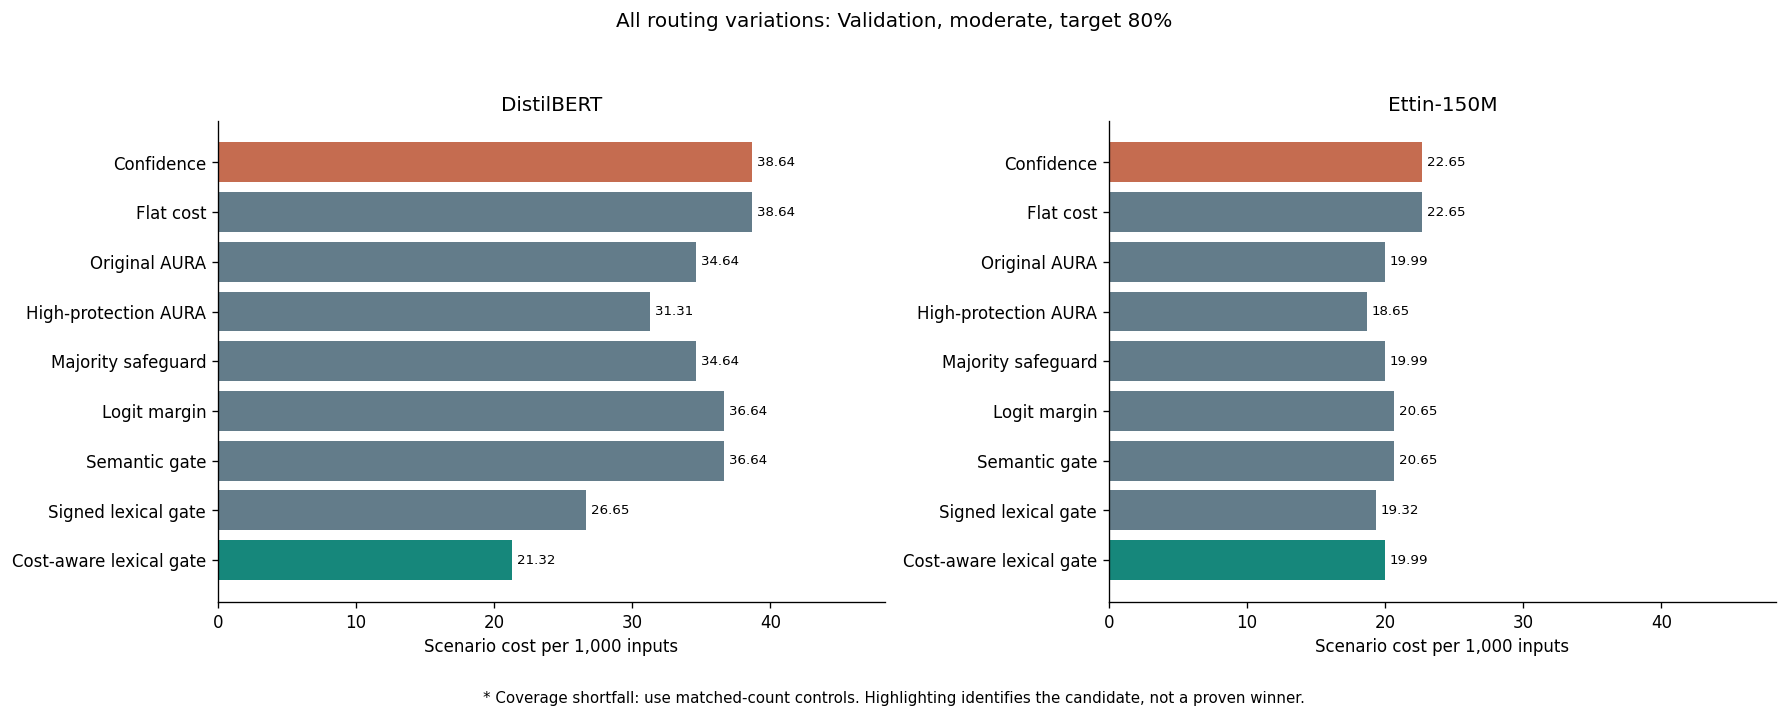

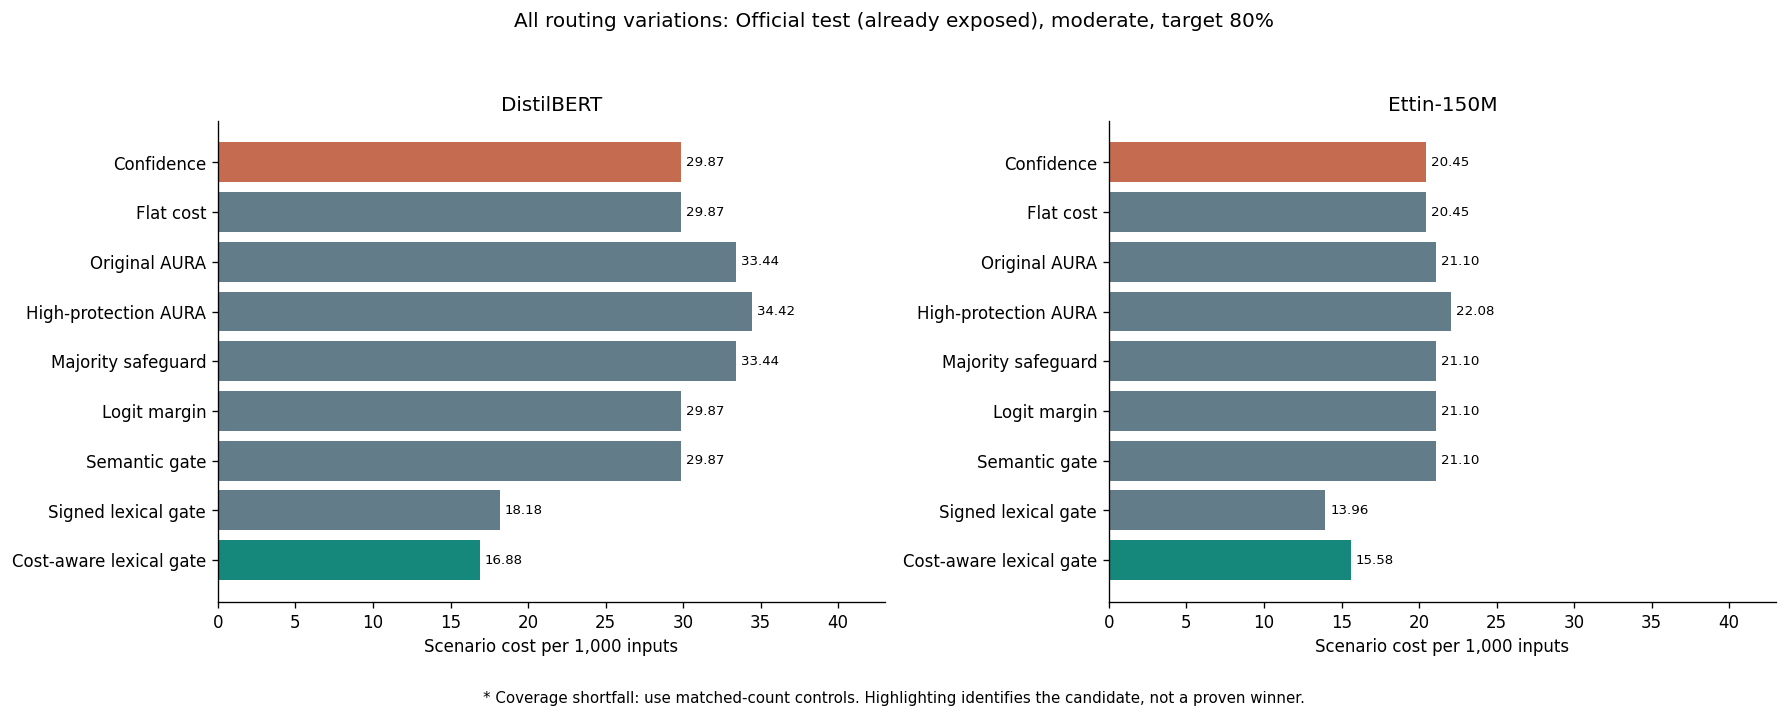

interactive(children=(Dropdown(description='Encoder:', index=1, options=('DistilBERT', 'Ettin-150M'), value='E…

<function __main__.view_routing_evolution(encoder, partition, scenario, coverage)>

In [34]:
from IPython.display import Markdown

EVOLUTION_REPORTS = {"Validation": encoder_validation_report}
if RUN_OFFICIAL_TEST and encoder_test_report is not None:
    EVOLUTION_REPORTS["Official test (already exposed)"] = encoder_test_report

def summarize_routing_variations(report, encoder, scenario, coverage):
    selected = report[(report.encoder == encoder) &
        (report.evaluation_scenario == scenario) & (report.target_coverage == coverage)].copy()
    if selected.empty:
        raise ValueError("No results for the selected encoder, scenario and coverage.")
    references = selected[selected.policy.isin(
        ["confidence", "confidence_guard_matched_count", "confidence_guard_matched"])].copy()
    references["priority"] = np.where(references.policy == "confidence", 0, 1)
    references = references.sort_values("priority").drop_duplicates("accepted_count")
    references = references[["accepted_count", "policy", "accepted_total_cost"]].rename(columns={
        "policy": "reference_policy", "accepted_total_cost": "reference_cost"})
    selected = selected.merge(references, on="accepted_count", how="left", validate="many_to_one")
    selected["coverage_shortfall"] = selected.accepted_count < selected.requested_count
    selected["accepted_error_rate"] = selected.accepted_errors / selected.accepted_count.replace(0, np.nan)
    selected["cost_per_1000_inputs"] = selected.accepted_cost_per_input * 1000
    selected["cost_change_vs_matched_confidence"] = selected.accepted_total_cost - selected.reference_cost
    denominator = selected.reference_cost.where(selected.reference_cost > 0)
    selected["cost_reduction_vs_matched_confidence_pct"] = (
        100 * (selected.reference_cost - selected.accepted_total_cost) / denominator)
    return selected

def variation_markdown_table(frame):
    headings = ["Policy", "Accepted", "Errors", "Cost", "Reference", "Cost change", "Reduction (%)"]
    rows = ["| " + " | ".join(headings) + " |", "|" + "---|" * len(headings)]
    for item in frame.to_dict("records"):
        def number(value):
            return "N/A" if pd.isna(value) else f"{value:.2f}"
        policy = POLICY_LABELS.get(item["policy"], item["policy"])
        if item["coverage_shortfall"]:
            policy += " (shortfall)"
        cells = [policy, str(item["accepted_count"]), str(item["accepted_errors"]),
            number(item["accepted_total_cost"]), str(item["reference_policy"]),
            number(item["cost_change_vs_matched_confidence"]),
            number(item["cost_reduction_vs_matched_confidence_pct"])]
        rows.append("| " + " | ".join(cells) + " |")
    return "\n".join(rows)

def describe_routing_comparison(frame):
    indexed = frame.set_index("policy")
    lines = []
    for candidate, reference in [("original_aura", "confidence"),
        ("signed_gate", "semantic_gate"), ("signed_cost_gate", "signed_gate")]:
        new, old = indexed.loc[candidate], indexed.loc[reference]
        if new.accepted_count != old.accepted_count:
            lines.append(f"{candidate} versus {reference}: acceptance counts differ; do not compare totals directly.")
            continue
        difference = float(new.accepted_total_cost - old.accepted_total_cost)
        direction = "lower" if difference < 0 else "higher" if difference > 0 else "equal"
        lines.append(f"{POLICY_LABELS[candidate]} versus {POLICY_LABELS[reference]}: "
            f"cost {new.accepted_total_cost:g} versus {old.accepted_total_cost:g} "
            f"({direction}; candidate-minus-reference {difference:+g}); accepted errors "
            f"{int(new.accepted_errors)} versus {int(old.accepted_errors)}.")
    return "\n\n".join(lines) + "\n\nThese are observed comparisons, not significance claims or an automatic winner selection."

def plot_variation_history(report, partition, scenario="moderate", coverage=0.8, save=True):
    names = list(ENCODER_ROUTING)
    selected = report[(report.evaluation_scenario == scenario) & (report.target_coverage == coverage)]
    common_limit = max(float(selected.accepted_cost_per_input.max()) * 1000 * 1.25, 1)
    fig, axes = plt.subplots(1, len(names), figsize=(15, 6), squeeze=False, sharex=True)
    for ax, encoder in zip(axes[0], names):
        table = summarize_routing_variations(report, encoder, scenario, coverage)
        table = table[table.policy.isin(POLICY_LABELS)].set_index("policy").reindex(POLICY_LABELS)
        colors = ["#16877b" if p == "signed_cost_gate" else "#c56c50" if p == "confidence"
                  else "#637c8a" for p in table.index]
        bars = ax.barh(np.arange(len(table)), table.cost_per_1000_inputs, color=colors)
        ax.set_yticks(np.arange(len(table)), [POLICY_LABELS[p] +
            (" *" if row.coverage_shortfall else "") for p, row in table.iterrows()])
        ax.invert_yaxis()
        ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=8)
        ax.set_xlim(0, common_limit)
        ax.set(xlabel="Scenario cost per 1,000 inputs", title=encoder)
    fig.suptitle(f"All routing variations: {partition}, {scenario}, target {coverage:.0%}")
    fig.text(.5, .02, "* Coverage shortfall: use matched-count controls. Highlighting identifies the candidate, not a proven winner.",
        ha="center", fontsize=9)
    fig.tight_layout(rect=(0, .06, 1, .94))
    if save:
        suffix = "test" if partition.startswith("Official test") else "validation"
        fig.savefig(RESULT_DIR / f"aura_evolution_{suffix}.png", dpi=180)
    plt.show()

EVOLUTION_SUMMARIES = []
evolution_markdown = ["# AURA Current-Run Variation Comparison", f"Run ID: {RUN_ID}",
    "Research scenario costs only. Historical results are recorded separately; no test-based policy promotion."]
for partition, report in EVOLUTION_REPORTS.items():
    for encoder in ENCODER_ROUTING:
        for scenario in COST_MATRICES:
            for coverage in [0.5, 0.7, 0.8, 0.9, 1.0]:
                table = summarize_routing_variations(report, encoder, scenario, coverage)
                EVOLUTION_SUMMARIES.append(table.assign(result_partition=partition, run_id=RUN_ID))
        table = summarize_routing_variations(report, encoder, "moderate", 0.8)
        evolution_markdown.extend([f"## {partition}: {encoder}, moderate, 80% target",
            variation_markdown_table(table), describe_routing_comparison(table)])
    plot_variation_history(report, partition)
EVOLUTION_SUMMARY = pd.concat(EVOLUTION_SUMMARIES, ignore_index=True)
EVOLUTION_SUMMARY.to_csv(RESULT_DIR / "aura_variation_summary.csv", index=False)
(RESULT_DIR / "aura_variation_comparison.md").write_text("\n\n".join(evolution_markdown), encoding="utf-8")

def view_routing_evolution(encoder, partition, scenario, coverage):
    table = summarize_routing_variations(EVOLUTION_REPORTS[partition], encoder, scenario, coverage)
    columns = ["policy", "accepted_count", "deferred_count", "actual_coverage", "accepted_errors",
        "accepted_error_rate", "accepted_total_cost", "cost_per_1000_inputs", "reference_policy",
        "cost_change_vs_matched_confidence", "cost_reduction_vs_matched_confidence_pct", "coverage_shortfall"]
    display(table[columns])
    display(Markdown(describe_routing_comparison(table)))

widgets.interact(view_routing_evolution,
    encoder=widgets.Dropdown(options=list(ENCODER_ROUTING), value="Ettin-150M", description="Encoder:"),
    partition=widgets.Dropdown(options=list(EVOLUTION_REPORTS), description="Partition:",
        layout=widgets.Layout(width="450px")),
    scenario=widgets.Dropdown(options=list(COST_MATRICES), value="moderate", description="Scenario:"),
    coverage=widgets.SelectionSlider(options=[0.5, 0.7, 0.8, 0.9, 1.0], value=0.8,
        description="Coverage:", continuous_update=False))

### 15B. Keep the exploratory cost-learning pilots separate

The pilot uses filtered development rows, not the main validation population.
Compare its five methods **within one encoder on the same filtered rows**. Its
latest cost-trained regressor is not automatically the best method, and is not
part of the final-test/live policy. Neither pilot result is mixed into the main
comparison or used to select a test winner.

In [35]:
evolution_pilots = []
for encoder, report in [("DistilBERT", pilot_report), ("Ettin-150M", ettin_pilot_report)]:
    if report is not None:
        evolution_pilots.append(report.assign(encoder=encoder, evaluation_population="filtered_development"))
if evolution_pilots:
    EVOLUTION_PILOT_COMPARISON = pd.concat(evolution_pilots, ignore_index=True)
    EVOLUTION_PILOT_COMPARISON.to_csv(RESULT_DIR / "aura_pilot_variation_summary.csv", index=False)
    pilot_80 = EVOLUTION_PILOT_COMPARISON[
        (EVOLUTION_PILOT_COMPARISON.evaluation_scenario == "moderate") &
        (EVOLUTION_PILOT_COMPARISON.target_coverage == 0.8)]
    display(pilot_80)
    for encoder in pilot_80.encoder.unique():
        table = pilot_80[pilot_80.encoder == encoder].set_index("policy")
        candidate, reference = table.loc["cost_ridge"], table.loc["error_ridge"]
        display(Markdown(f"**{encoder}, filtered pilot:** cost-trained versus error-trained Ridge "
            f"has scenario cost {candidate.accepted_total_cost:g} versus {reference.accepted_total_cost:g}. "
            "The target changed; the input features and model family stayed fixed. "
            "A point estimate alone does not establish an improvement."))
else:
    print("Pilot unavailable for this run; no performance values are invented.")

,policy,evaluation_scenario,target_coverage,requested_count,accepted_count,actual_coverage,deferred_count,accepted_errors,accepted_accuracy,accepted_total_cost,accepted_cost_per_input,cost_per_accepted,encoder,evaluation_population
31,error_ridge,moderate,0.8,1200,1200,0.8,300,21,0.982500,40.0,0.026667,0.033333,DistilBERT,filtered_development
34,cost_ridge,moderate,0.8,1200,1200,0.8,300,21,0.982500,40.0,0.026667,0.033333,DistilBERT,filtered_development
37,refit_signed_gate,moderate,0.8,1200,1200,0.8,300,21,0.982500,40.0,0.026667,0.033333,DistilBERT,filtered_development
40,confidence,moderate,0.8,1200,1200,0.8,300,31,0.974167,58.0,0.038667,0.048333,DistilBERT,filtered_development
43,original_aura,moderate,0.8,1200,1200,0.8,300,34,0.971667,53.0,0.035333,0.044167,DistilBERT,filtered_development
106,error_ridge,moderate,0.8,1200,1200,0.8,300,16,0.986667,28.0,0.018667,0.023333,Ettin-150M,filtered_development
109,cost_ridge,moderate,0.8,1200,1200,0.8,300,16,0.986667,28.0,0.018667,0.023333,Ettin-150M,filtered_development
112,refit_signed_gate,moderate,0.8,1200,1200,0.8,300,16,0.986667,29.0,0.019333,0.024167,Ettin-150M,filtered_development
115,confidence,moderate,0.8,1200,1200,0.8,300,17,0.985833,34.0,0.022667,0.028333,Ettin-150M,filtered_development
118,original_aura,moderate,0.8,1200,1200,0.8,300,17,0.985833,30.0,0.020000,0.025000,Ettin-150M,filtered_development


**DistilBERT, filtered pilot:** cost-trained versus error-trained Ridge has scenario cost 40 versus 40. The target changed; the input features and model family stayed fixed. A point estimate alone does not establish an improvement.

**Ettin-150M, filtered pilot:** cost-trained versus error-trained Ridge has scenario cost 28 versus 28. The target changed; the input features and model family stayed fixed. A point estimate alone does not establish an improvement.

In [36]:
(RESULT_DIR / "aura_evolution_history.md").write_text("# AURA Evolution: Changes, Evidence, and Results\n\nTeam: Puspita and Farhat. Updated October 25, 2026.\n\nThis is a record of implemented comparisons, including unsuccessful experiments.\nThe stages describe the development logic, not a claim that every later method\nimproved on every earlier method. The latest implementation is a **cost-aware\nsigned lexical gate**, evaluated with both DistilBERT and Ettin. The plain signed\ngate remains an essential comparator, not an obsolete method to hide.\n\n## 1. What Stayed Fixed\n\nFor an encoder m, let z_m(x) be its 77 logits, T_m its fitted temperature,\np_m = softmax(z_m/T_m), and j_m = argmax p_m its predicted intent. Every routing\nvariation retains j_m; only the AUTO/DEFER decision changes.\n\nThe principal comparisons retain 7,002 training, 1,500 calibration, and 1,501\nvalidation messages; the archived test has 3,080. The cost matrix C has true intents\non rows and predicted routes on columns. Correct predictions cost zero. Other\ncosts follow the declared maximum-floor scenarios, not measured bank losses.\n\nAll ordinary policies accept floor(cN) messages at target coverage c, with row-ID\ntie breaking. The majority guard can fall short and requires matched-count controls.\nLabels evaluate accepted errors and cost only after selection; they are not inputs\nto routing scores. Accepted costs exclude human-review cost and reviewer error.\n\n## 2. Why Each Variation Was Added\n\n### Preparation: calibrate the classifier\n\nFit one positive T per encoder by calibration-set negative log likelihood. This\nadjusts probability sharpness without changing its argmax. Temperature scaling\nfollows [Guo et al., ICML 2017](https://proceedings.mlr.press/v70/guo17a.html).\nIt does not guarantee optimal routing or improve every calibration metric.\n\n### Baseline and first AURA\n\nConfidence ranks by -max(p_m). Flat-cost AURA uses C[i,j]=1 for every i!=j,\nso its expected risk equals 1-max(p_m); it is a control, not a new contribution.\n\nOriginal AURA instead ranks by R_m(x)=sum_i p_m(i|x) C[i,j_m], allowing differently\ncosted errors to affect rejection. Conditional-risk ranking and bounded-coverage\nselection have a theoretical basis in [Franc, Prusa and Voracek, JMLR 2023](https://www.jmlr.org/papers/v24/21-0048.html).\nOur plug-in probabilities and fixed argmax do not inherit Bayes-optimal guarantees.\nThe banking workflow map, maximum-floor aggregation and numeric penalties are our\nresearch assumptions; that article does not establish them.\n\n### Sensitivity branch: high-protection AURA\n\nKeep the rule and model but increase the penalties for omitted protective work.\nThis asks whether conclusions depend on the assumed consequences. It is not\nanother learned model, nor evidence that larger penalties are more realistic.\nThe flat/moderate/high scenarios are project-defined sensitivity checks, not\npublished bank-loss estimates or values supplied by a paper.\n\n### Safeguard branch: majority-confidence guard\n\nBefore ranking by moderate risk, require max(p_m)>0.5. The predicted class then\nhas more probability mass than all alternatives combined. This was our structural\nexperiment, not a threshold obtained from a banking study. It does not backfill\nwith ineligible messages. A lower total from accepting fewer requests is not a\nmatched-coverage improvement. The development regression motivated this check,\nbut its results did not justify promoting it as a fix.\n\n### Controls: raw logit margin and semantic-only gate\n\nThe margin is z_(1)-z_(2), the difference between the largest two logits. It tests\nwhether a simple non-probability ranking explains a gain. A one-feature logistic\ngate learns correctness from this margin. [Liang, Peng and Sun, TMLR 2024](https://arxiv.org/abs/2405.05160)\nmotivates margin controls; our raw top-two gap is not an implementation of all their\nproposed scores and does not demonstrate banking distribution-shift robustness.\n\n### Complementary evidence: signed lexical gate\n\nTrain a separate word/character TF-IDF + SVM witness on training rows. For the\nencoder's fixed prediction j, its signed support is d_j-max_{k!=j} d_k, where d\ncontains witness decision scores. A two-feature standardized logistic gate learns\ncorrectness from the semantic margin and this support; q_m is its error estimate.\n\nThis adapts [Cheng, Yang and Lin, Signed Lexical Confidence for Risk-Calibrated\nIntent Routing, September 2026 preprint](https://arxiv.org/abs/2610.00262).\nIt is a preprint, not a verified peer-reviewed publication. We do not implement its\nindependent binomial risk-calibration stage or claim its guarantees.\n\n### Latest cost-aware candidate: signed cost gate\n\nDecompose original risk into error mass and conditional severity:\n\n```text\na_m(x) = sum_{i != j_m} p_m(i|x)\ns_m(x) = R_m(x) / a_m(x)\noriginal risk = a_m(x) * s_m(x)\ncost-aware gate score = q_m(x) * s_m(x)\n```\n\nThis replaces the classifier's error-mass estimate with the learned gate estimate,\nwhile retaining its relative probability allocation among alternative intents.\nIt is our cost-sensitive adaptation, not a cost formula established by Cheng et al.\nThe gate is not independently probability-calibrated, so this remains a ranking\nproxy. Flat unit costs recover q_m; q_m=a_m recovers original AURA.\n\n### Post-test exploratory branch: direct-cost learning\n\nFit two matched standardized Ridge regressors: error target 0/1 versus observed\nmoderate cost divided by its fixed maximum. Both use the same two routing features.\nUse a refitted signed gate and confidence/original AURA as controls on identical\nfiltered rows. This tests a project-specific hypothesis inspired by conditional-risk\nlearning, not a reproduction of Franc et al.'s algorithms. Ridge alpha=1 is a fixed\nlibrary-default research choice, not a banking-derived value.\n\nRemove training-text overlap for this pilot only: 1,499 fitting and 1,500 validation\nrows. Outputs are unbounded ranking scores, not probabilities. No pilot selector\nis used on test data or promoted to the live demo.\n\n### Current extension: AURA on Ettin as well as DistilBERT\n\nKeep the same costs, partitions and budgets but fit each encoder's own temperature\nand gates. The independent training-only witness can be shared. [Weller et al.,\nSeq vs Seq, 2025 manuscript, accepted ICLR 2026](https://arxiv.org/abs/2507.11412)\nprovides the Ettin model basis, not evidence of a gain in our routing experiment.\nCompare Ettin+AURA against Ettin+confidence, not only DistilBERT+confidence:\notherwise classifier gains and routing gains are confounded. Actual new-run\nperformance is computed by the notebook, not copied from historical results.\n\n## 3. Recorded Performance: Archived DistilBERT Only\n\nAll costs below use the same **moderate evaluation scenario at 80% target coverage**.\nDevelopment accepts 1,200 of 1,501 messages; test accepts 2,464 of 3,080.\nThis table must not be relabelled as Ettin or as a newly retrained DistilBERT run.\n\n| Variation | Development errors | Development cost | Test errors | Test cost |\n|---|---:|---:|---:|---:|\n| Confidence | 29 | 56 | 63 | 95 |\n| Flat-cost control | 29 | 56 | 63 | 95 |\n| Original AURA | 35 | 59 | 76 | 108 |\n| High-protection ranking | 34 | 52 | 79 | 110 |\n| Majority guard | 35 | 59 | 76 | 108 |\n| Logit margin | 30 | 57 | 69 | 110 |\n| Semantic-only gate | 30 | 57 | 69 | 110 |\n| Signed lexical gate | 22 | 46 | 39 | 62 |\n| Cost-aware signed gate | 20 | 33 | 40 | 60 |\n\nThese totals come from the saved original, guarded, lexical, and final-comparison\nCSV artifacts, not from the papers. Validation informed subsequent experiments,\nso the table is a development history, not nine independent confirmatory findings.\n\nOriginal AURA helped at 70% development coverage (confidence 29 versus AURA 21)\nbut regressed at 80% (56 versus 59). The majority guard did not change acceptance\nat development coverages 50-90%; at a 100% target it reached only 96.27% coverage.\nThe signed gate and cost extension were therefore evaluated rather than treating\nthe guard as a solved improvement.\n\nAt 80% development coverage, the signed cost gate reduced cost from 59 to 33\nversus original AURA (44.1%) and from 46 to 33 versus the plain signed gate (28.3%).\nOn test, its 60 versus confidence's 95 is a descriptive 36.8% reduction. But the\nprimary test contrast was **60 versus 62 against the plain signed gate**, with\n40 rather than 39 accepted errors. Its cost difference per 1,000 inputs was\n-0.65, with paired 95% interval [-5.19, +1.62]. This is inconclusive, not proof of\nan added cost-awareness benefit and not evidence that the methods are equivalent.\n\nThe plain signed gate also has lower test cost at 70% and 90% coverage and ties at\n50%. There is no uniformly best variation. Multi-coverage evaluation is motivated\nby [Traub et al., NeurIPS 2024](https://proceedings.nips.cc/paper_files/paper/2024/file/047c84ec50bd8ea29349b996fc64af4b-Paper-Conference.pdf).\nWe report the existing coverage grid; this notebook does not compute AUGRC.\n\n## 4. Pilot Results Must Stay Separate\n\nOn the pilot's 1,500 filtered validation messages at 80% coverage, both error-trained\nRidge and cost-trained Ridge had 21 accepted errors and cost 43. The refitted signed\ngate cost 46, confidence 56, and original AURA 59. The cost-versus-error Ridge\ndifference was zero with interval [-4,+2] per 1,000 inputs. Thus this pilot did not\nestablish an extra benefit from directly learning the cost target. Equal totals\ndo not imply equal acceptance sets. Do not merge it with the 1,501-row table.\n\n## 5. What the Final Implementation Means\n\nThe implemented research candidate is the cost-aware signed gate; the plain signed\ngate remains the strongest necessary control for its cost-specific contribution.\nEttin adds a second encoder experiment, not automatic evidence of a breakthrough.\nThe notebook's closing section computes current-run comparisons for both encoders,\nall nine policies, guard controls, all three scenarios and five coverages, and\nexports performance summaries with observed improvements and regressions.\n\nThe latest code is not automatically the empirical winner. Do not select a winner\nfrom the inspected test and then describe it as a prespecified confirmation.\nCosts, workflows, duplicate overlap, reused development data, fitting uncertainty,\nand unknown human-review outcomes remain limitations. Published methods motivate\nthe experiments; they do not validate our chosen costs or guarantee these results.\n\n## Evidence Files\n\n- `artifacts/policies/distilbert/comparison.csv`: confidence/flat/original/high.\n- `artifacts/policies/guarded_distilbert/comparison.csv`: guard and matched controls.\n- `artifacts/policies/lexical_distilbert/comparison.csv`: margin and learned gates.\n- `artifacts/final_evaluation/aura-final-evaluation-v1/comparison.csv` and\n  `primary_result.json`: archived test comparison and primary uncertainty.\n- `artifacts/exploratory/learned_cost_v1/comparison.csv` and `intervals.csv`: pilot.\n\nNew Colab outputs retain their own run ID and encoder/checkpoint identity. None of\nthese historical artifacts is overwritten by the closing comparison section.\n", encoding="utf-8")
print("Comparison reports and charts are saved. The next cell can include them in the result ZIP.")

Comparison reports and charts are saved. The next cell can include them in the result ZIP.


## 16. Save results and prepare for presenting

The run directory contains the actual computed metrics, routing decisions, plots,
configuration, and temperature. Saved model checkpoints stay in the checkpoint
directory for reuse. Enable Google Drive before the preparation run to preserve
them across Colab sessions.

For the live presentation, load the completed checkpoints, show the classifier
and routing plots, and change a demo message. The optional ZIP below contains
result tables and figures, not the large model checkpoints. No results should be
described as monetary savings, verified customer harm, or guaranteed safe routing.

In [37]:
summary = {"run_id": RUN_ID, "signature": SIGNATURE, "versions": VERSIONS,
    "configuration": TRAINING_CONFIG, "device": str(DEVICE),
    "ettin_configuration": ETTIN_CONFIG, "ettin_signature": ETTIN_SIGNATURE,
    "historical_aura_base_classifier": "DistilBERT",
    "aura_base_classifiers": list(ENCODER_ROUTING),
    "variation_comparison": {"summary": "aura_variation_summary.csv",
        "current_run_report": "aura_variation_comparison.md",
        "cited_history": "aura_evolution_history.md"},
    "encoder_routing": {name: {"temperature": state["temperature"],
        "checkpoint_sha256": state["checkpoint_sha256"]} for name, state in ENCODER_ROUTING.items()},
    "routing_policies": list(POLICY_LABELS), "bootstrap_resamples": BOOTSTRAP_RESAMPLES,
    "distilbert_checkpoint_sha256": DISTILBERT_CHECKPOINT_HASH,
    "additional_temperatures": EXTRA_TEMPERATURES,
    "test_primary_interval": test_primary_interval, "pilot_available": pilot_available,
    "partitions": {"training": len(train_df), "calibration": len(cal_df), "validation": len(val_df)},
    "temperature": TEMPERATURE, "cost_unit": "relative_research_cost",
    "workflow_specification": PROJECT_SPEC["workflow_specification"]["specification_id"],
    "test_overlap_summary": test_summary,
    "demo_threshold_basis": "validation-derived illustrative cutoff; not exact-budget evaluation",
    "demo_risk_cutoff": FROZEN_RISK_CUTOFF,
    "demo_confidence_cutoff": FROZEN_CONFIDENCE_CUTOFF,
    "training_or_loading": training_records}
(RESULT_DIR / "summary.json").write_text(json.dumps(summary, indent=2))
(RESULT_DIR / "workflow_and_cost_specification.json").write_text(json.dumps({
    "workflows": PROJECT_SPEC["workflow_specification"],
    "scenarios": PROJECT_SPEC["scenario_specification"]}, indent=2))
pd.DataFrame(training_history).to_csv(RESULT_DIR / "distilbert_training_history.csv", index=False)
pd.DataFrame(ettin_history).to_csv(RESULT_DIR / "ettin_training_history.csv", index=False)
demo_results.to_csv(RESULT_DIR / "demo_messages.csv", index=False)
print("Results:", RESULT_DIR)
print("Reusable model checkpoints:", CHECKPOINT_DIR)
print("Ettin checkpoint:", ETTIN_MODEL_DIR)

DOWNLOAD_RESULTS = False  # Set True to download tables, figures and run metadata.
if DOWNLOAD_RESULTS:
    archive = shutil.make_archive(str(RESULT_DIR), "zip", root_dir=RESULT_DIR)
    from google.colab import files
    files.download(archive)

Results: /content/drive/MyDrive/AURA_Colab_Demo/runs/20261026T233822598428Z
Reusable model checkpoints: /content/drive/MyDrive/AURA_Colab_Demo/checkpoints/651a2d9e08afced1
Ettin checkpoint: /content/drive/MyDrive/AURA_Colab_Demo/checkpoints/651a2d9e08afced1/ettin/49d86a964615c15b


### 16B. Export every trained model, fitted AURA layer and this run's results

Run this **after section 16**, with both encoders and their routing layers prepared.
If the Colab session restarted, first restore the compatible checkpoints with
`USE_GOOGLE_DRIVE = True` and `REUSE_CHECKPOINTS = True` and execute preparation.
Saved notebook outputs alone do not restore Python objects.

Upload **`aura_demo_package.py`** and **`aura_demo_ui.py`** when prompted. This cell
creates a dedicated folder **and one ZIP** under:

```text
/content/drive/MyDrive/AURA_Colab_Demo/exports/aura-demo-<run-id>-<export-time>/
├── models/          # fine-tuned DistilBERT + Ettin/tokenizers; LR + RF
├── routing/         # shared witness; separate gates, temperatures, validation scores
├── results/         # this run's complete CSV/NPZ/figure/report directory
├── aura_project_spec.json
├── package.json    # matching checkpoint identities and run provenance
├── environment.json
├── manifest.json   # SHA-256 integrity checks
├── requirements.txt
├── aura_demo_ui.py
├── aura_demo_package.py
└── START_HERE.md
```

No fitting or new official-test evaluation occurs during export. All nine saved
validation scoring rules are replayed to check consistency before copying.
Earlier run directories remain untouched. The package contains this run's
results, not a new merge of every historical experiment/checkpoint.

Keep `CREATE_PACKAGE_ZIP = True`. Set `DOWNLOAD_PACKAGE = True` to trigger a browser
download, or download the completed ZIP from Drive. It includes both encoders'
weights, so it is much larger than the earlier results-only ZIP. Copies remain
in Drive when Drive storage is enabled; without Drive they are temporary.

Later unzip into **`AURA/artifacts/demo_packages/`** on your Mac. Inside the
extracted folder, install `requirements.txt` in a dedicated environment, then run:

```bash
python aura_demo_package.py --package .
```

Open `http://127.0.0.1:7860`. This reads the saved models locally without Colab,
retraining or model downloads. Model fitting and inference still use the
documented research assumptions; packaging does not improve reported performance.

In [ ]:
import importlib.util
import sys

for filename in ["aura_demo_ui.py", "aura_demo_package.py"]:
    if not Path(filename).is_file():
        try:
            from google.colab import files
        except ImportError as exc:
            raise FileNotFoundError(f"Place {filename} beside this notebook.") from exc
        print(f"Upload {filename} (both Python files can be selected together).")
        files.upload()
    if not Path(filename).is_file():
        raise FileNotFoundError(f"Expected {filename}.")
    module_name = Path(filename).stem
    spec = importlib.util.spec_from_file_location(module_name, filename)
    if spec is None or spec.loader is None:
        raise ImportError(f"Cannot load {filename}.")
    uploaded_module = importlib.util.module_from_spec(spec)
    sys.modules[module_name] = uploaded_module
    spec.loader.exec_module(uploaded_module)

CREATE_PACKAGE_ZIP = True
DOWNLOAD_PACKAGE = False  # True downloads the completed ZIP through the browser.
EXPORT_NAME = "aura-demo-" + RUN_ID + "-" + datetime.now(timezone.utc).strftime("%H%M%S%f")
EXPORT_DIR = STORAGE_ROOT / "exports" / EXPORT_NAME
package_module = sys.modules["aura_demo_package"]
PACKAGE_FOLDER, PACKAGE_ZIP = package_module.export_notebook_package(
    globals(), EXPORT_DIR, create_zip=CREATE_PACKAGE_ZIP)
print("Portable folder:", PACKAGE_FOLDER)
print("Downloadable ZIP:", PACKAGE_ZIP)
print("Later unzip into: AURA/artifacts/demo_packages/")
if DOWNLOAD_PACKAGE:
    if PACKAGE_ZIP is None:
        raise ValueError("Set CREATE_PACKAGE_ZIP = True to download a ZIP.")
    from google.colab import files
    files.download(str(PACKAGE_ZIP))

### 16C. Download an already-saved export directly, without retraining

**Run only the next cell.** It mounts Drive, reads the existing export's manifest,
verifies every file, and creates one ZIP with a browser download. It needs no GPU,
model loading, training, previous notebook variables or additional Python uploads.

The source is the export already saved in Drive, not the incomplete local download.
Keep `EXPORT_FOLDER_NAME` set to the run you want. The original files stay untouched.
If Drive itself is missing a file or a hash differs, the cell lists the problem and
refuses to publish an incomplete ZIP. That error does not mean training must be rerun.

Wait for **“ZIP ready”** and for the browser download to finish. Extract the resulting
`-verified` folder into **`AURA/artifacts/demo_packages/`**. Keep this new folder separate
from the earlier partial download. If the browser download is blocked, the same single
verified ZIP is saved under `MyDrive/AURA_Colab_Demo/downloads/` for direct download.

In [ ]:
"""Create a verified download from an existing Drive export, without model loading."""

import hashlib
import json
import zipfile
from pathlib import Path


def create_verified_download(source: str | Path, destination: str | Path) -> Path:
    """Verify every declared file while writing one ZIP; reject incomplete exports."""
    source = Path(source).resolve()
    destination = Path(destination).resolve()
    manifest_path = source / "manifest.json"
    if not manifest_path.is_file():
        raise FileNotFoundError(f"No saved export manifest in {source}.")
    manifest_bytes = manifest_path.read_bytes()
    manifest = json.loads(manifest_bytes)
    if manifest.get("schema_version") != 1 or not manifest.get("file_sha256"):
        raise ValueError("The saved export has an unsupported or empty manifest.")
    expected = manifest["file_sha256"]
    missing = []
    for relative in expected:
        path = source / relative
        if source not in path.resolve().parents:
            raise ValueError(f"Invalid export file path: {relative}")
        if not path.is_file():
            missing.append(relative)
    if missing:
        raise FileNotFoundError(
            f"The Drive export itself is incomplete: {len(missing)} of {len(expected)} "
            "files are missing. No ZIP was created. Missing files:\n" + "\n".join(missing)
        )
    partial = destination.with_name(destination.name + ".partial")
    if destination.exists() or partial.exists():
        raise FileExistsError("Choose a new ZIP filename; previous downloads are preserved.")
    destination.parent.mkdir(parents=True, exist_ok=True)
    folder_name = source.name + "-verified"
    print(f"Found all {len(expected)} files. Verifying and archiving them…", flush=True)
    try:
        # Use a low compression level to reduce download size without a long
        # compression pass. A temporary suffix prevents downloading a partial ZIP.
        with zipfile.ZipFile(
            partial, "x", compression=zipfile.ZIP_DEFLATED, compresslevel=1, allowZip64=True
        ) as archive:
            for index, (relative, wanted) in enumerate(sorted(expected.items()), start=1):
                path = source / relative
                if path.stat().st_size > 50_000_000 or index % 15 == 0:
                    print(f"[{index}/{len(expected)}] {relative}", flush=True)
                digest = hashlib.sha256()
                with (
                    path.open("rb") as incoming,
                    archive.open(f"{folder_name}/{relative}", "w", force_zip64=True) as outgoing,
                ):
                    for block in iter(lambda: incoming.read(1024 * 1024), b""):
                        digest.update(block)
                        outgoing.write(block)
                if digest.hexdigest() != wanted:
                    raise ValueError(
                        f"Saved Drive file differs from its manifest: {relative}. "
                        "No downloadable ZIP was published."
                    )
            if manifest_path.read_bytes() != manifest_bytes:
                raise ValueError(
                    "The export manifest changed while copying. Retry once it is stable."
                )
            archive.writestr(f"{folder_name}/manifest.json", manifest_bytes)
        partial.rename(destination)
    except BaseException:
        partial.unlink(missing_ok=True)
        raise
    print(f"Verified {len(expected)}/{len(expected)} files. ZIP ready: {destination}", flush=True)
    return destination


from datetime import datetime, timezone
from google.colab import drive, files

drive.mount("/content/drive")
DRIVE_ROOT = Path("/content/drive/MyDrive/AURA_Colab_Demo")
EXPORT_FOLDER_NAME = "aura-demo-20261102T173046496634Z-181716275116"
SAVED_EXPORT = DRIVE_ROOT / "exports" / EXPORT_FOLDER_NAME
if not SAVED_EXPORT.is_dir():
    available = sorted(p.parent.name for p in (DRIVE_ROOT / "exports").glob("*/manifest.json"))
    raise FileNotFoundError(
        f"Export folder not found: {SAVED_EXPORT}. "
        f"Available exports: {available}. Update EXPORT_FOLDER_NAME to one of these."
    )
DOWNLOAD_STAMP = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
VERIFIED_ZIP = DRIVE_ROOT / "downloads" / f"{EXPORT_FOLDER_NAME}-{DOWNLOAD_STAMP}-verified.zip"
VERIFIED_ZIP = create_verified_download(SAVED_EXPORT, VERIFIED_ZIP)
print(f"Download size: {VERIFIED_ZIP.stat().st_size / (1024 ** 3):.2f} GiB")
print("Starting the browser download. Keep this Colab tab open until it finishes.")
files.download(str(VERIFIED_ZIP))

## References and implementation provenance

- **Dataset:** Casanueva et al. (2020), [Efficient Intent Detection with Dual Sentence Encoders](https://aclanthology.org/2020.nlp4convai-1.5/); [original data](https://github.com/PolyAI-LDN/task-specific-datasets/tree/master/banking_data).
- **Random Forest method:** Breiman (2001), [Random Forests](https://www.stat.berkeley.edu/~breiman/randomforest2001.pdf). The SVD size and tree count are our configuration choices.
- **DistilBERT:** Sanh et al. (2019), [DistilBERT](https://arxiv.org/abs/1910.01108); [Hugging Face implementation](https://huggingface.co/docs/transformers/model_doc/distilbert).
- **Ettin:** [Seq vs Seq: An Open Suite of Paired Encoders and Decoders (2025)](https://arxiv.org/abs/2507.11412); [official Ettin-150M encoder](https://huggingface.co/jhu-clsp/ettin-encoder-150m). An additional fine-tuned classifier comparison, using the supported ModernBERT sequence-classification architecture.
- **Temperature scaling:** Guo et al. (2017), [On Calibration of Modern Neural Networks](https://proceedings.mlr.press/v70/guo17a.html).
- **Evaluation context:** Traub et al. (2024), [Overcoming Common Flaws in the Evaluation of Selective Classification Systems](https://arxiv.org/abs/2407.01032). Multiple coverage levels are shown; AUGRC is not implemented here.
- **Recent calibration context:** Qian et al. (2025), [Extending Temperature Scaling with Homogenizing Maps](https://jmlr.org/papers/v26/24-0700.html). Related work only; the extension is not implemented.
- **AURA specification:** `aura_project_spec.json` contains copies of `config/intent_workflows.yaml`, `config/consequence_scenarios.yaml`, and the fixed development split from this project. Workflow flags, cost ratios, and maximum-floor aggregation remain research assumptions.

The notebook follows the existing model, temperature, consequence, and coverage
implementations, with notebook progress displays, checkpoint reuse, and an explicitly
separate illustrative live-message threshold. It now includes the lexical routing variants, guard controls, paired uncertainty,
and development-only learned-cost pilot. New run results should be identified separately from archived project results.

- **Lexical routing context:** [Cheng et al., Signed Lexical Confidence for Risk-Calibrated Intent Routing (2026 preprint)](https://arxiv.org/abs/2610.00262). The notebook adapts the two-feature gate but does not implement independent binomial risk certification.
- **Margin control:** [Liang et al., Selective Classification Under Distribution Shifts (TMLR 2024)](https://arxiv.org/abs/2405.05160). No banking distribution-shift guarantee is inferred.
- **Direct-cost pilot:** project-specific exploratory comparison of matched Ridge selectors; not a published safety guarantee.